In [1]:
import pulp as plp
import matplotlib.pyplot as plt
from itertools import product

In [2]:
comprimentos_palete = [8, 50, 50]
larguras_palete = [6, 50, 40]

comprimentos_caixa = [3, 5, 7]
larguras_caixa = [2, 4, 6]

In [3]:
indice = 1
palete_comprimento = comprimentos_palete[indice]
palete_largura = larguras_palete[indice]

caixa_comprimento = comprimentos_caixa[indice]
caixa_largura = larguras_caixa[indice]

print(f"Dimensões do palete: {palete_comprimento}x{palete_largura}")
print(f"Dimensões da caixa: {caixa_comprimento}x{caixa_largura}")

Dimensões do palete: 50x50
Dimensões da caixa: 5x4


In [4]:
dimensoes_palete = [palete_comprimento, palete_largura] #lista
L,W = sorted(dimensoes_palete, reverse=True)
print(f"Dimensões classificadas do palete: {L}x{W}")

Dimensões classificadas do palete: 50x50


In [5]:
dimensoes_caixa = [caixa_comprimento, caixa_largura] #lista
l_um,w_um = sorted(dimensoes_caixa, reverse=True) # caixa deitada
print(f"Dimensões classificadas do caixa deitada: {l_um}x{w_um}")

Dimensões classificadas do caixa deitada: 5x4


In [6]:
l_dois, w_dois = dimensoes_caixa[::-1]
print(f"Dimensões classificadas do caixa em pé: {l_dois}x{w_dois}")

Dimensões classificadas do caixa em pé: 4x5


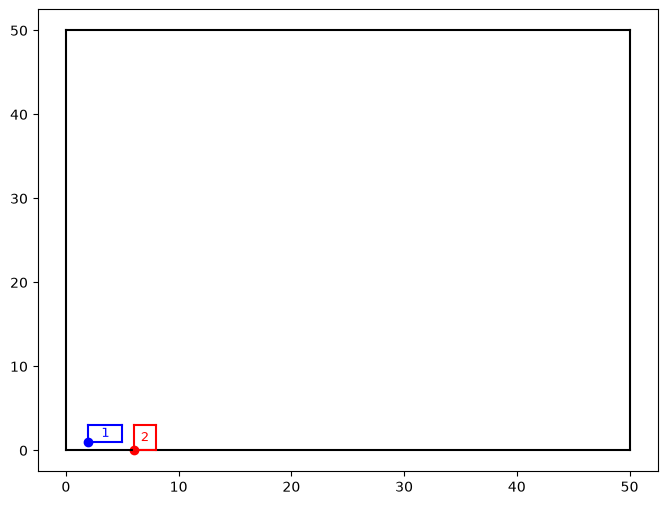

In [7]:
def plotar_caixa(bottom_left: list,
                l: int,
                w: int,
                color: str,
                label: str):
    x0, y0 = bottom_left
    plt.scatter(x=x0 ,y=y0, color=color)
    plt.plot([x0, x0+l], [y0, y0], color=color)
    plt.plot([x0, x0], [y0, y0+w], color=color)
    plt.plot([x0, x0 + l], [y0 + w, y0 + w], color=color)
    plt.plot([x0 + l, x0 + l], [y0, y0 + w], color=color)
    plt.text(x=x0+l/2, y=y0 + w/2, s=label, color=color,
             fontsize=9, ha="center", va="center")

def plotar_palete(L:int, W:int):
    plt.figure(figsize=(8,6))
    plt.plot([0,L], [0,0],"k")
    plt.plot([0,0], [0,W],"k")
    plt.plot([0,L], [W,W],"k")
    plt.plot([L,L], [0,W],"k")
    
plotar_palete(L,W)
plotar_caixa(bottom_left=[2,1], l=3, w=2, color="blue", label="1")
plotar_caixa(bottom_left=[6,0], l=2, w=3, color="red", label="2")

In [8]:
f_um = lambda n_um, l_um, n_dois, l_dois:\
    n_um * l_um + n_dois * l_dois

f_dois = lambda n_um, w_um, n_dois, w_dois:\
    n_um * w_um + n_dois * w_dois


In [9]:
print(f_um(n_um=1, l_um=3, n_dois=2, l_dois=2))

7


In [10]:
print(f_um(n_um=0, l_um=3, n_dois=3, l_dois=2))

6


In [11]:
print(f_um(n_um=2, l_um=3, n_dois=1, l_dois=2))

8


In [12]:
print(f_um(n_um=1, l_um=3, n_dois=2, l_dois=2)) # uma caixa em pé p=7  # p <= L - w_um

7


In [13]:
print(f_dois(n_um=2, w_um=2, n_dois=0, w_dois=3)) # q=4 # q <= W = w_um

4


C:\Users\Guilherme Roque\AppData\Local\Temp\ipykernel_5840\3910285793.py:16: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(8,6))


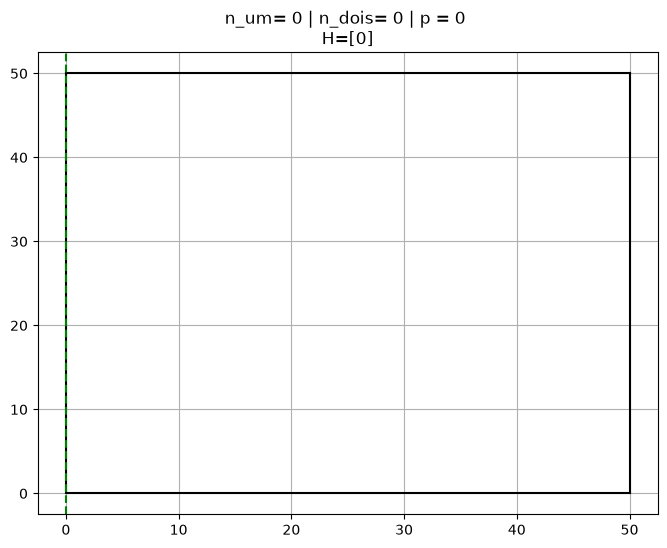

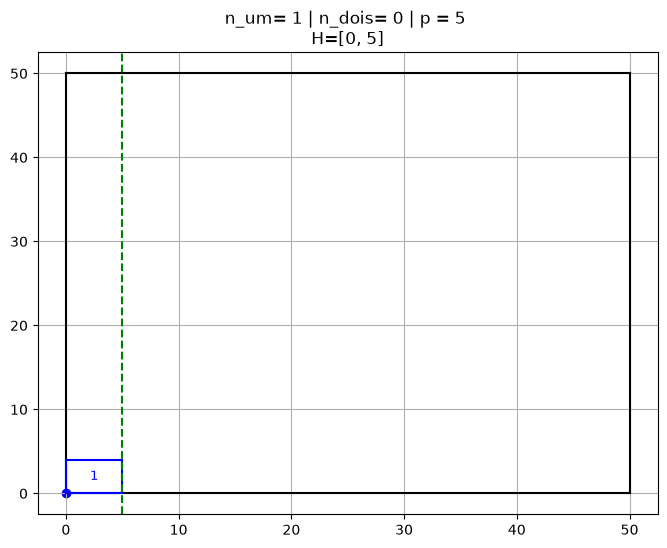

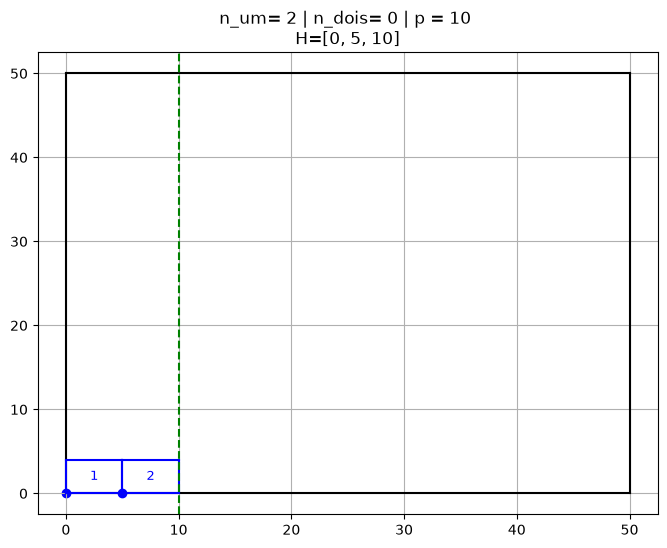

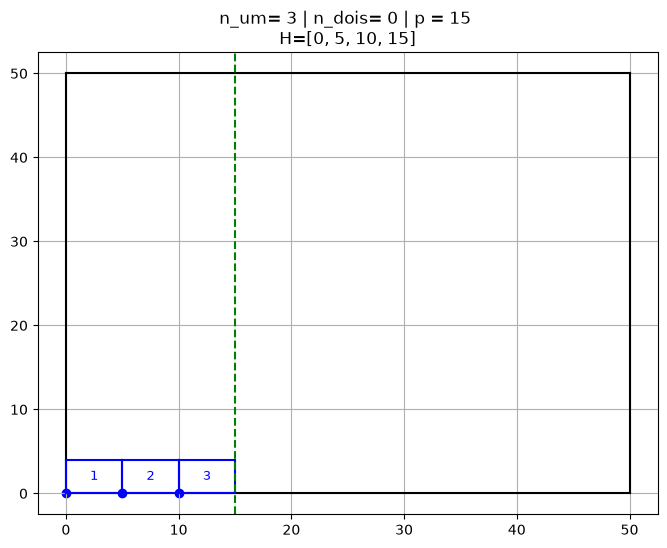

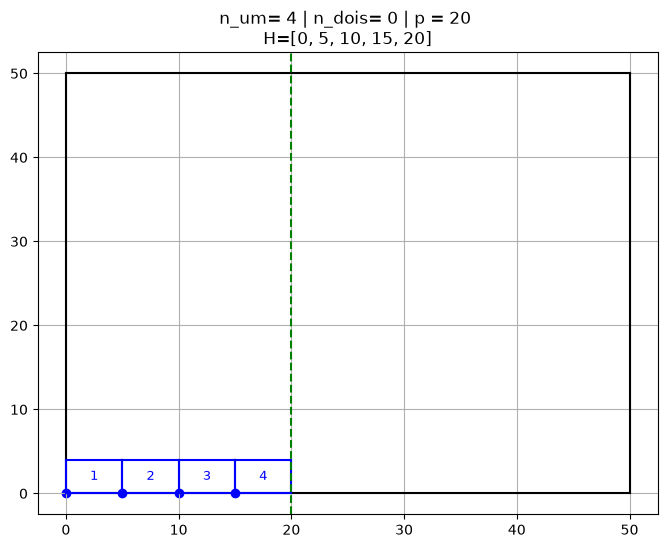

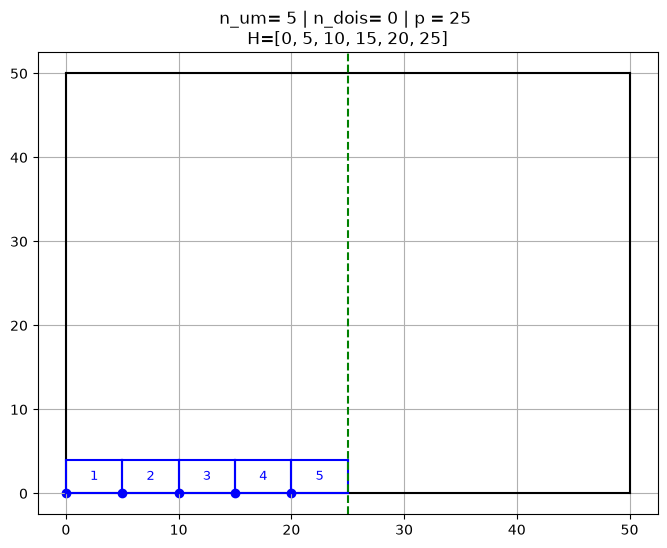

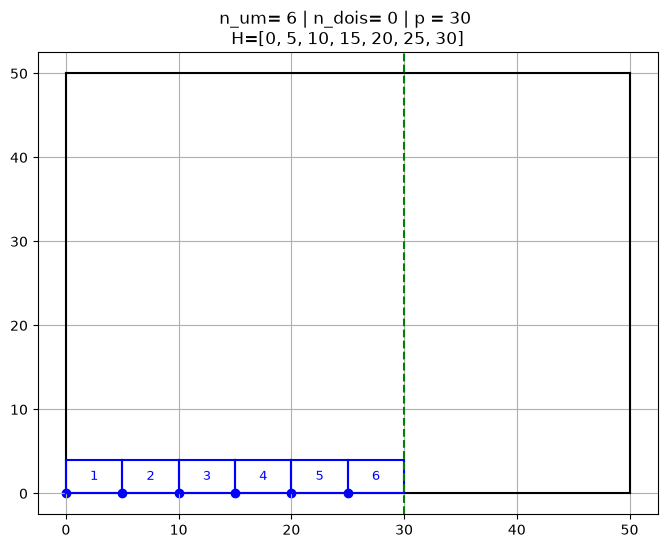

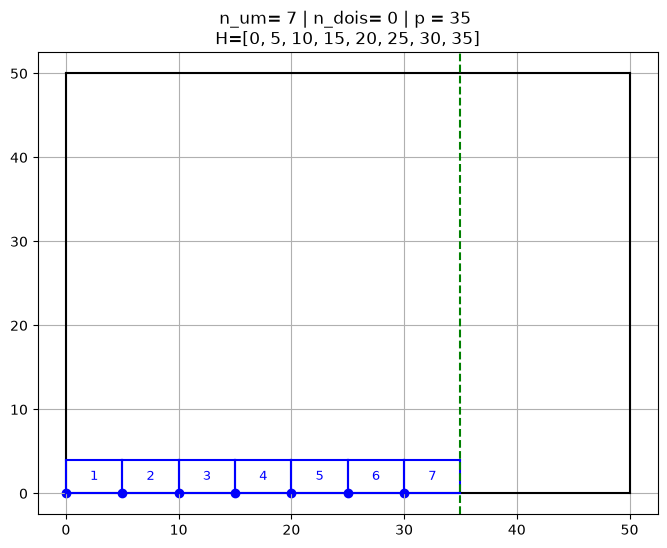

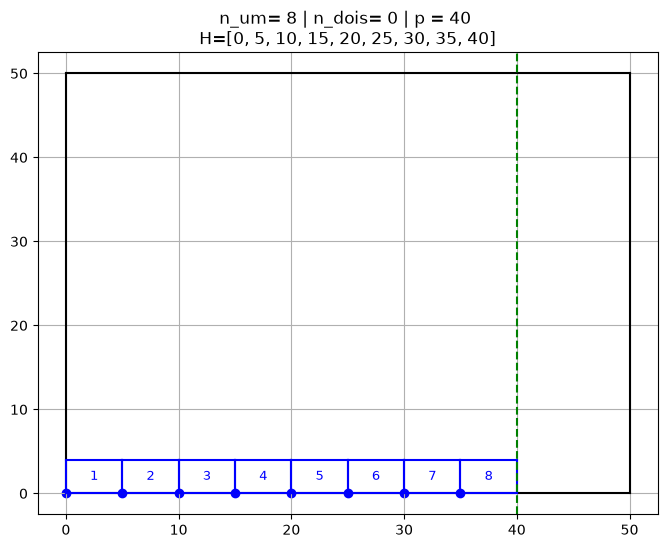

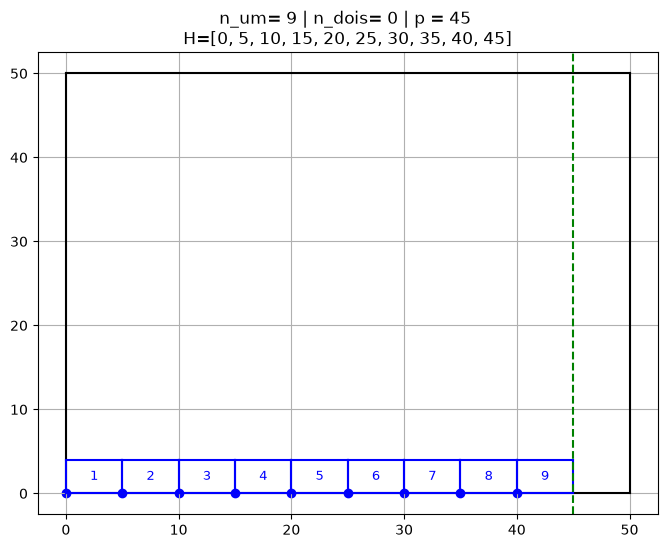

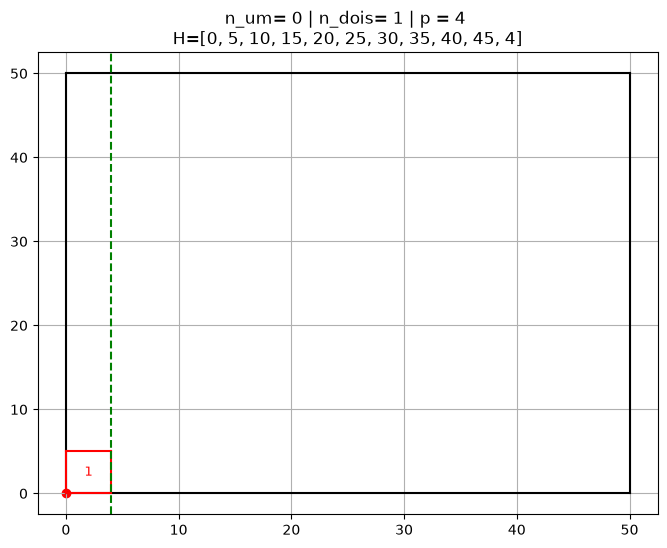

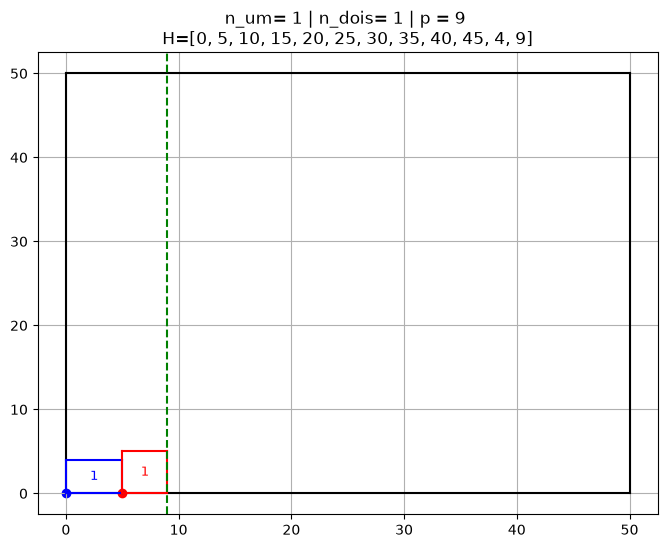

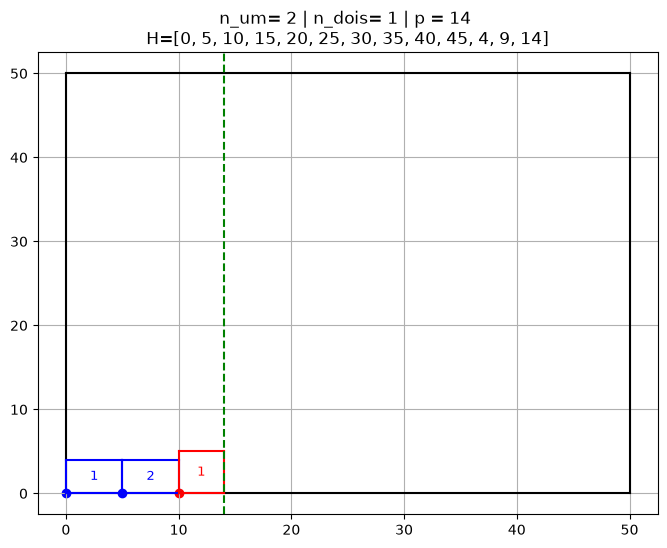

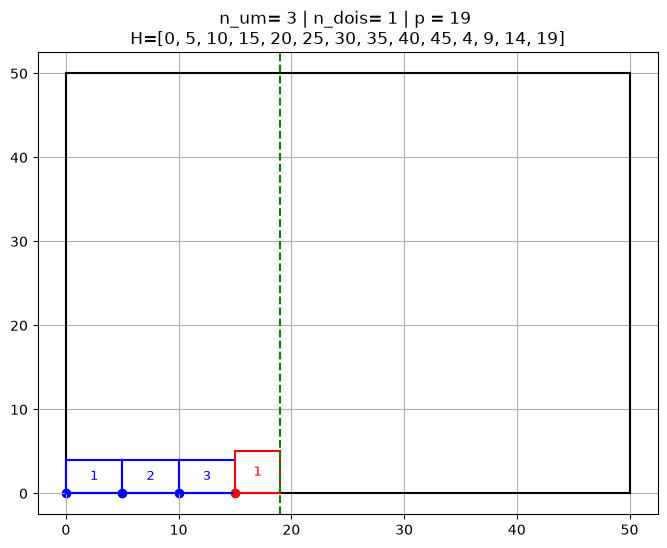

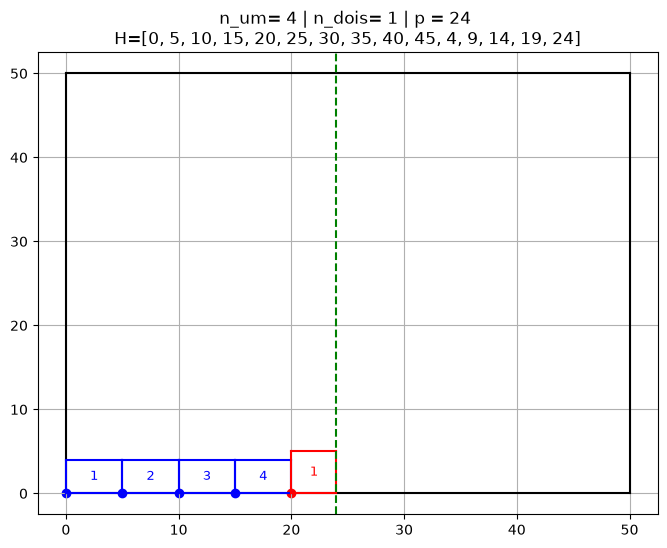

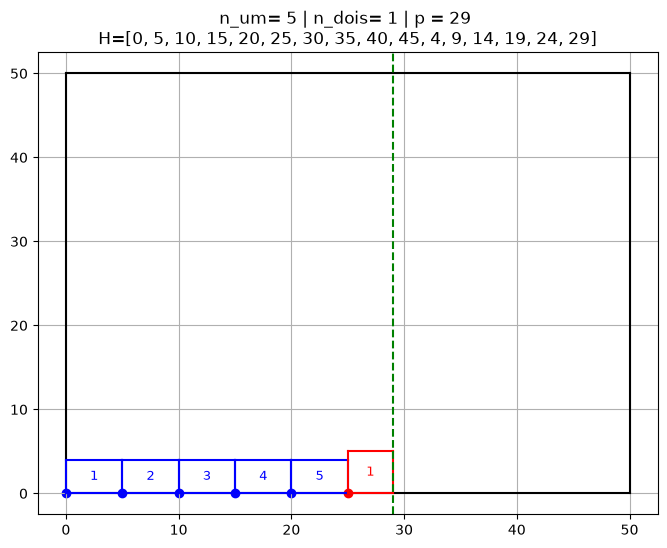

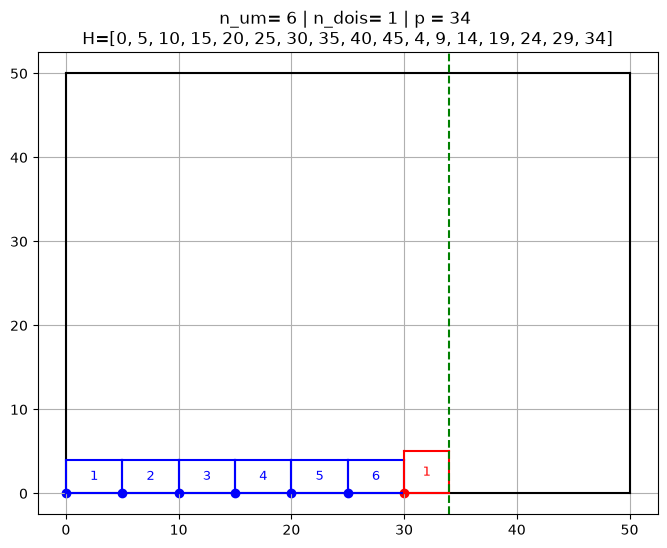

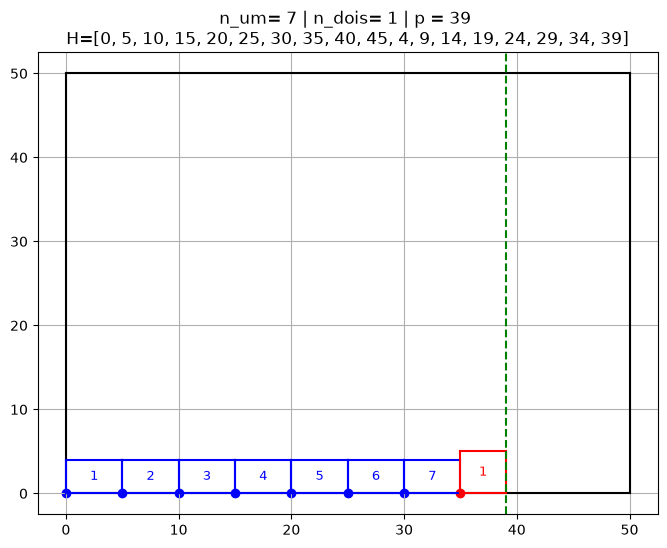

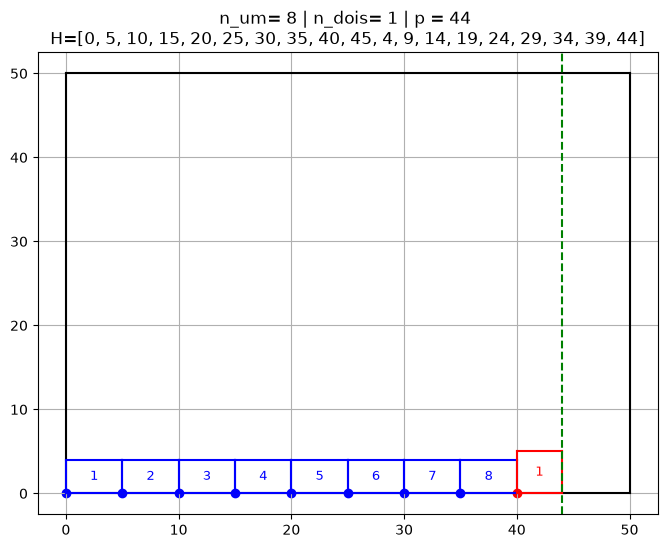

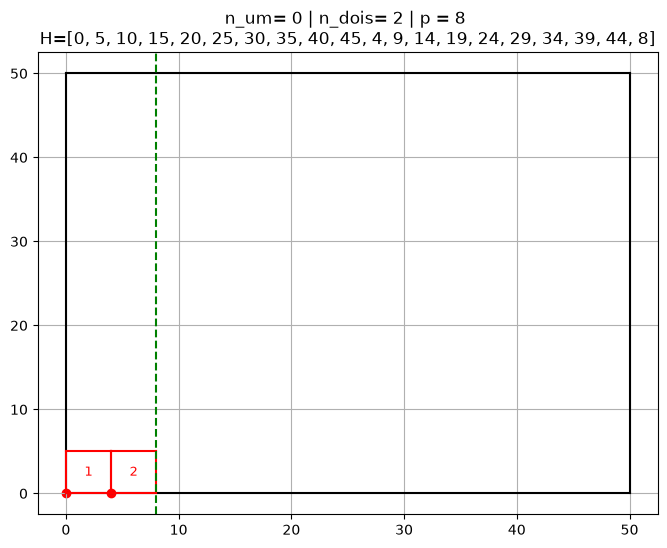

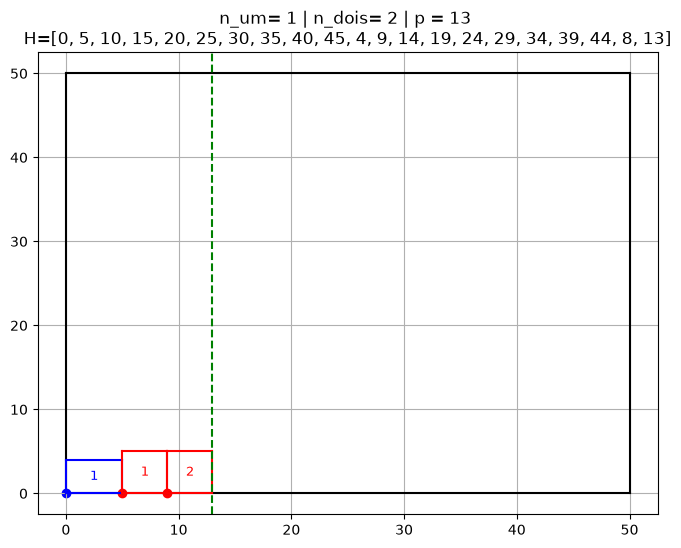

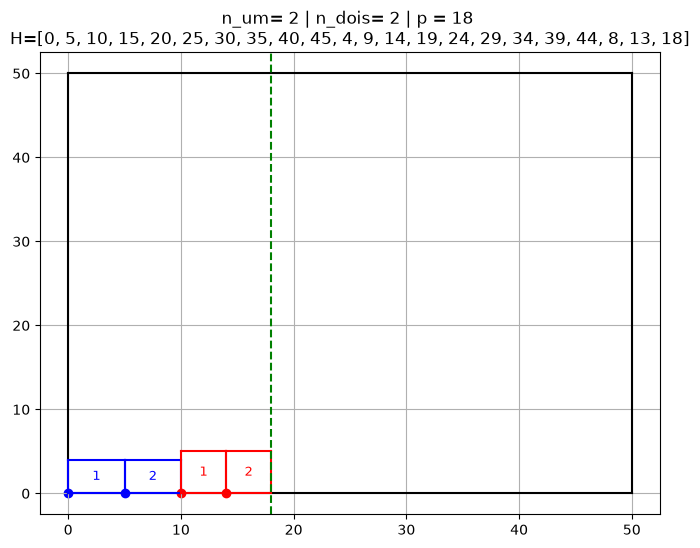

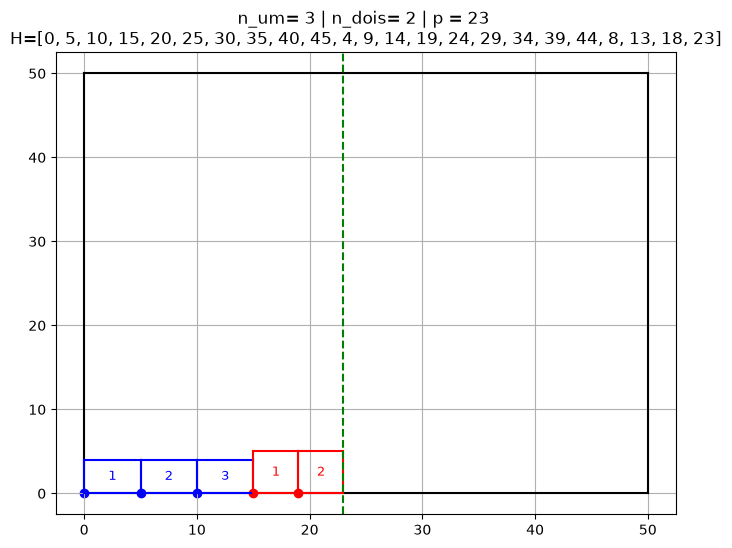

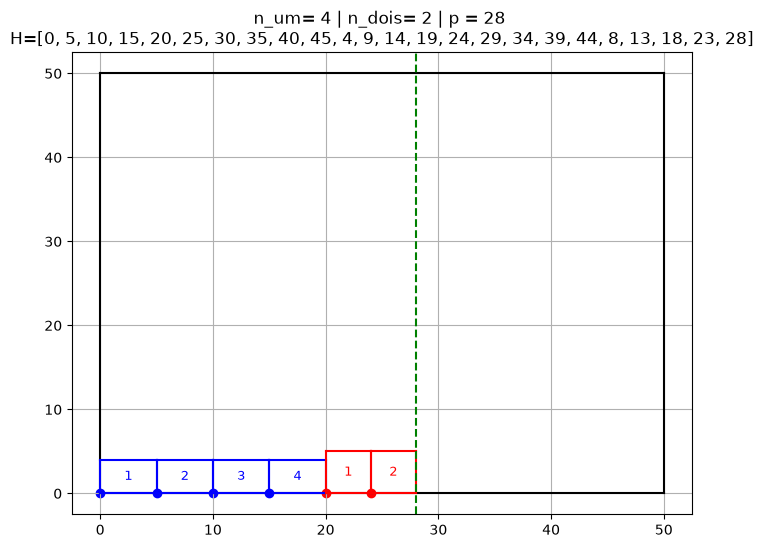

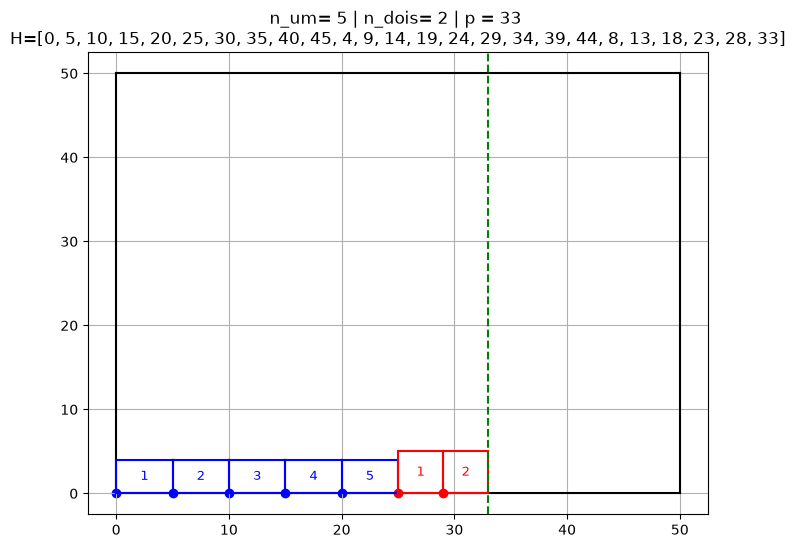

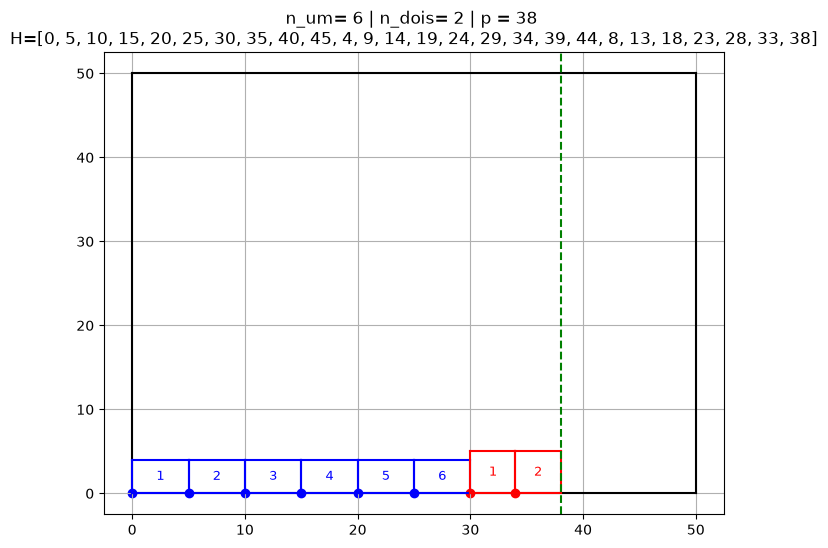

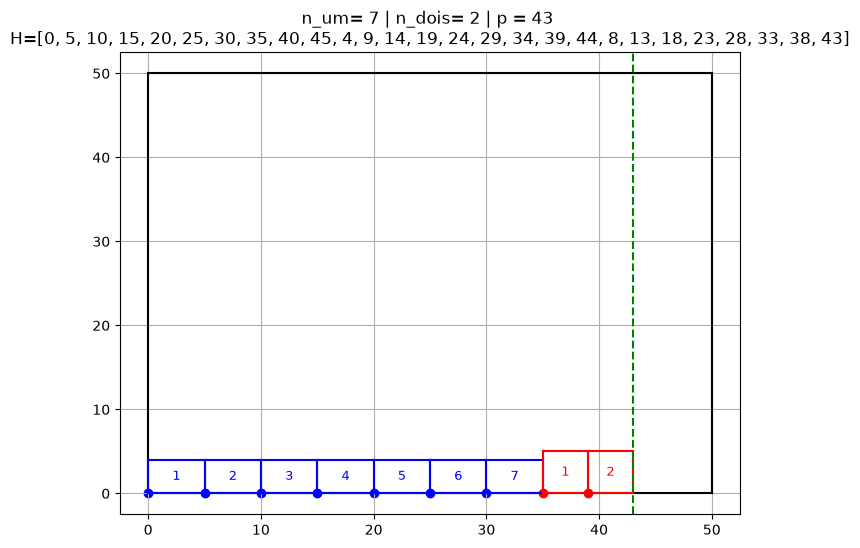

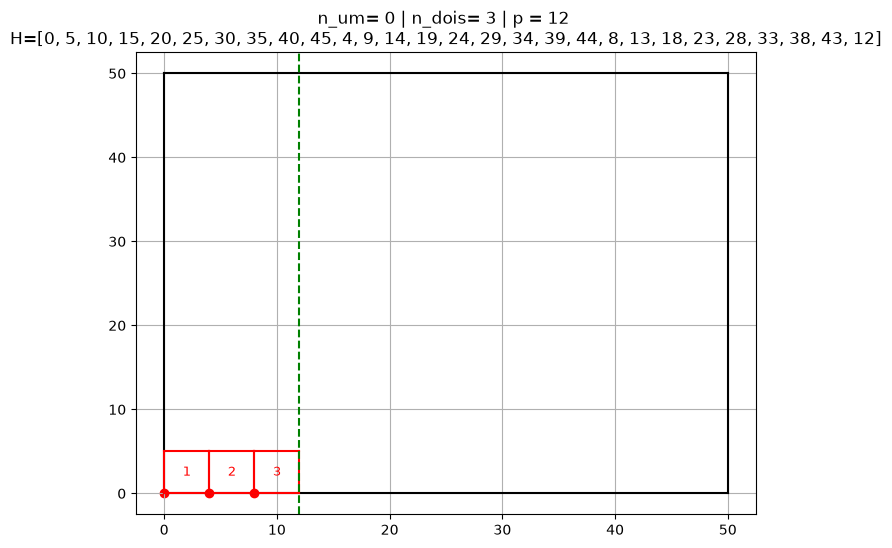

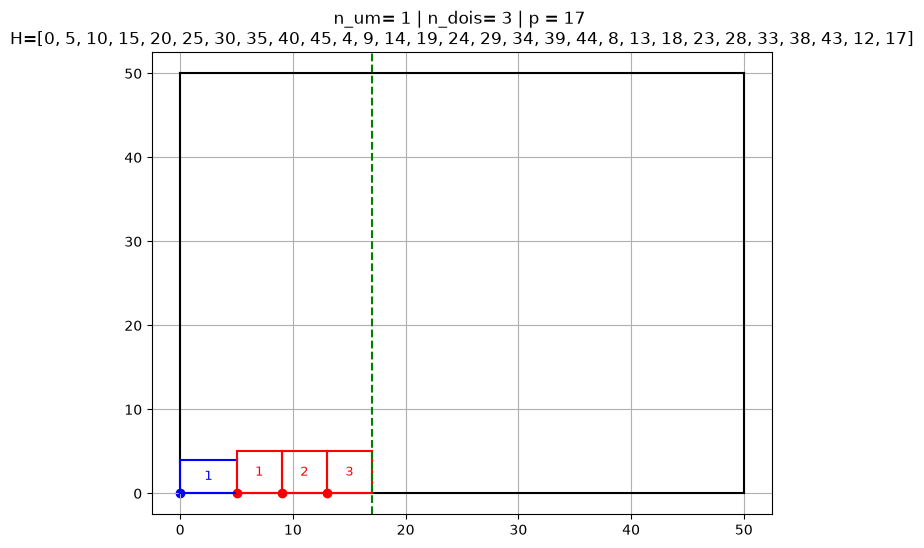

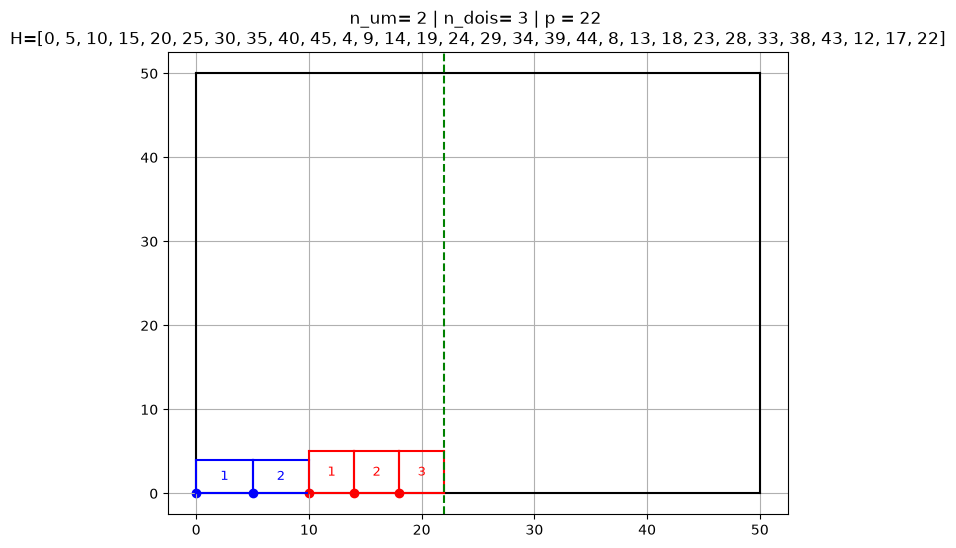

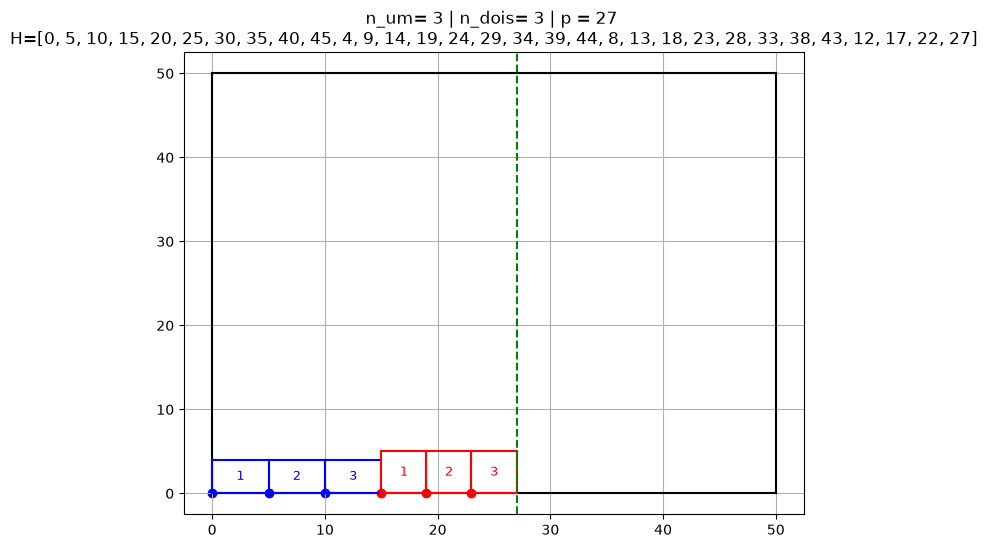

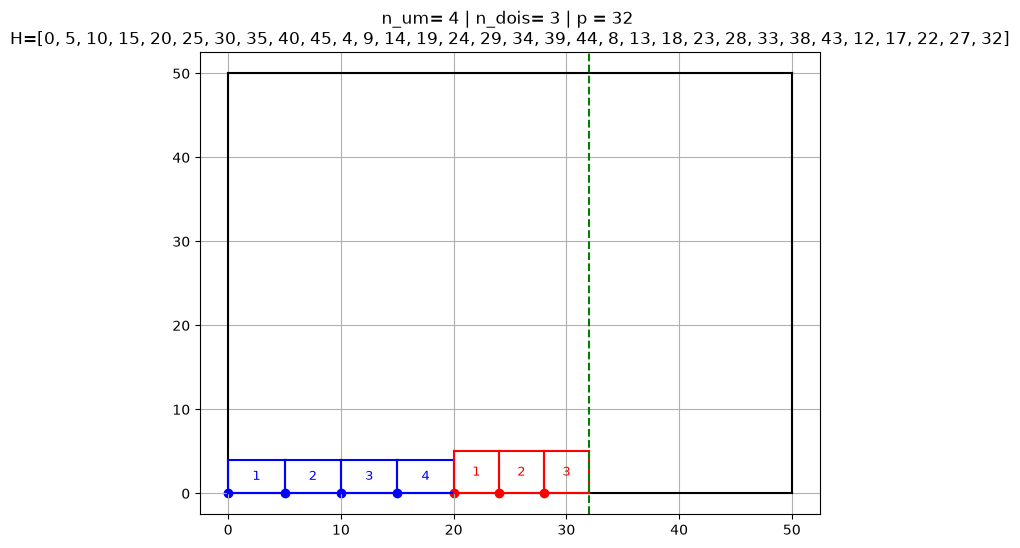

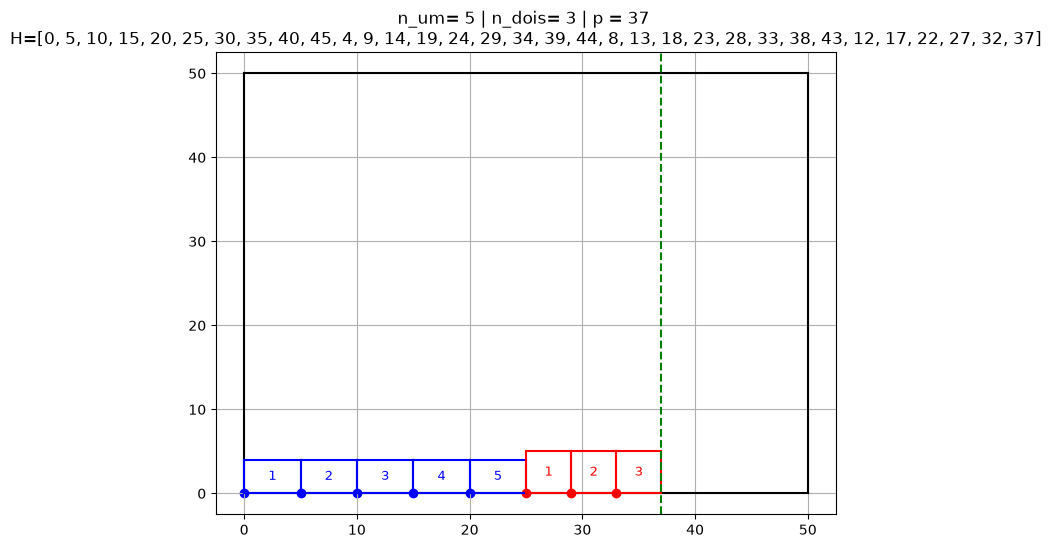

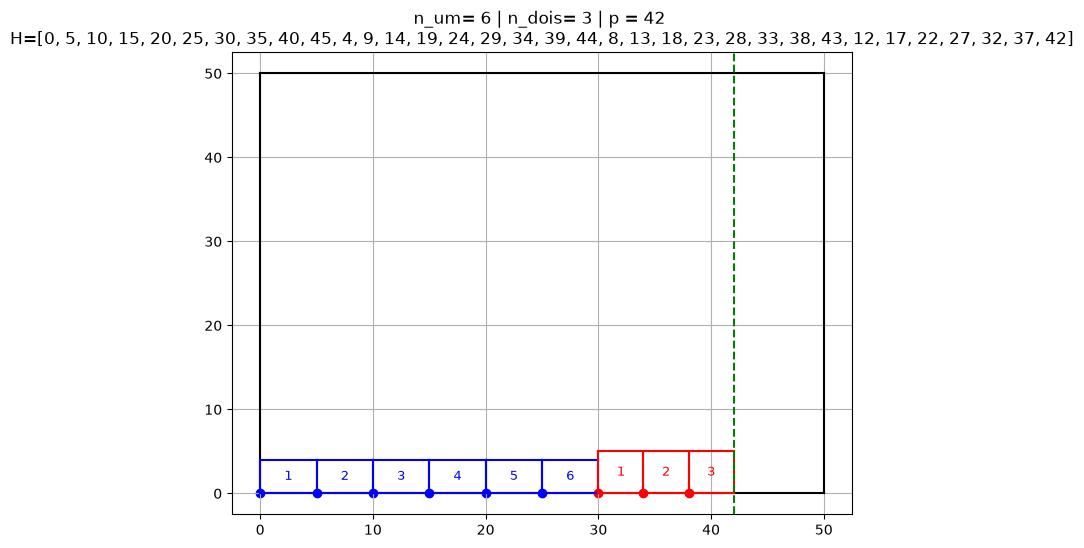

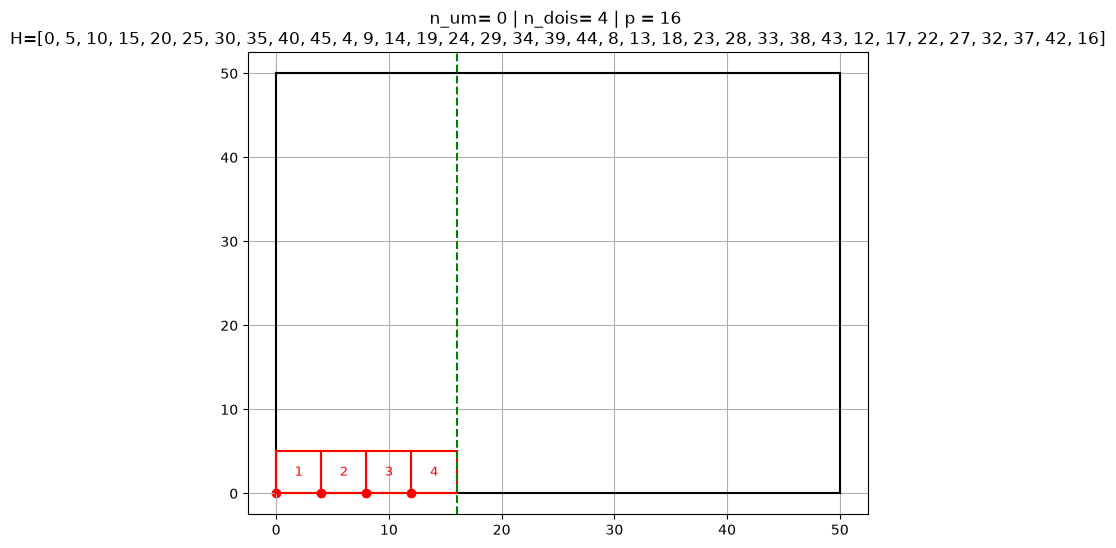

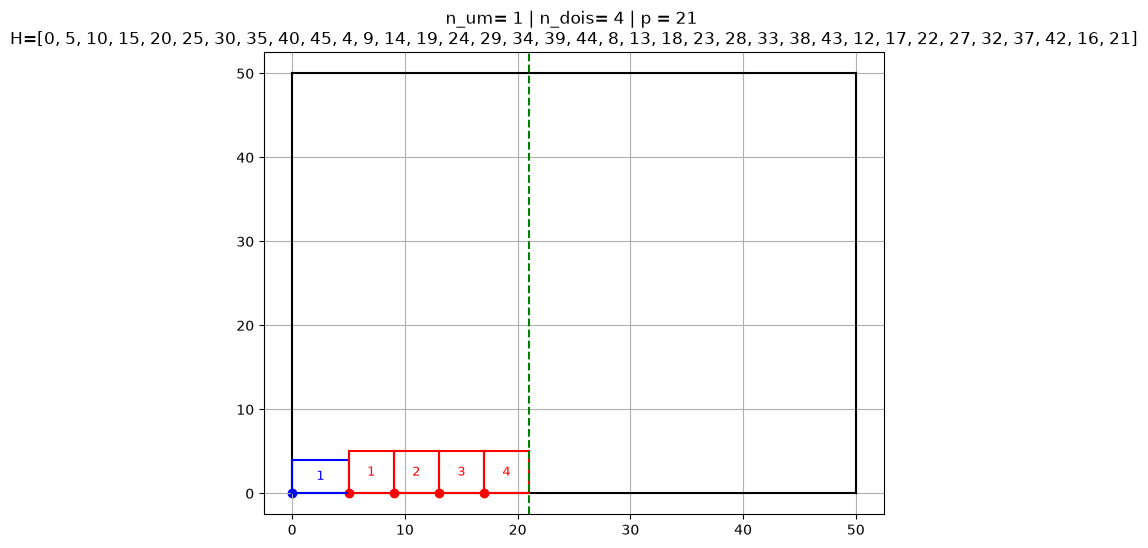

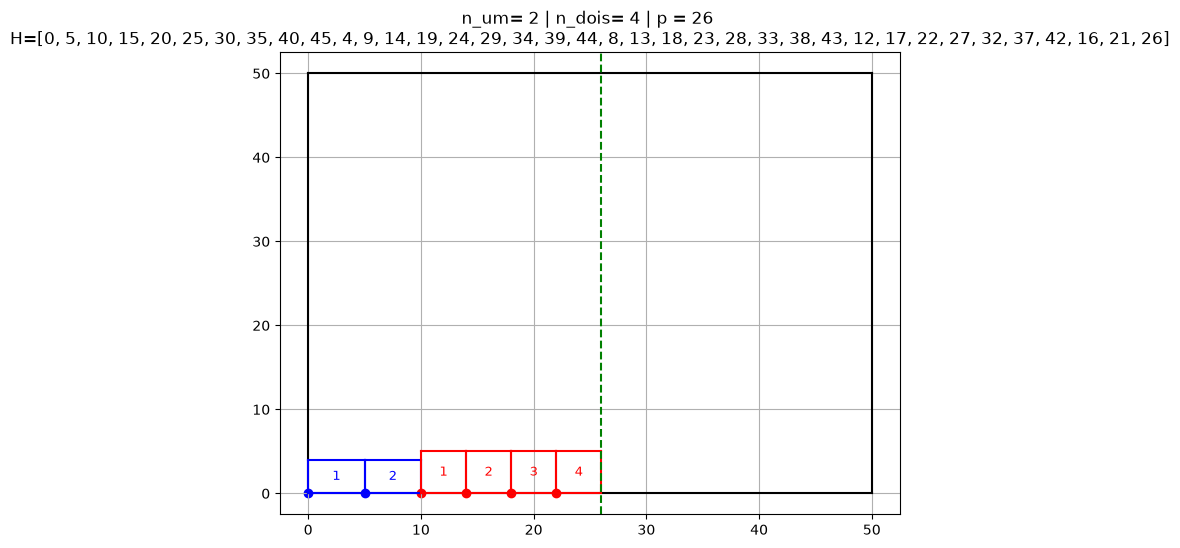

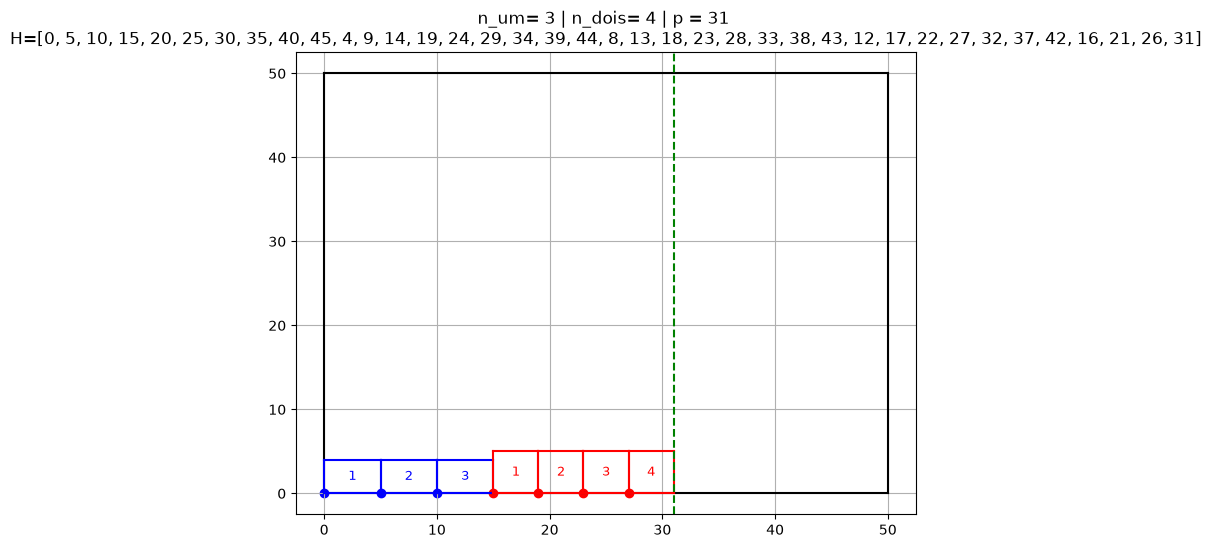

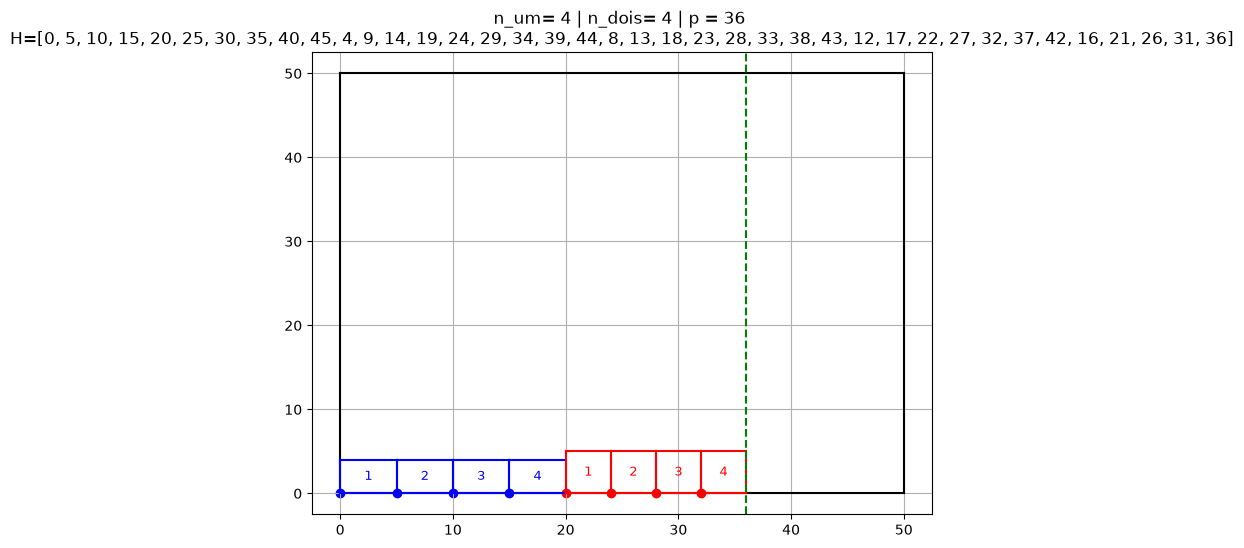

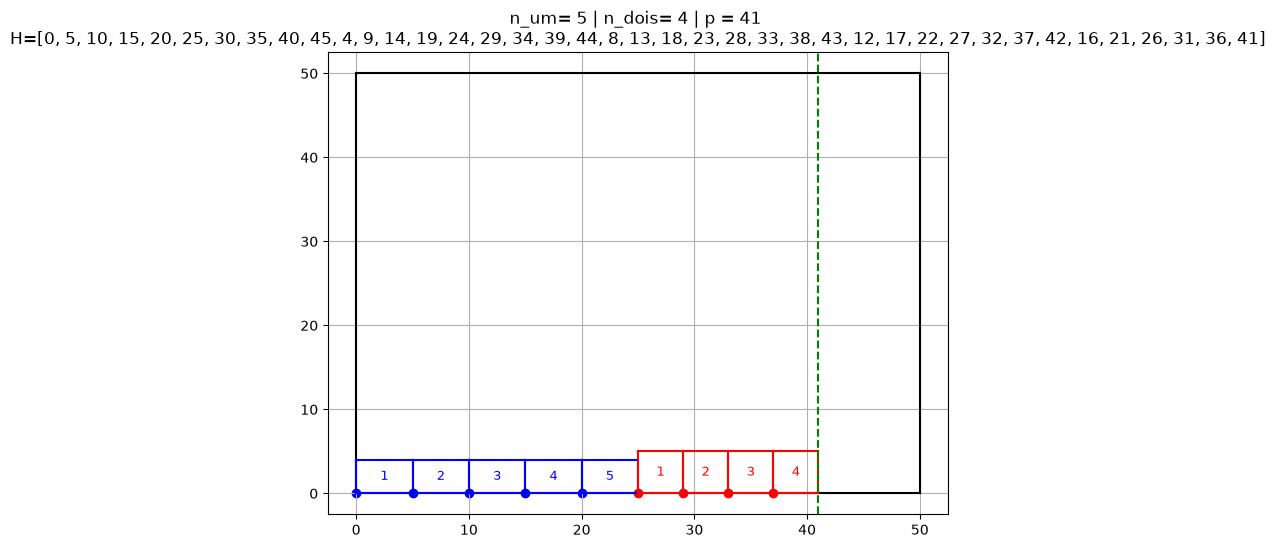

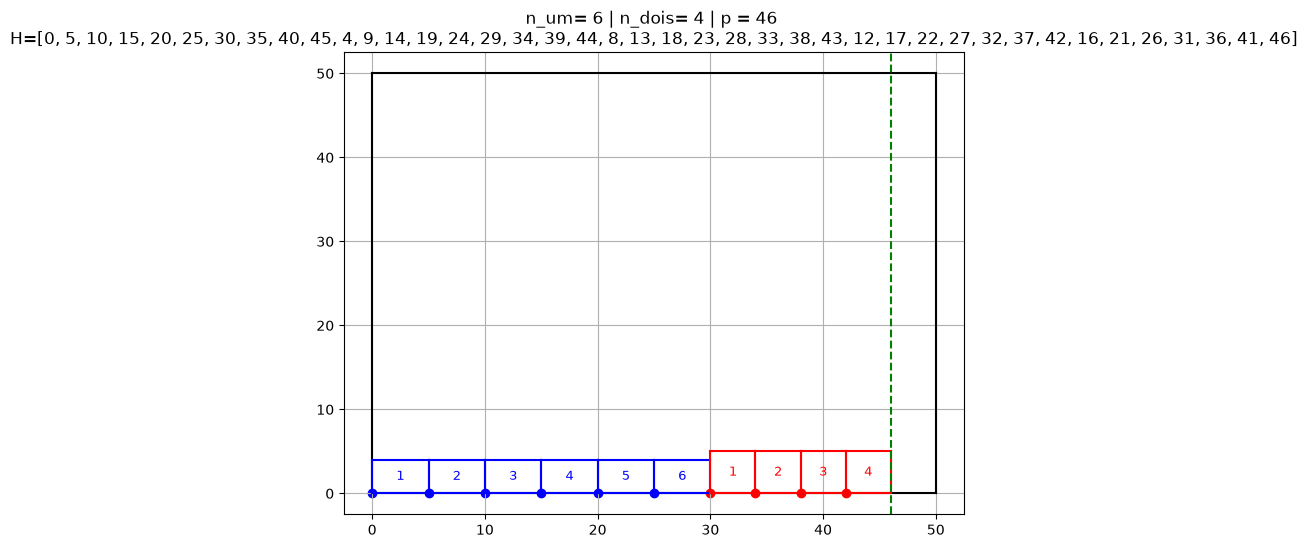

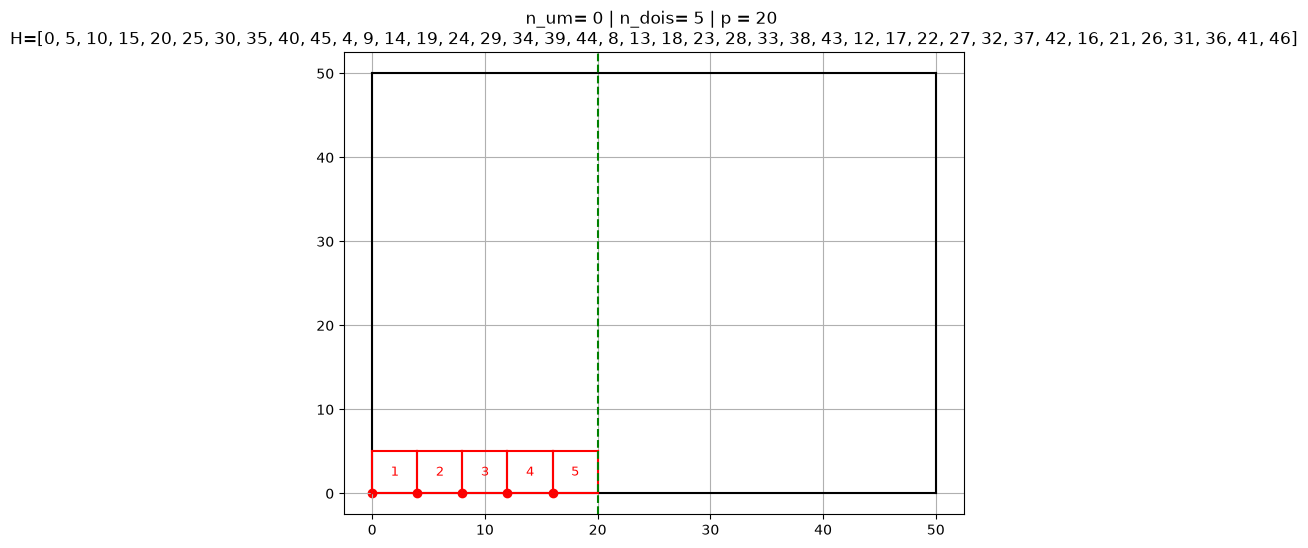

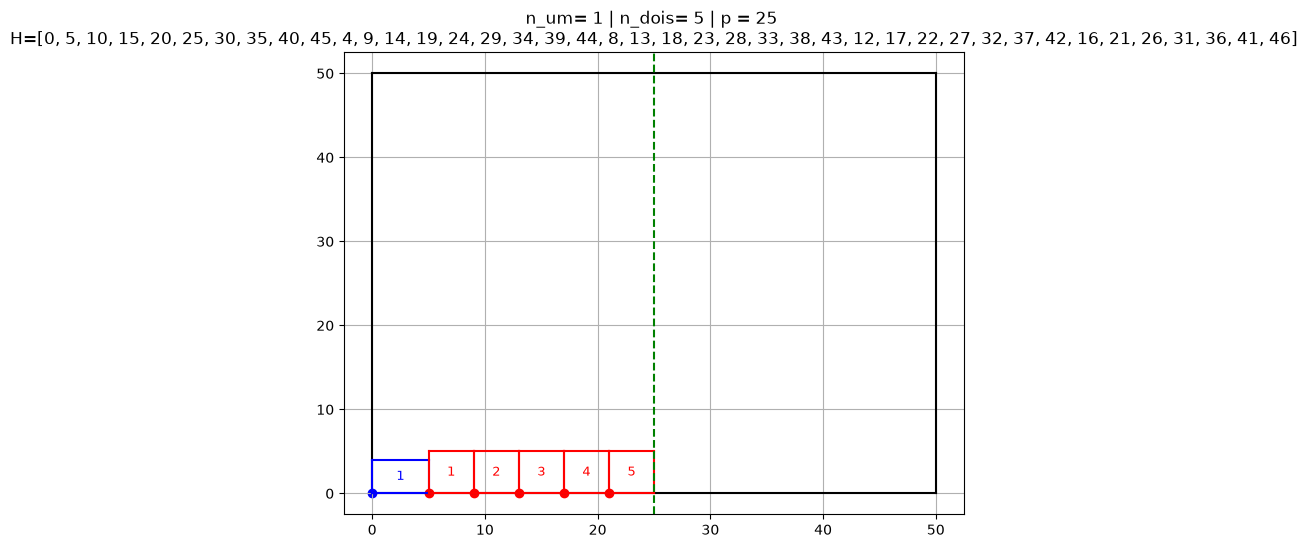

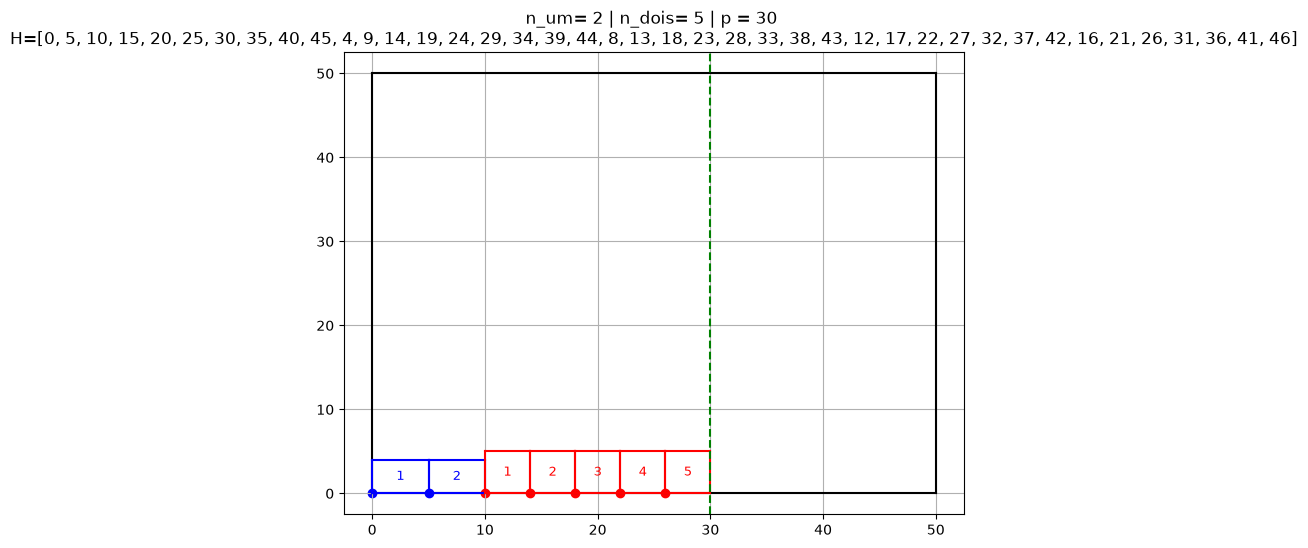

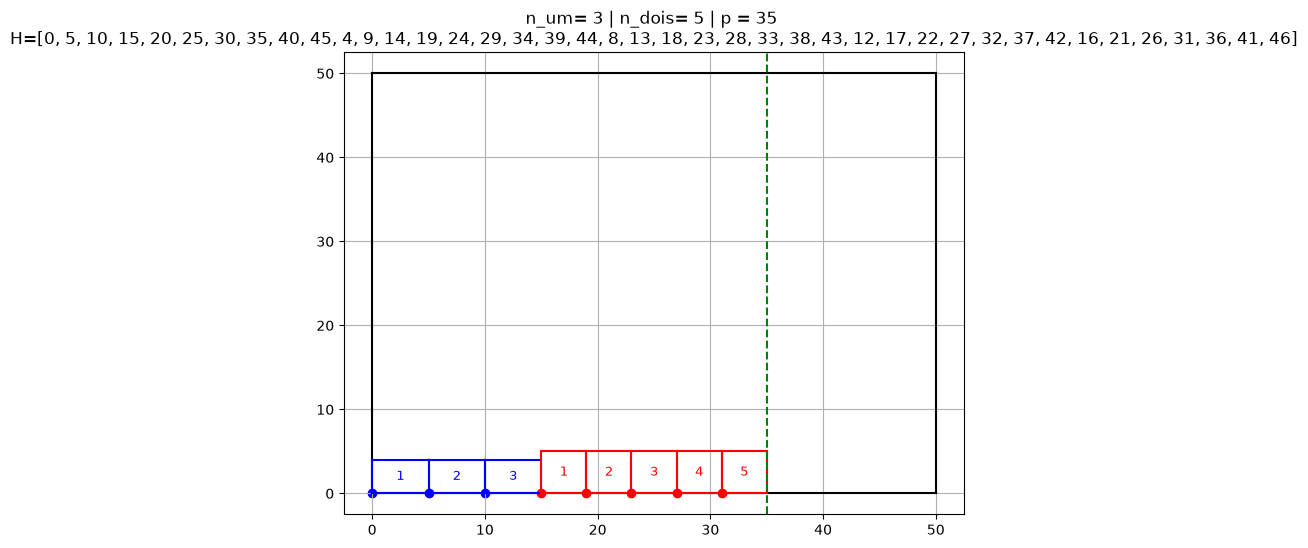

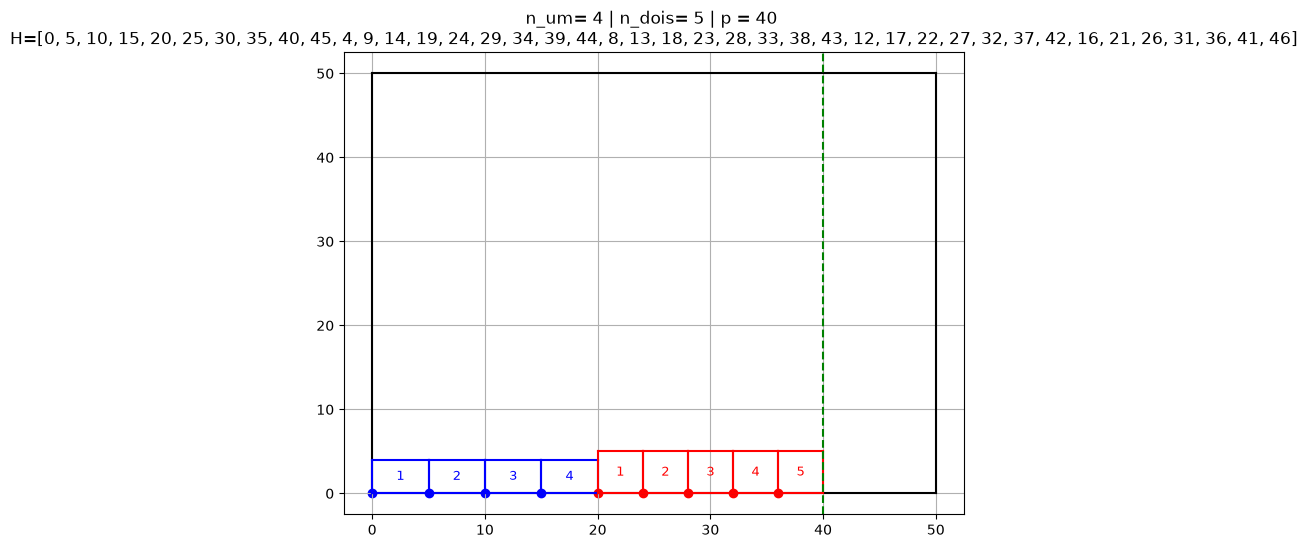

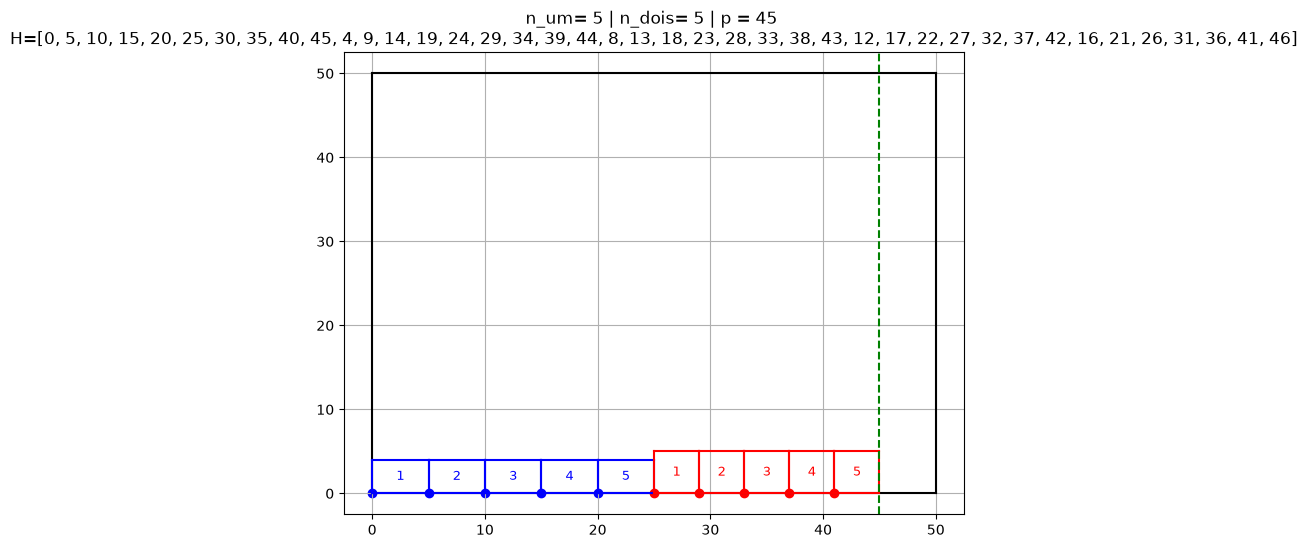

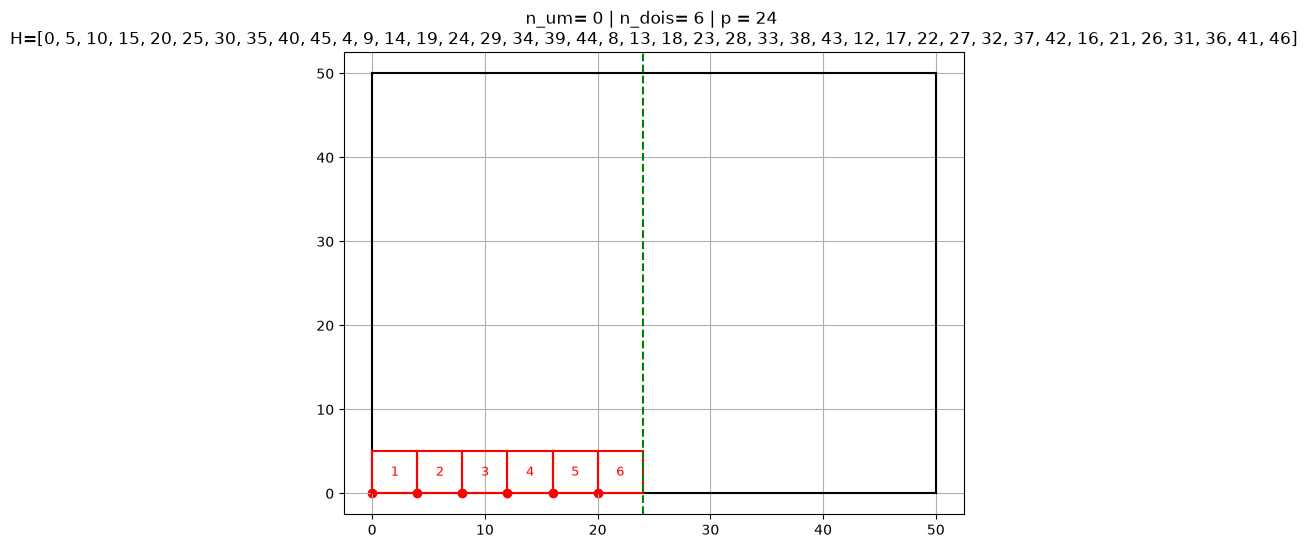

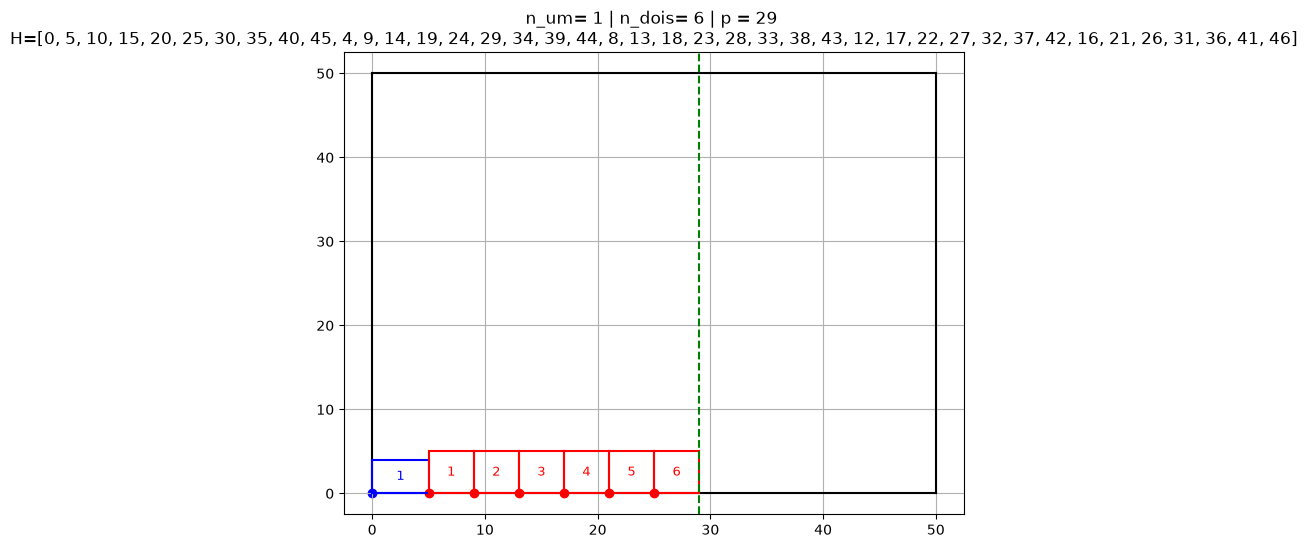

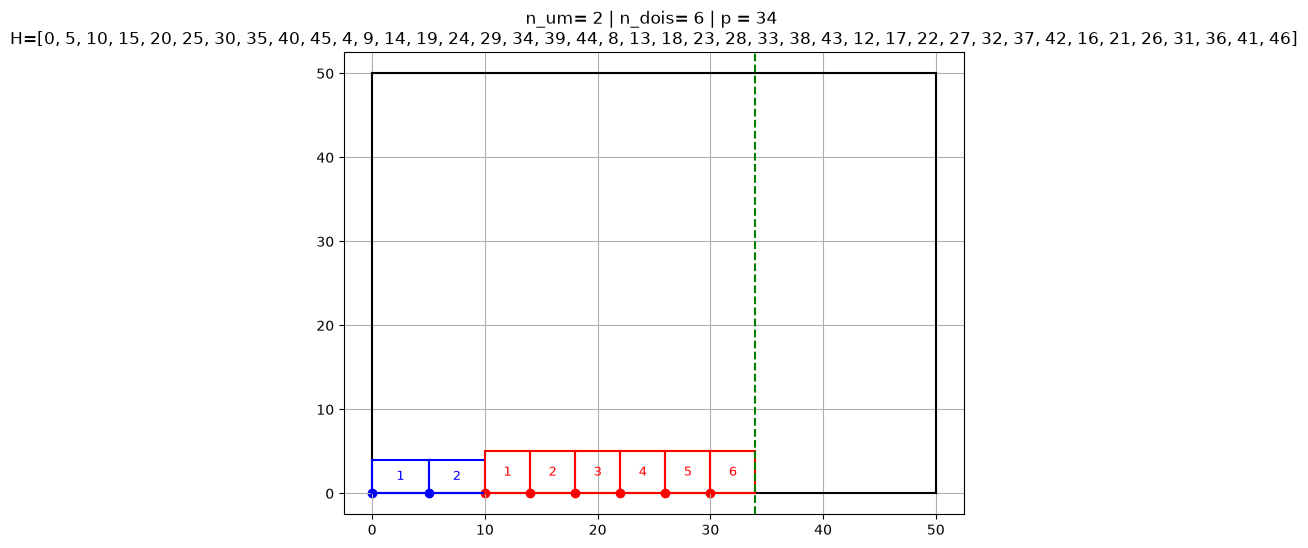

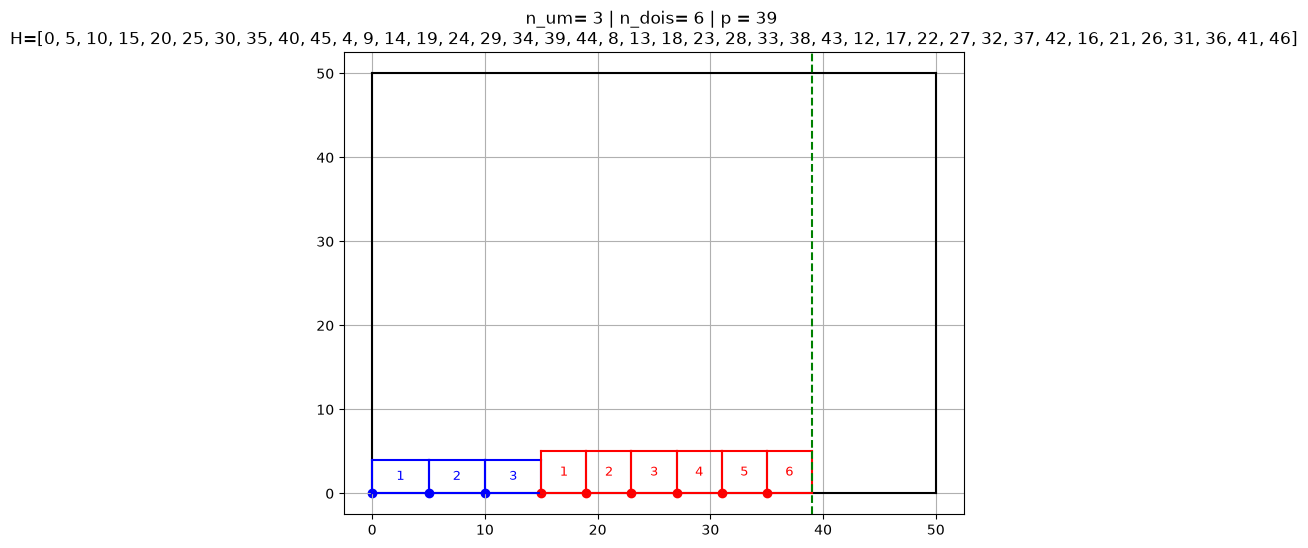

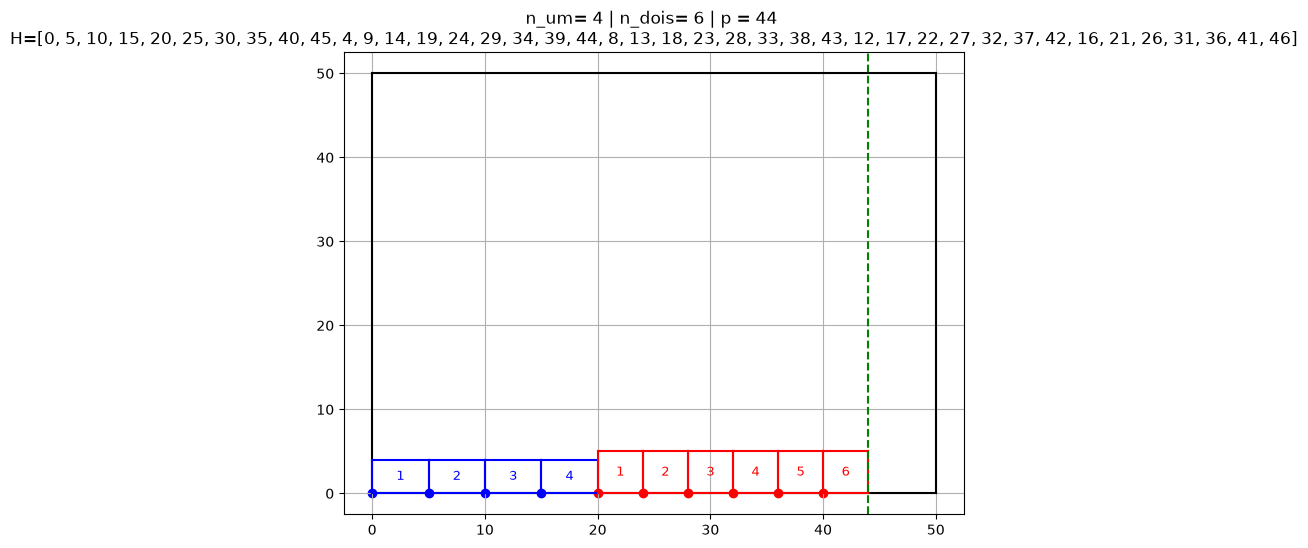

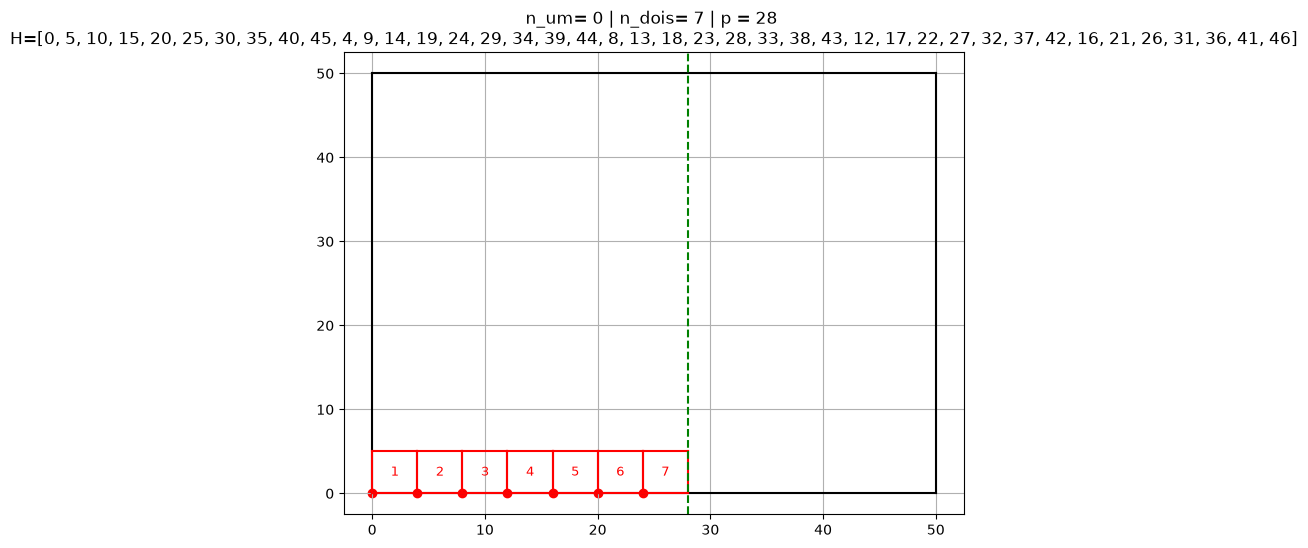

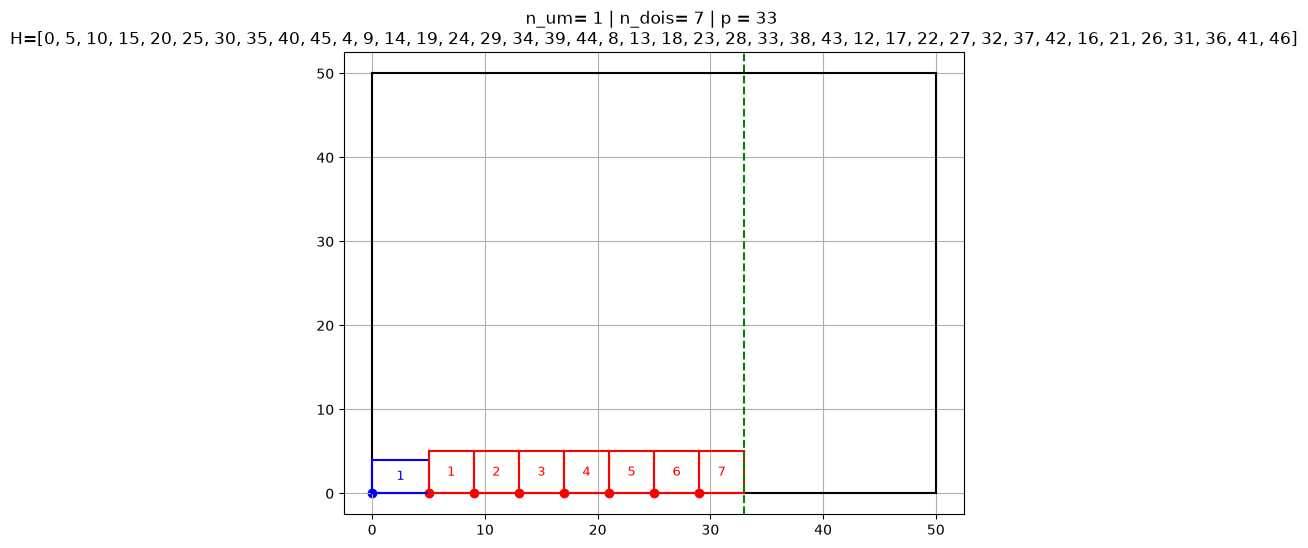

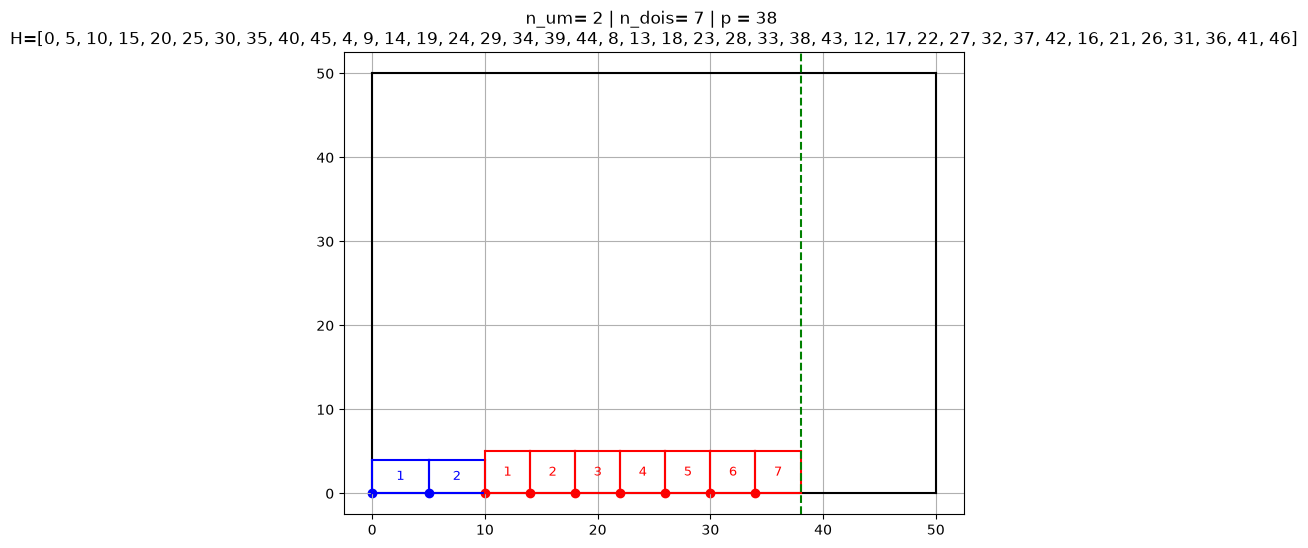

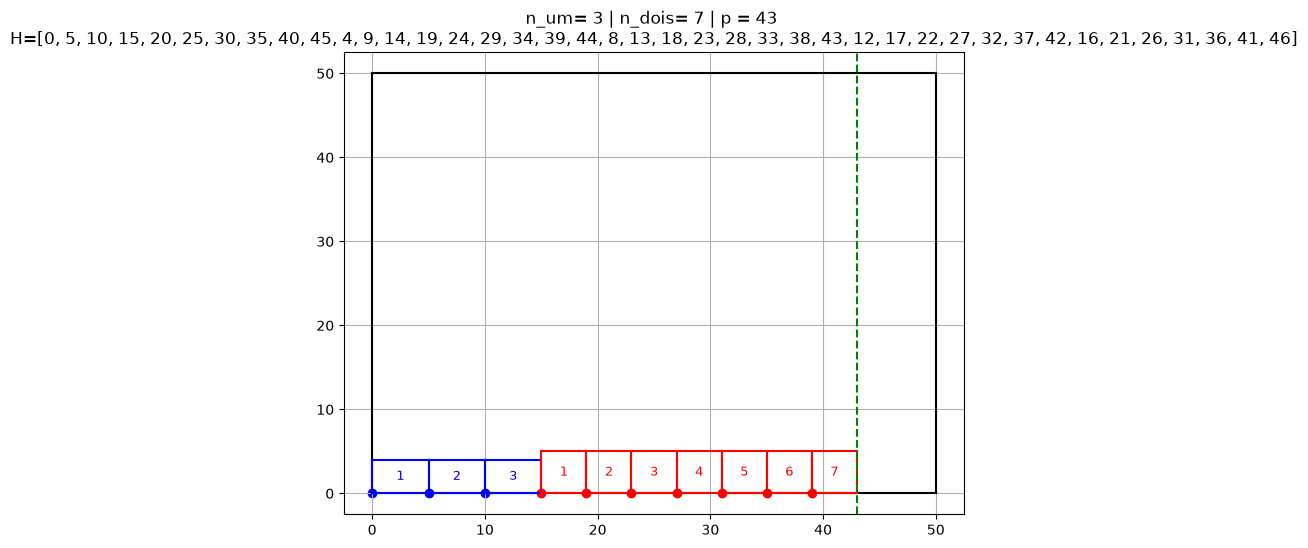

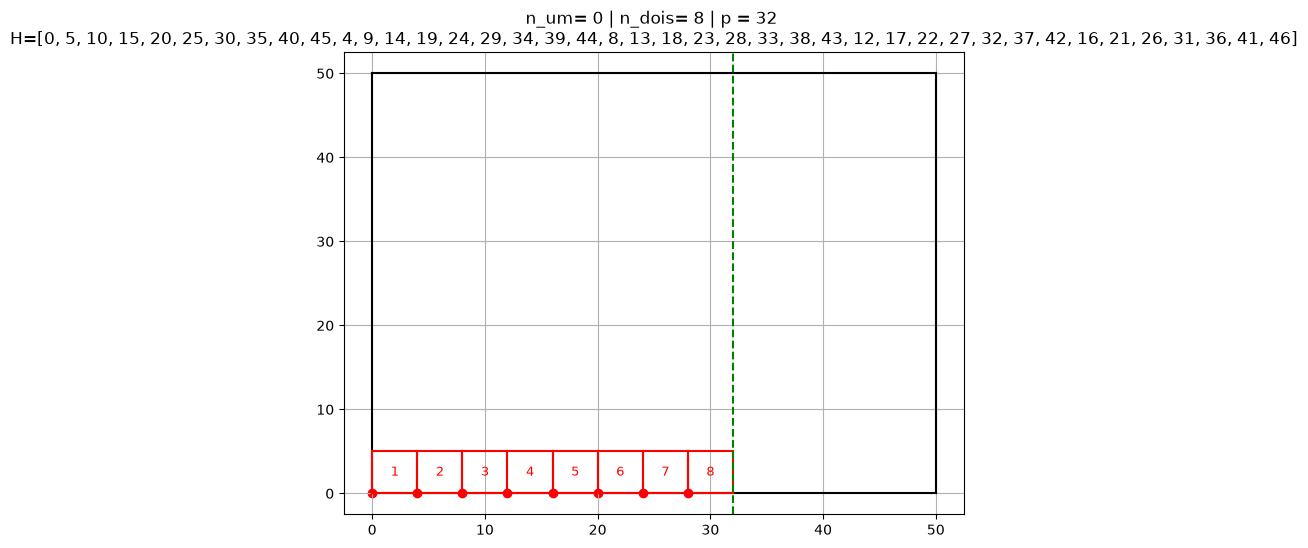

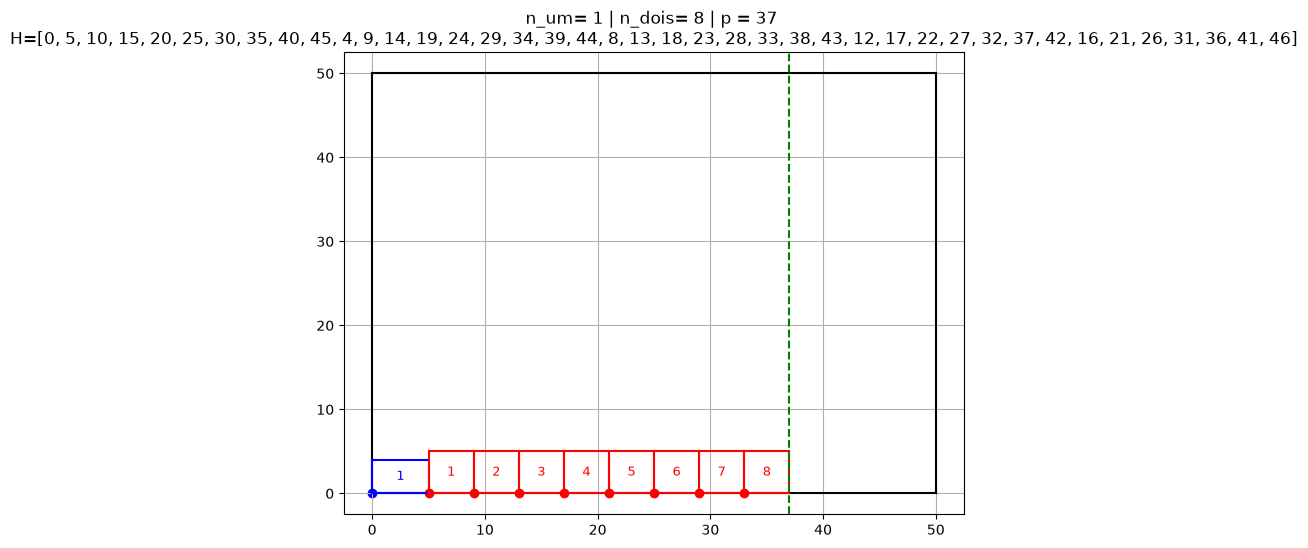

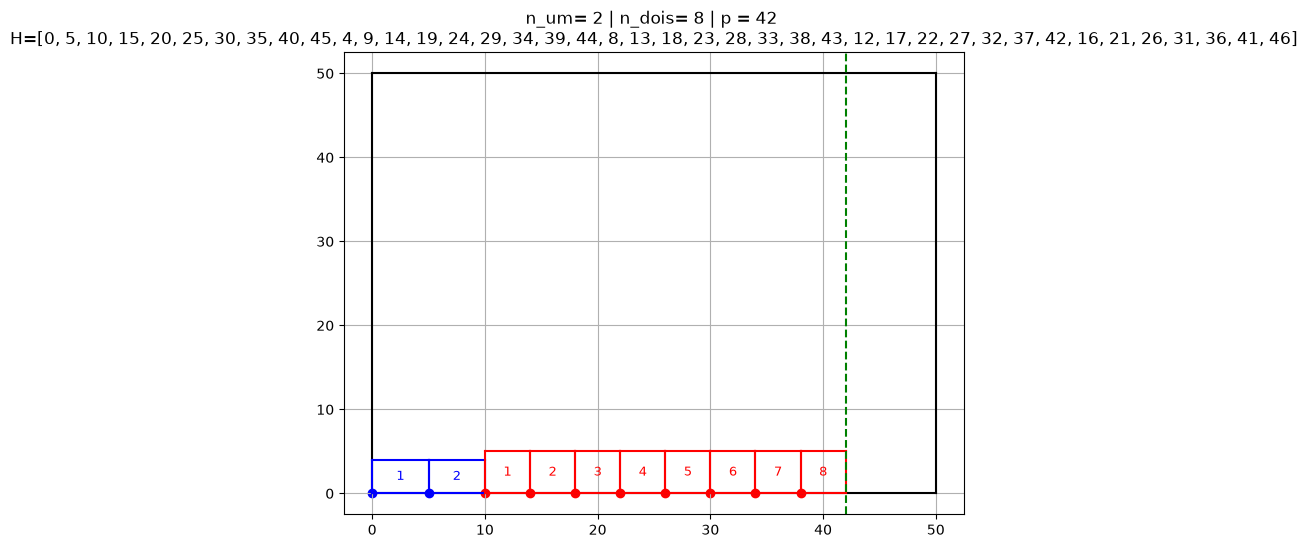

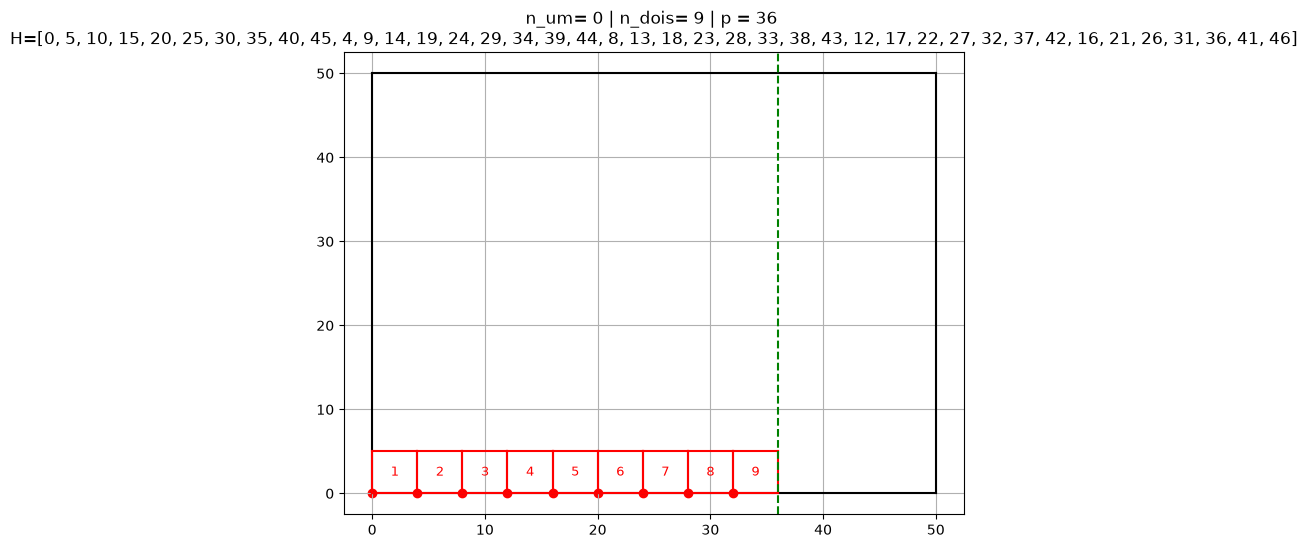

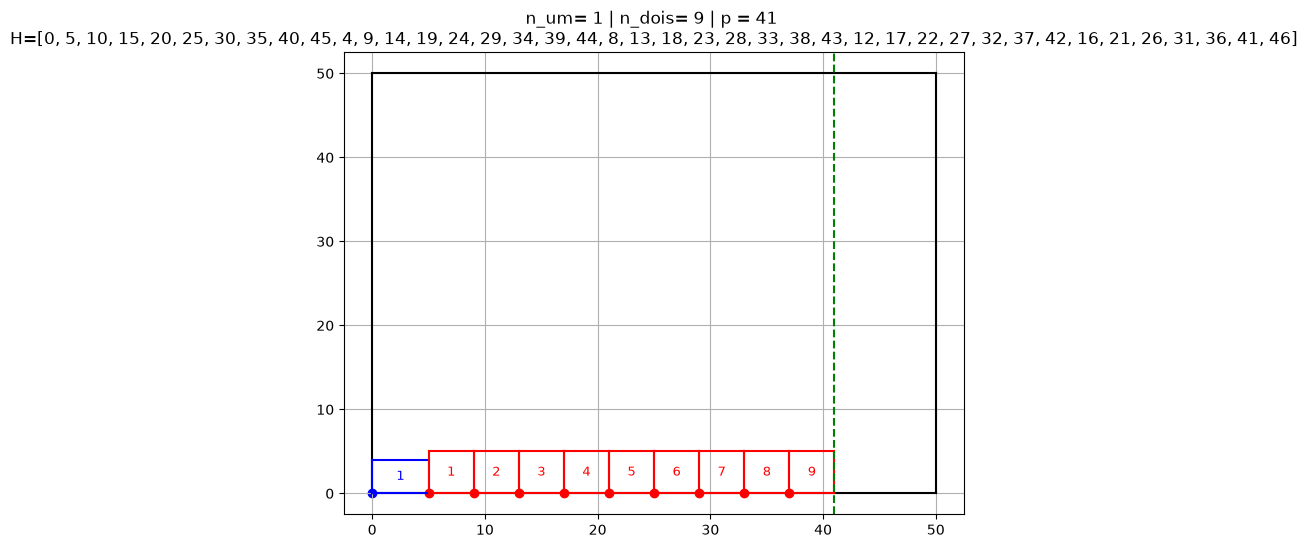

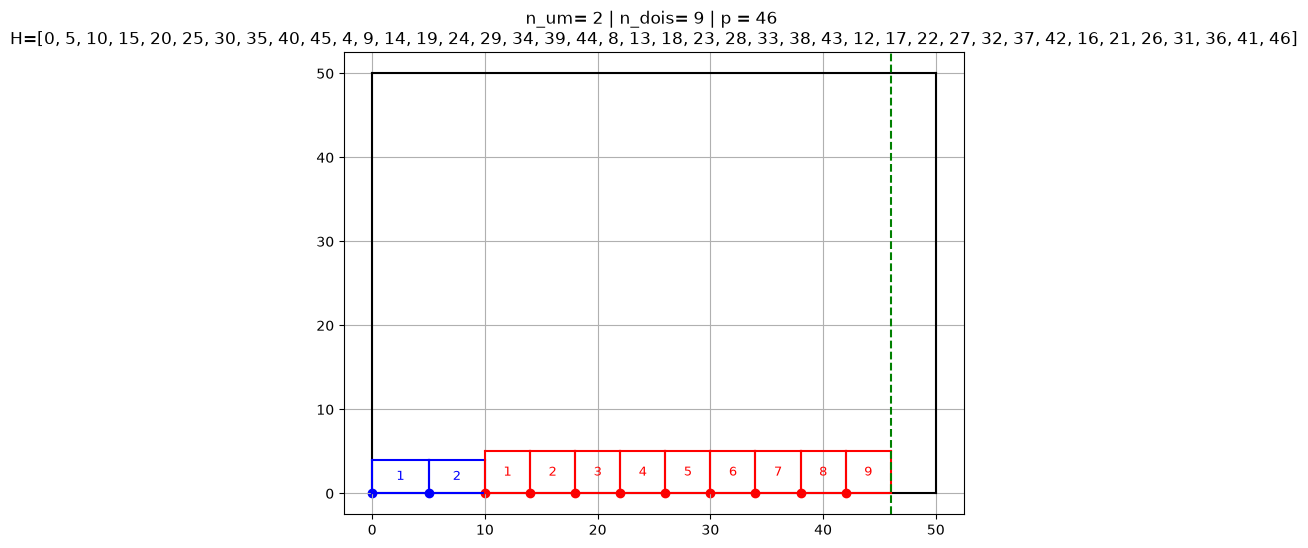

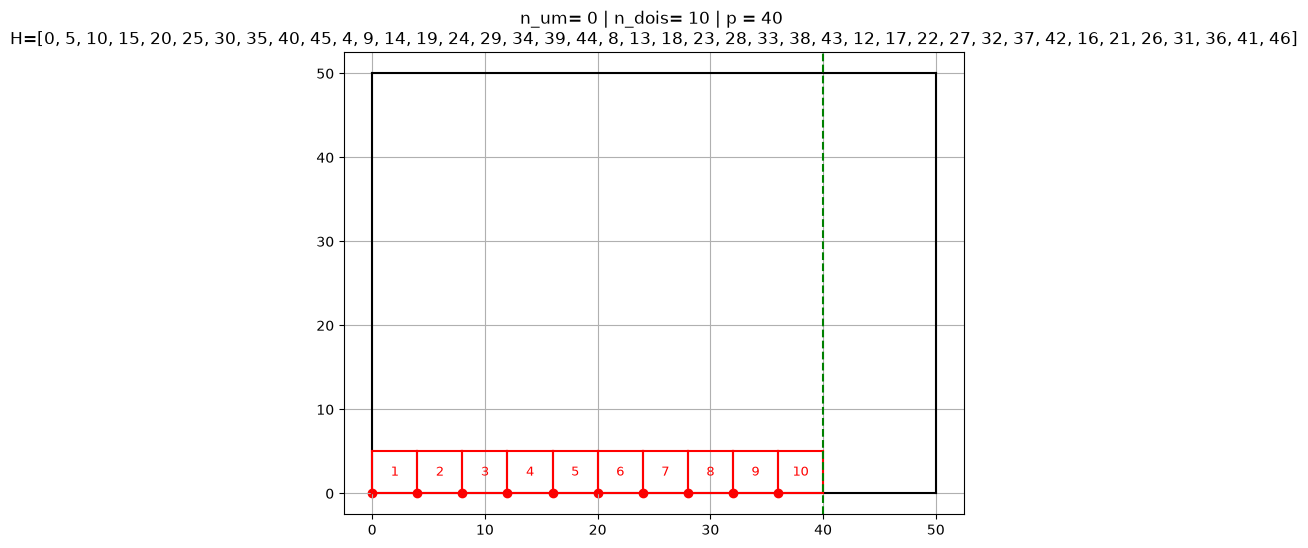

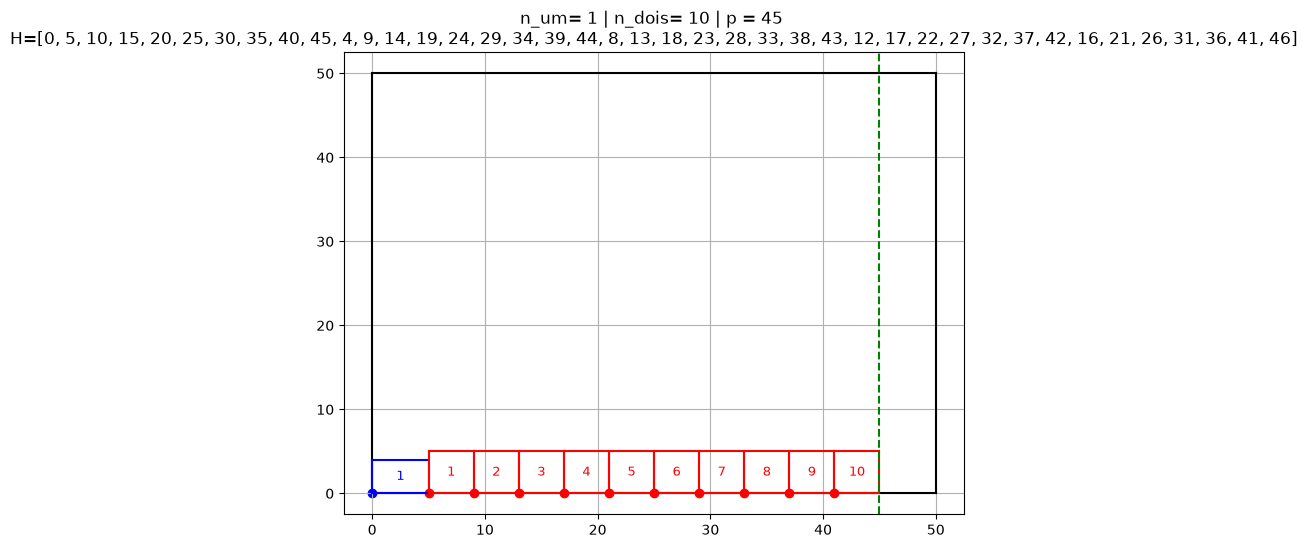

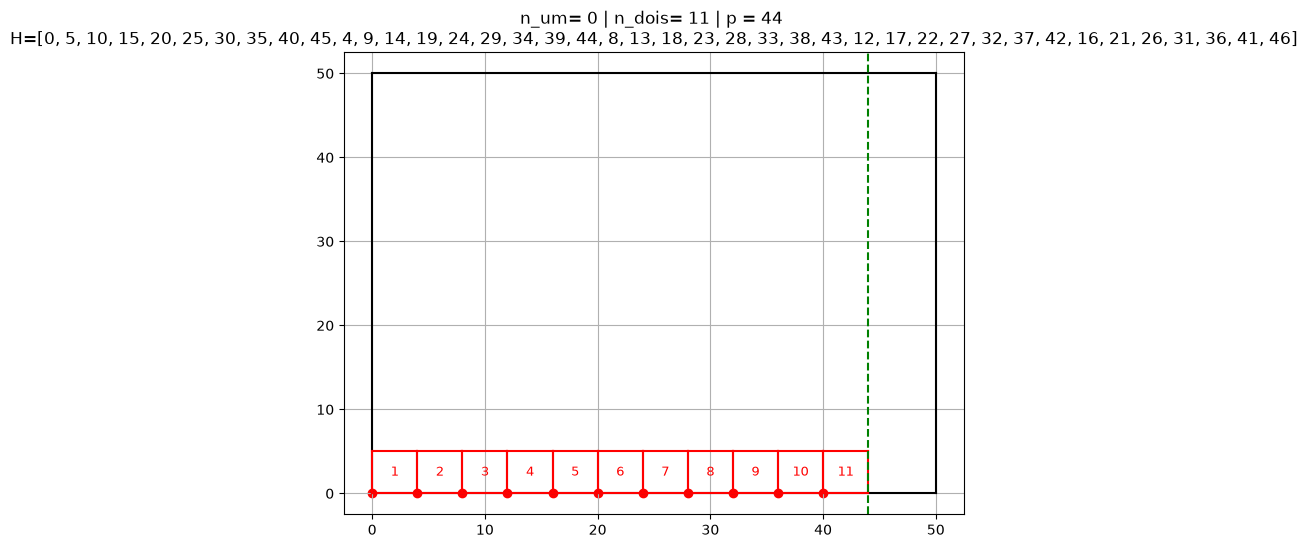

In [14]:
# teste de encaixe de p e q
H = []
for n_dois, n_um in product(range(L), range(L)): # product um com todos, todos com um
    #print(n_um, n_dois)
    p = f_um(n_um, l_um, n_dois, l_dois)
    #print(n_um, n_dois, p) # deixar o for sem repetir
    if p <= L - w_um:

        if p not in H:
            H.append(p)

        plotar_palete(L,W)

        for n in range(n_um):
            plotar_caixa(bottom_left=[n*l_um, 0], l=l_um, w=w_um,
            color = "blue", label = n+1)

        for n in range(n_dois):
            plotar_caixa(bottom_left=[n_um * l_um + n * l_dois, 0],
                         l=l_dois, w=w_dois, color="red",
                         label =n+1)

        plt.axvline(x=p, color="green", linestyle="--")
        plt.title(f"{n_um= } | {n_dois= } | {p = } \n{H=}")
        plt.grid()

C:\Users\Guilherme Roque\AppData\Local\Temp\ipykernel_5840\3910285793.py:16: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(8,6))


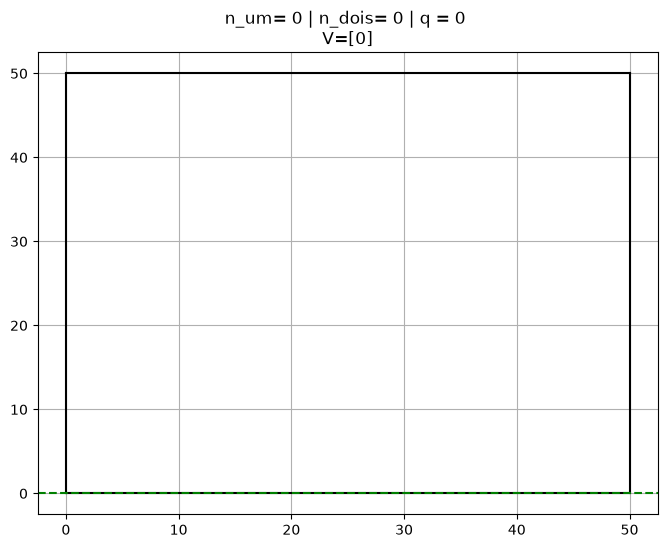

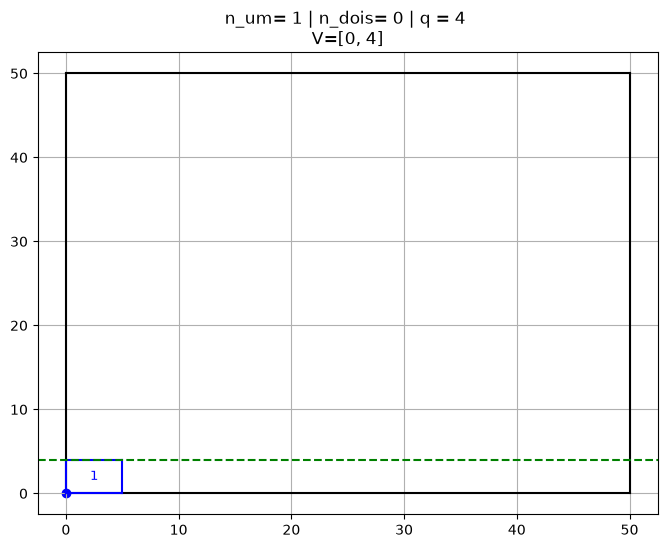

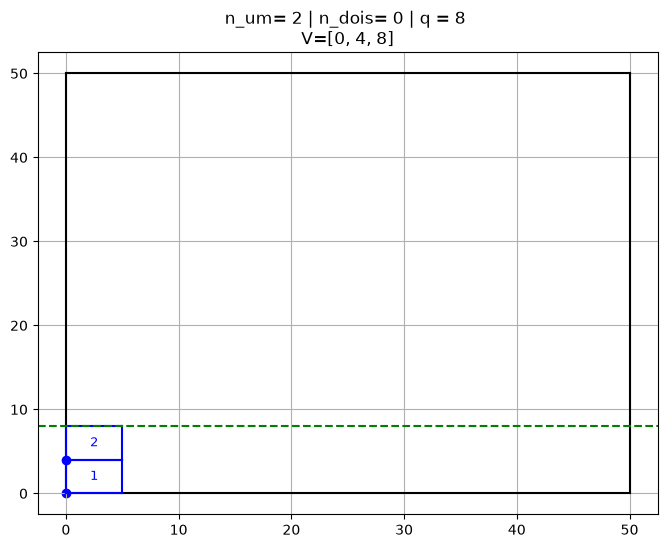

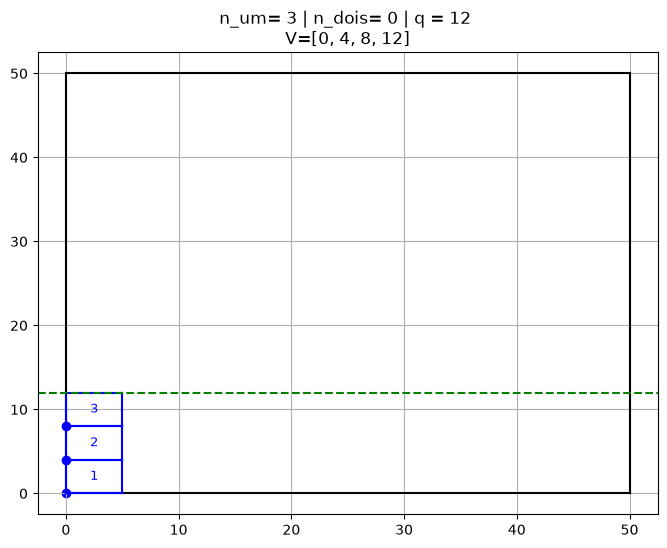

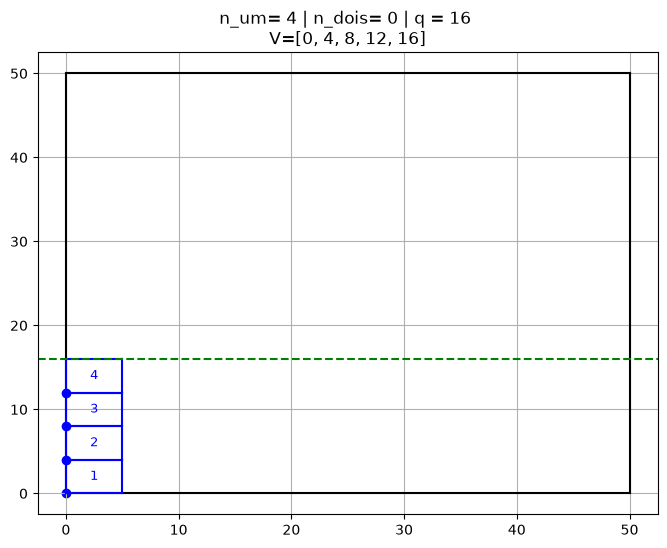

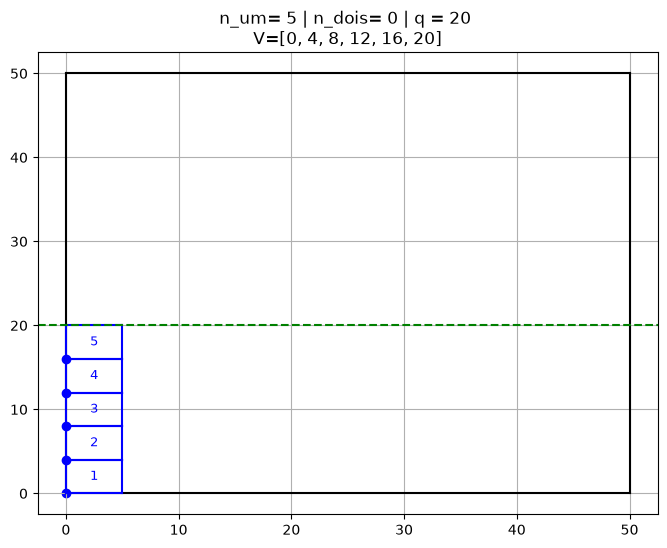

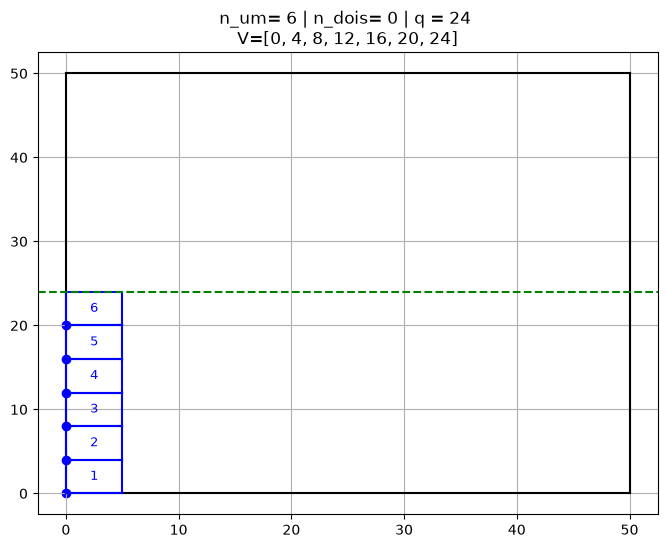

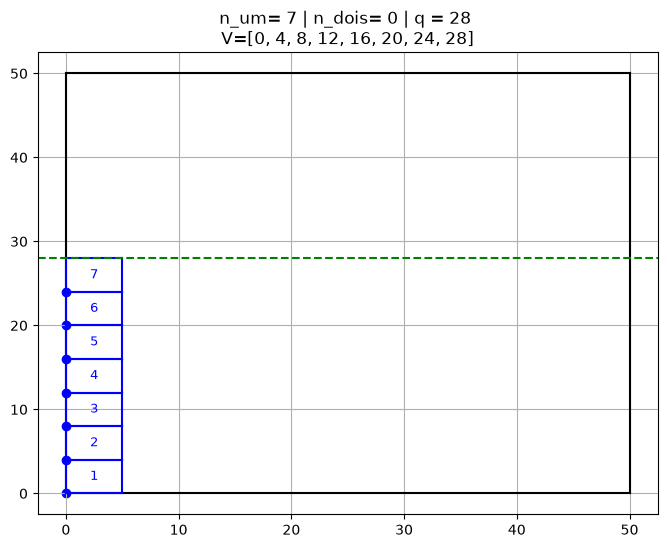

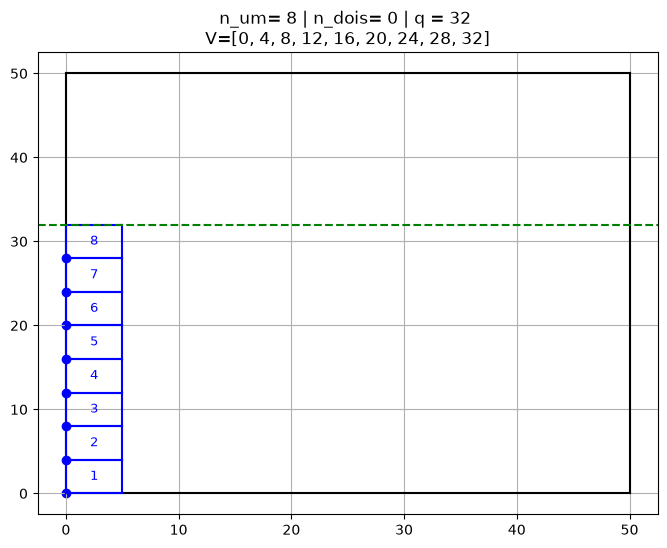

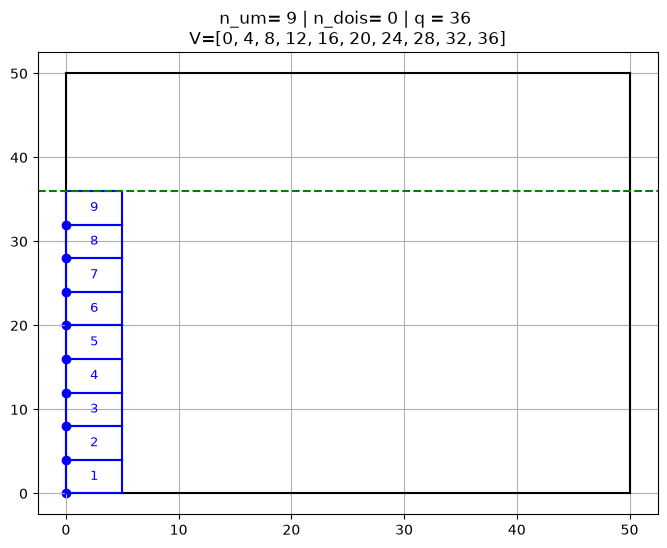

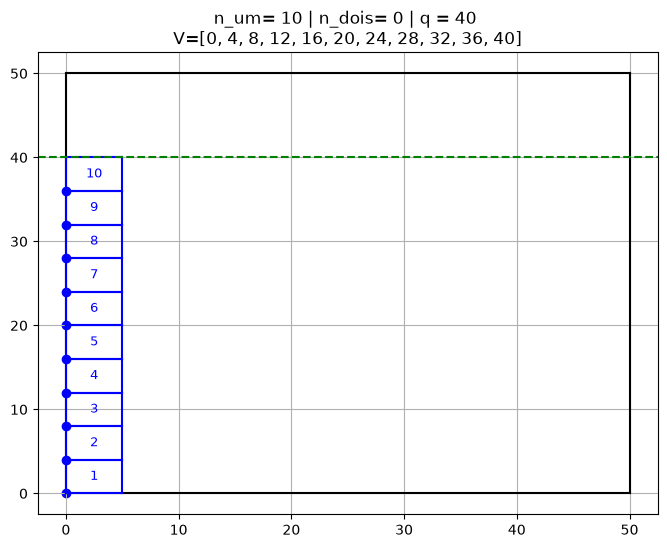

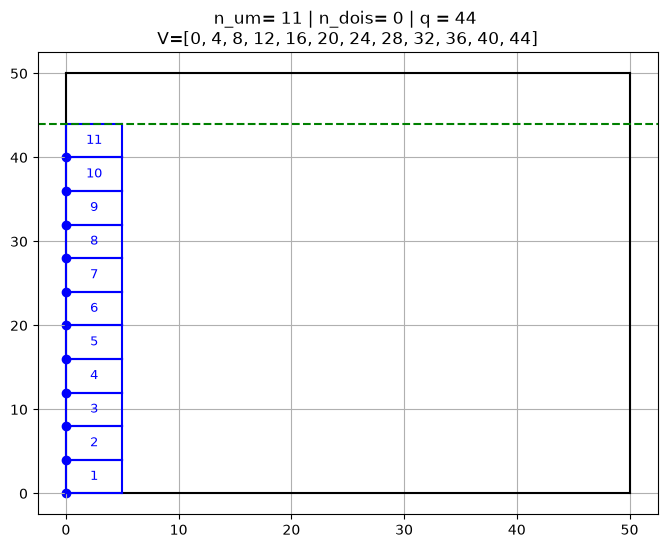

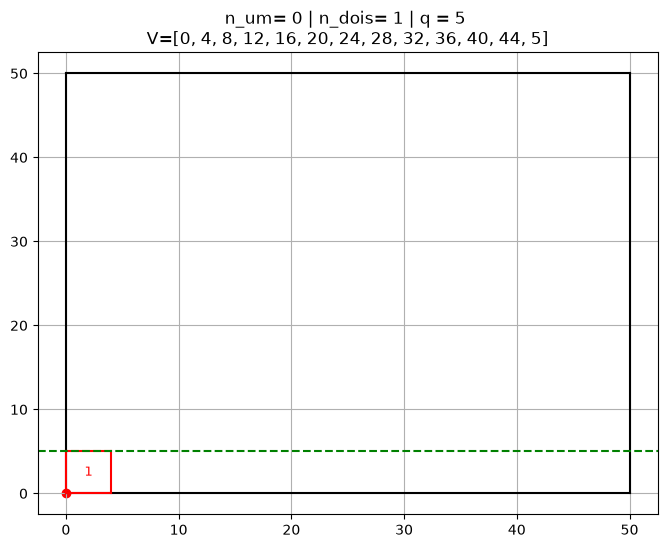

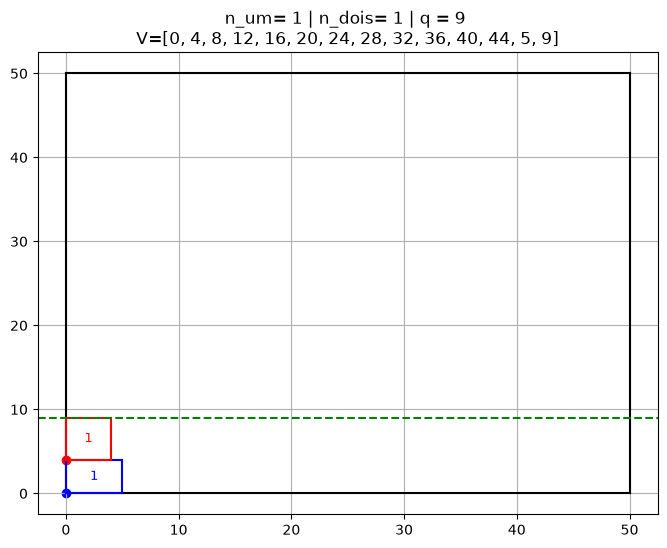

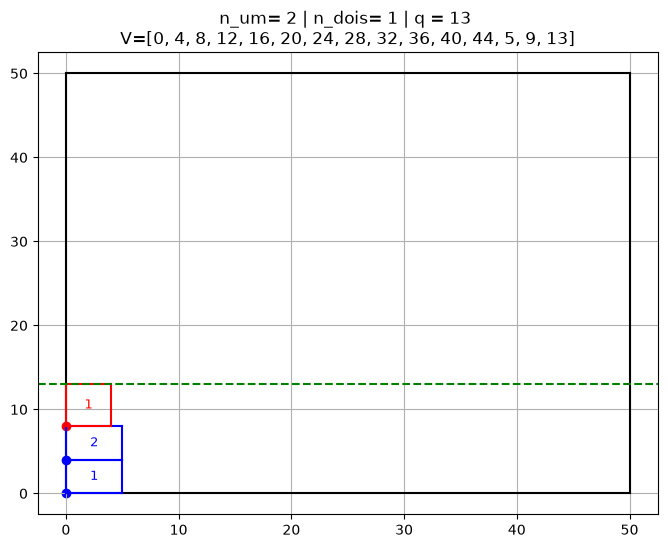

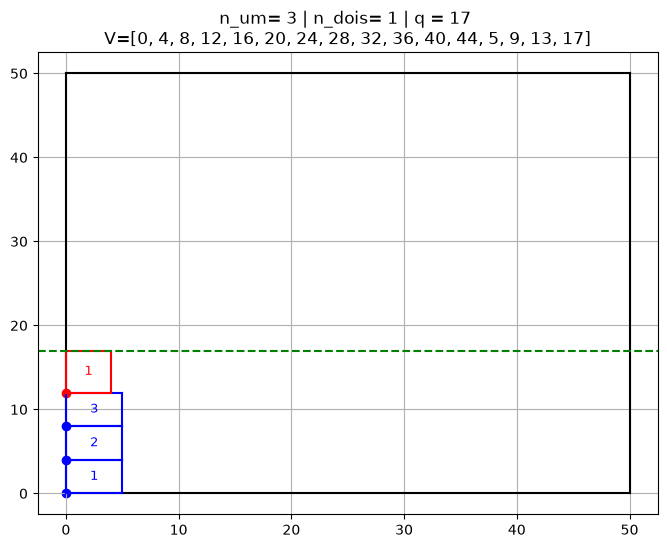

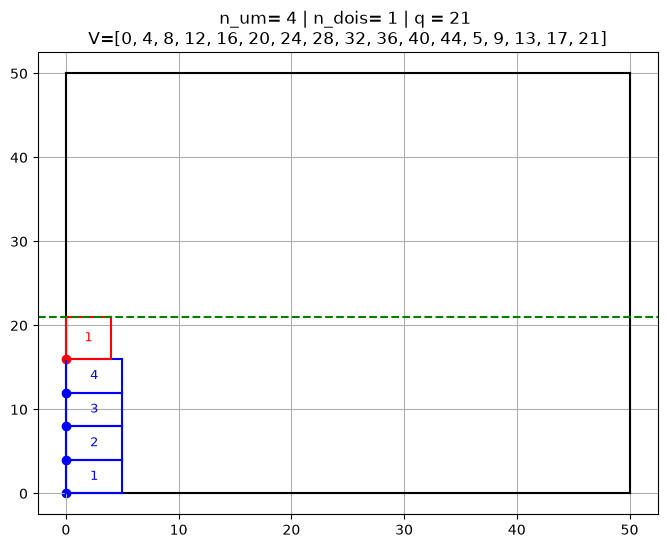

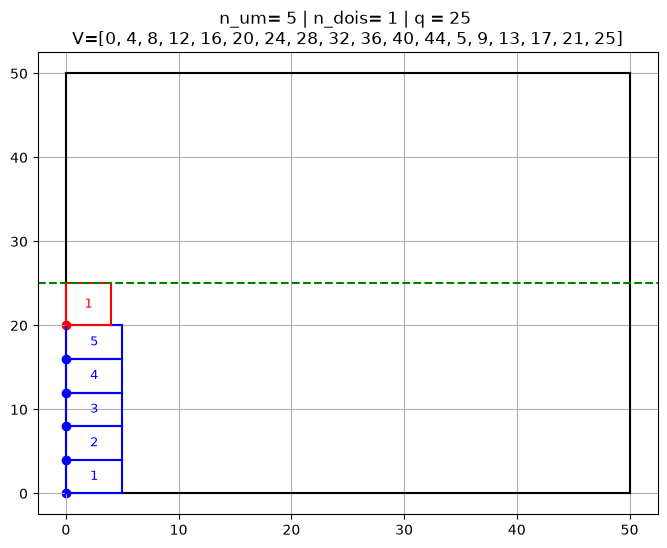

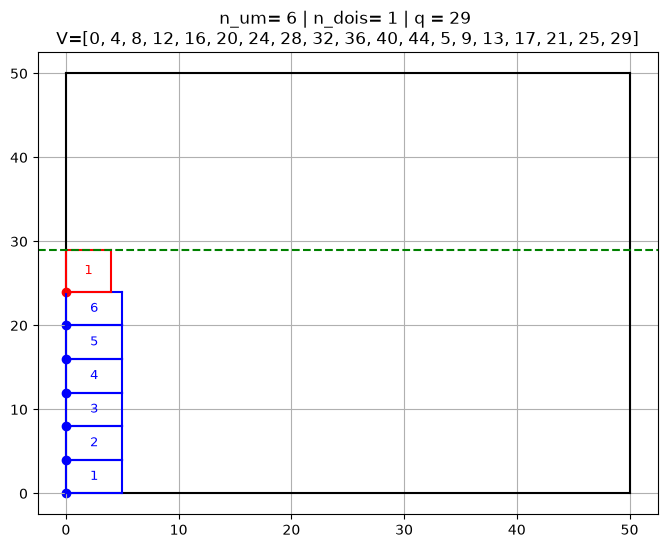

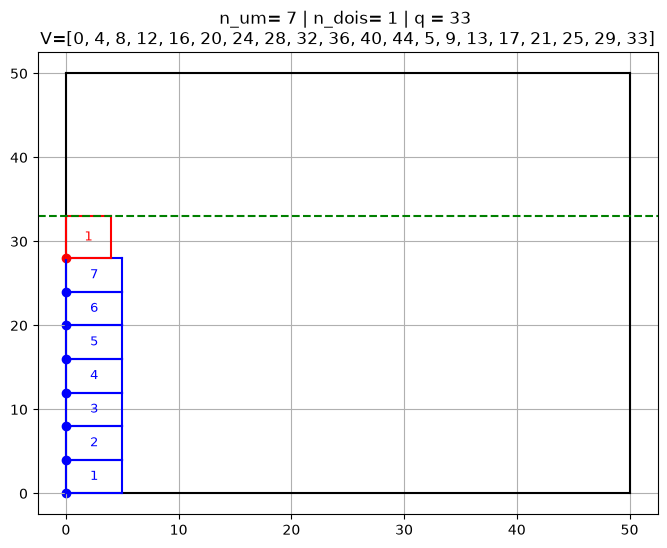

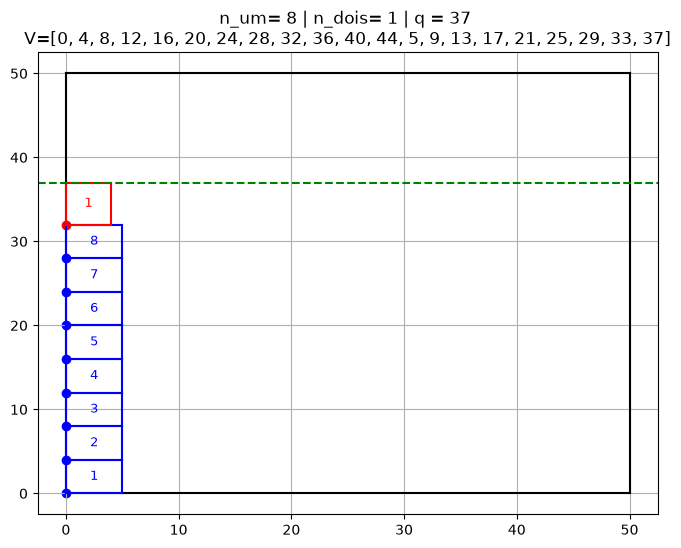

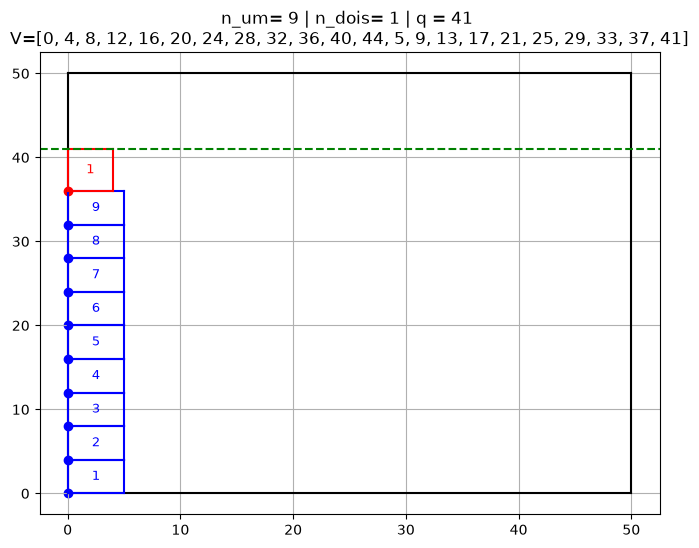

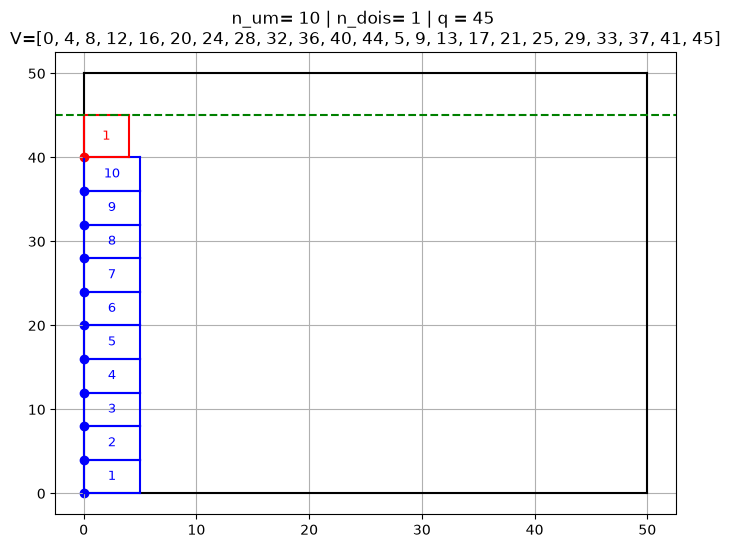

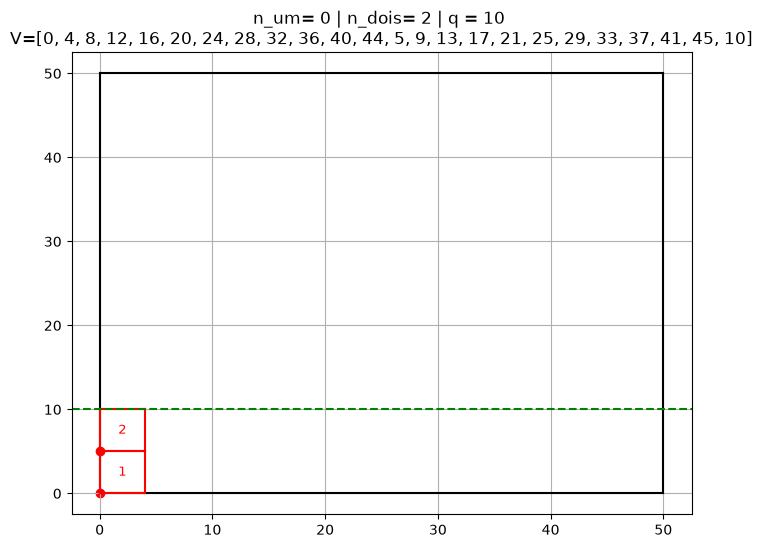

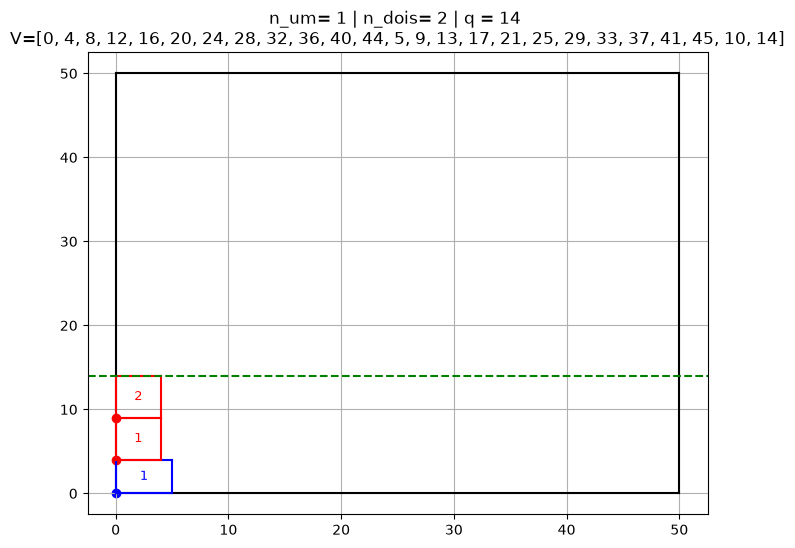

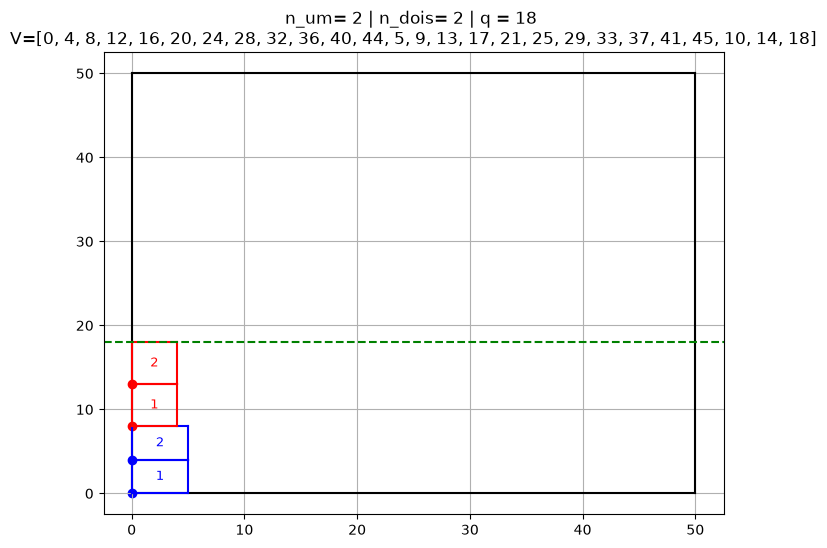

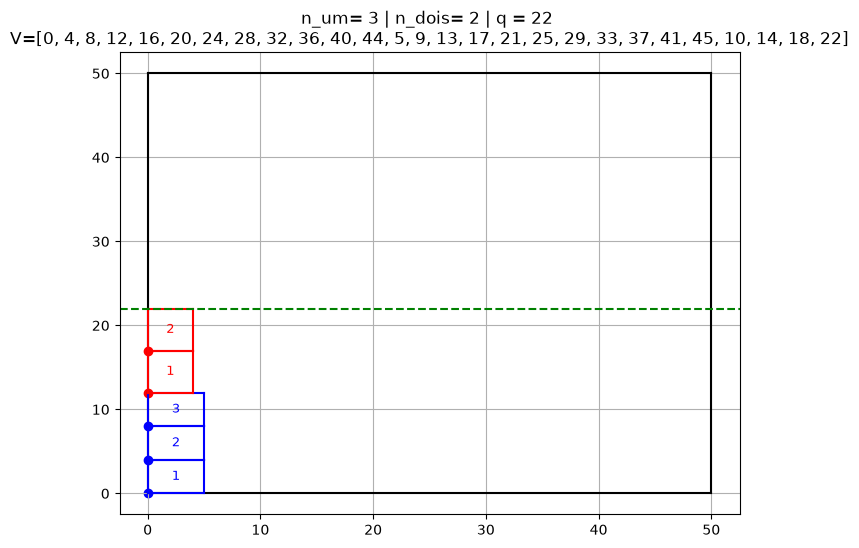

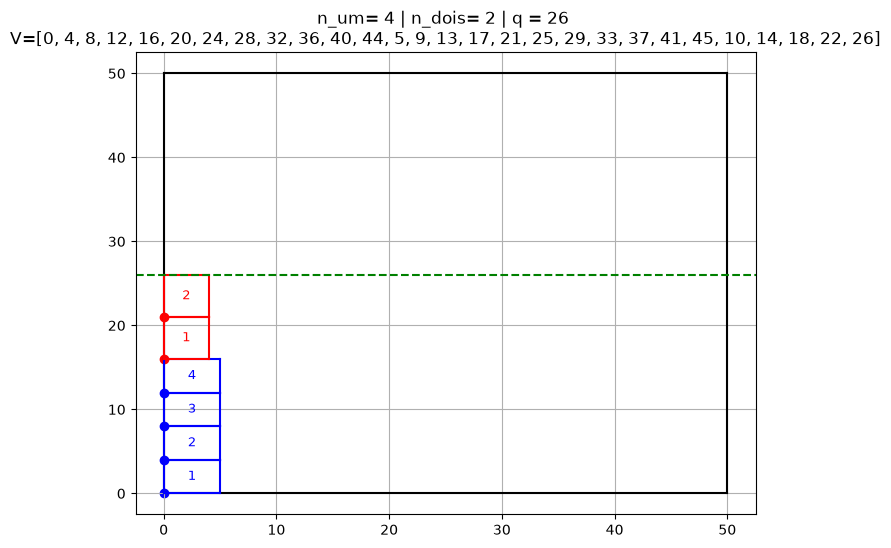

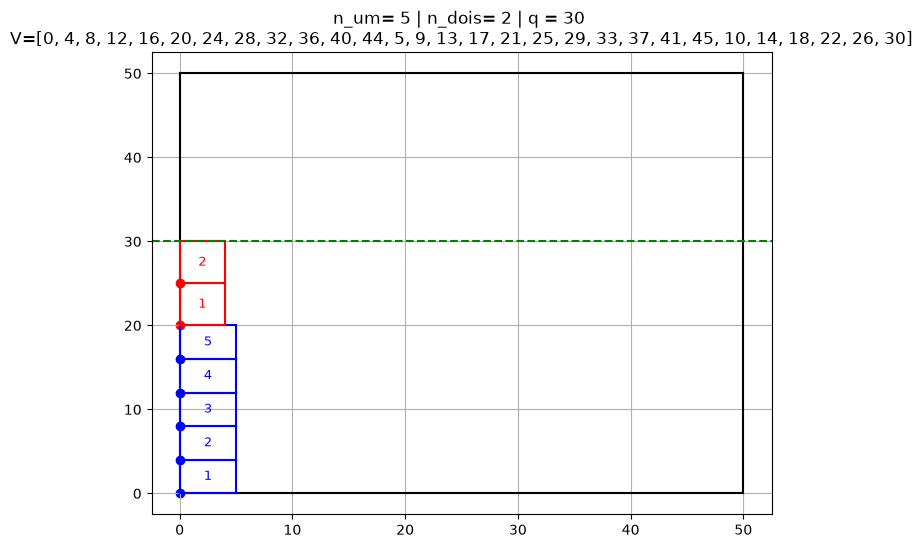

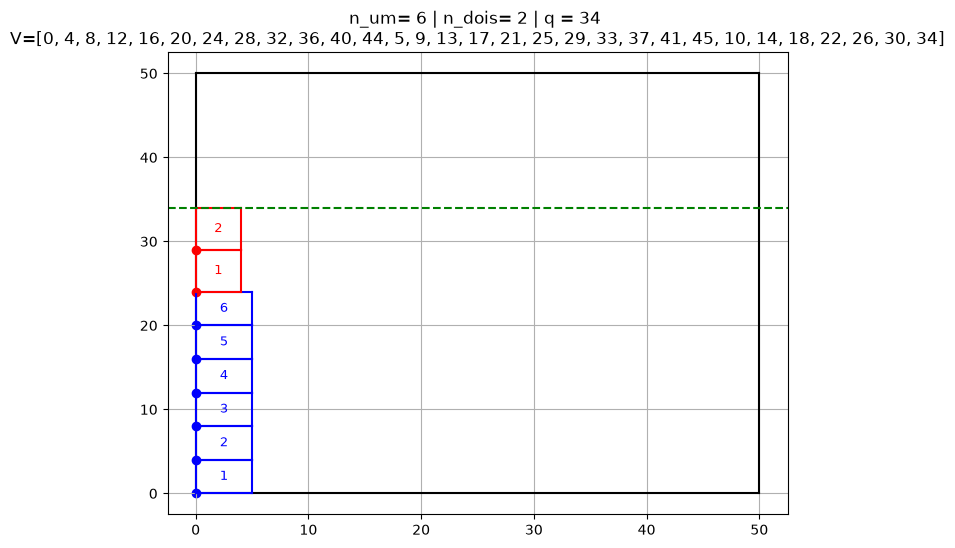

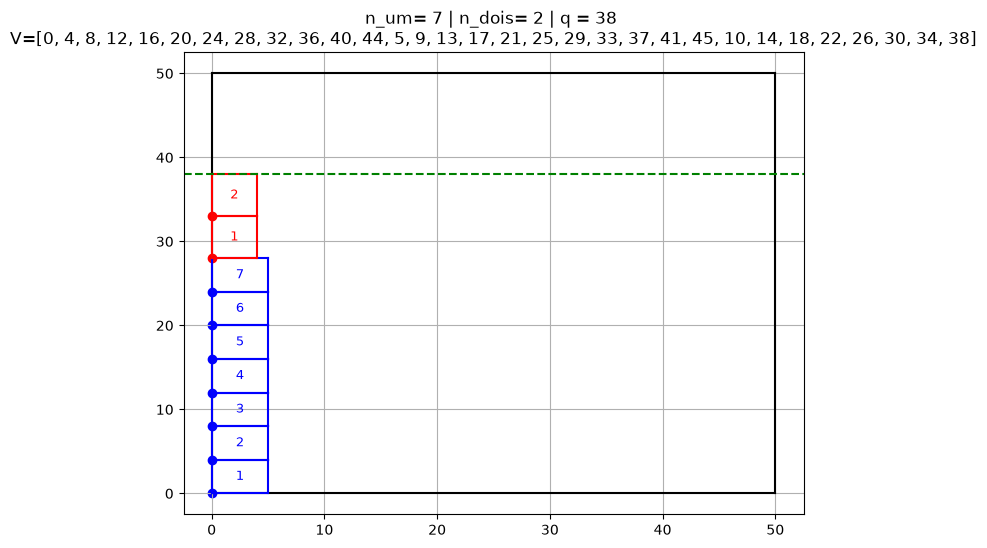

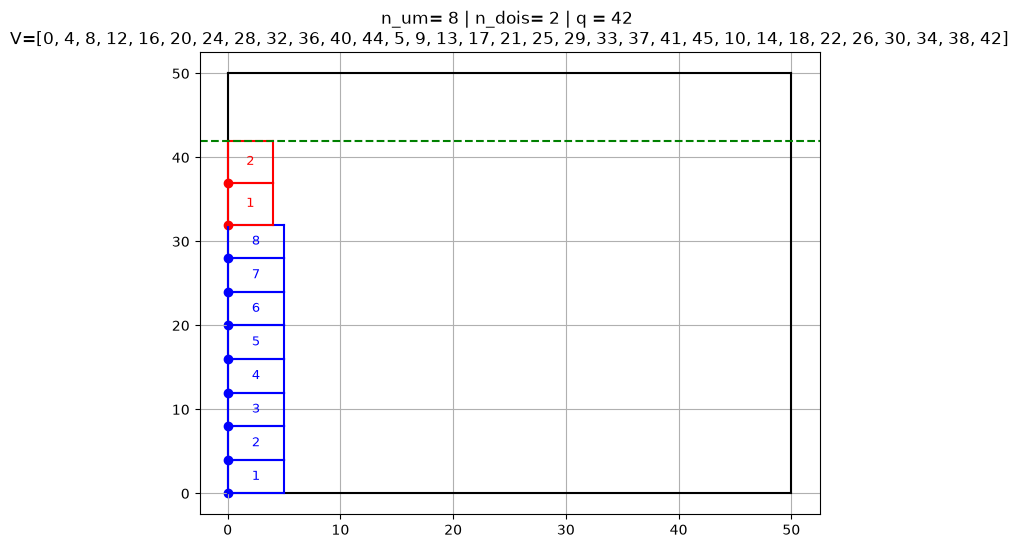

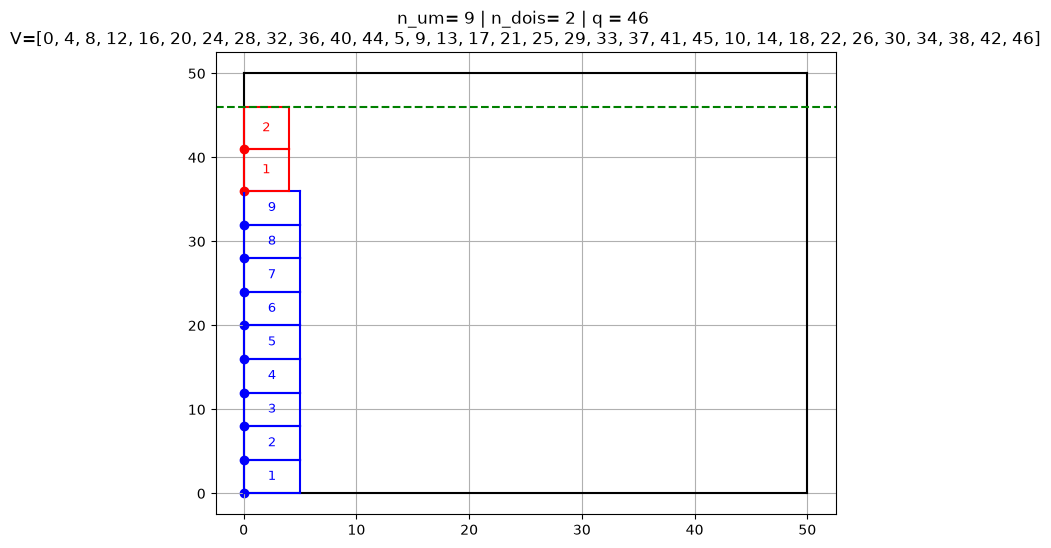

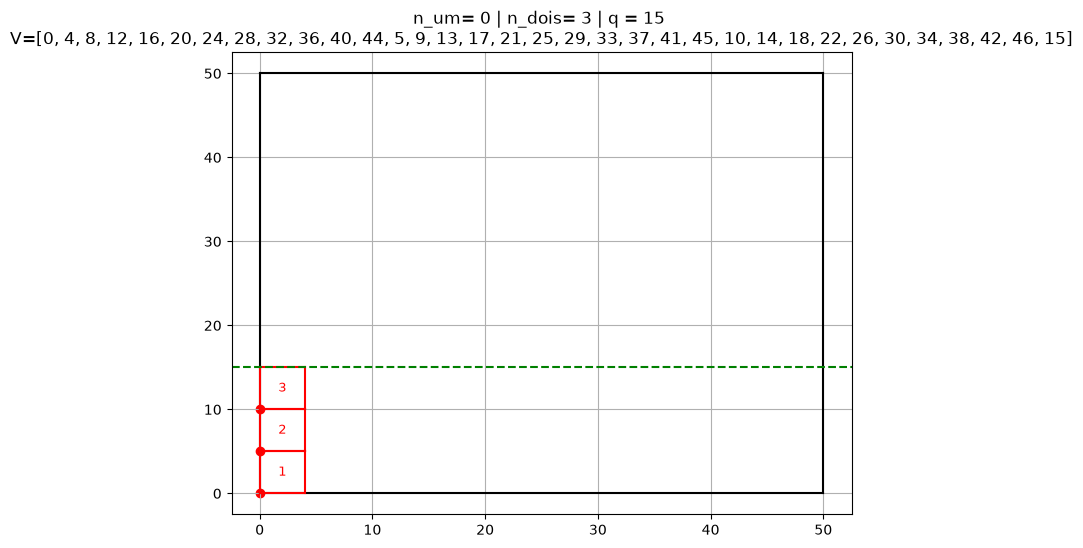

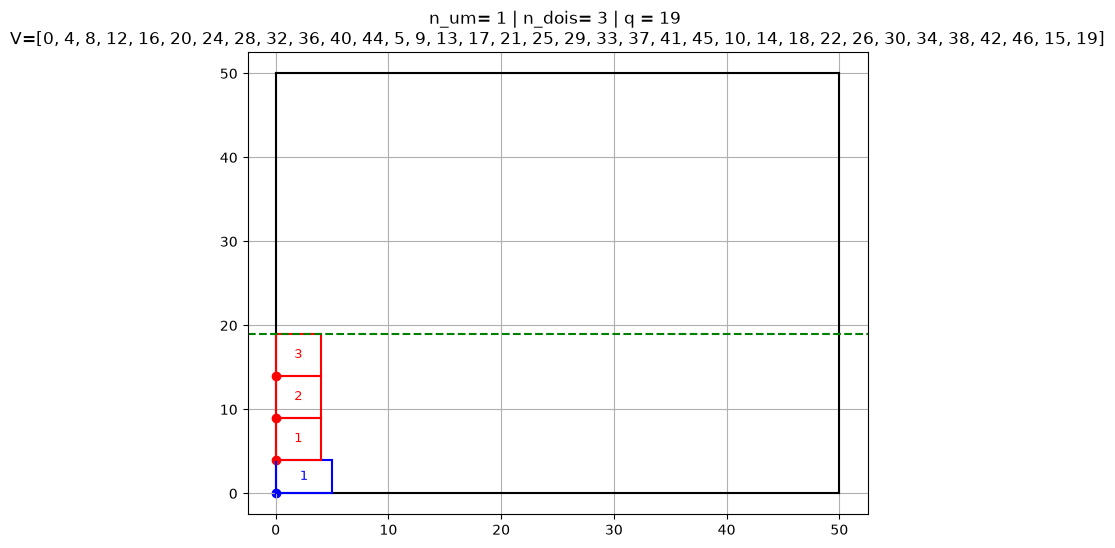

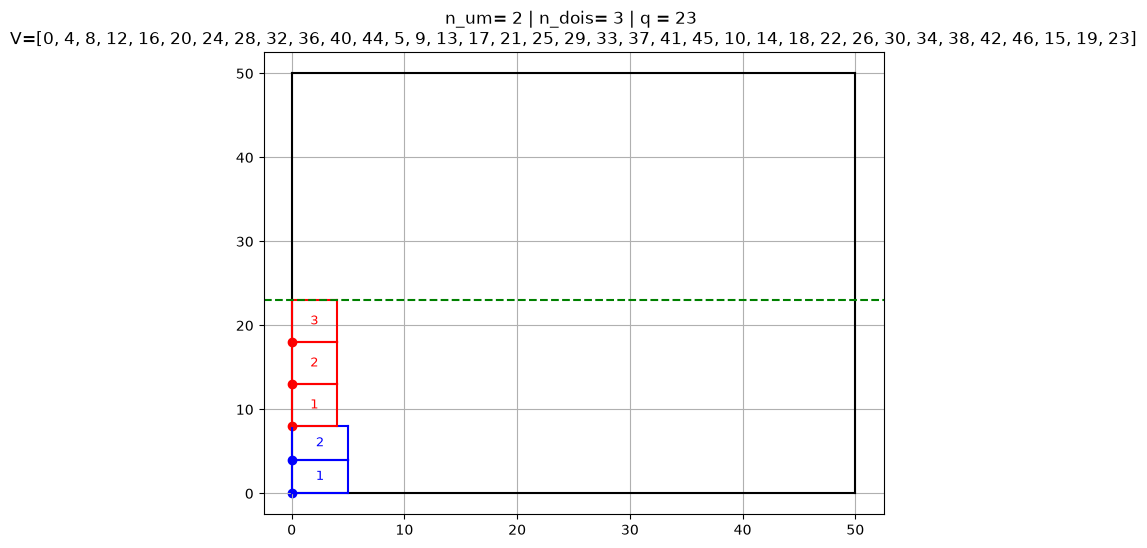

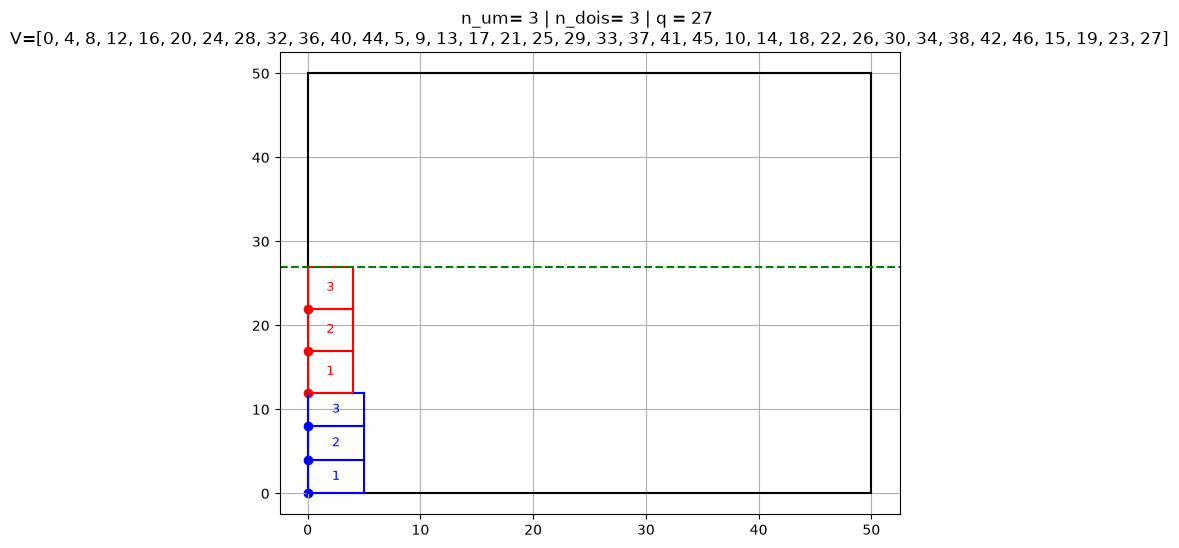

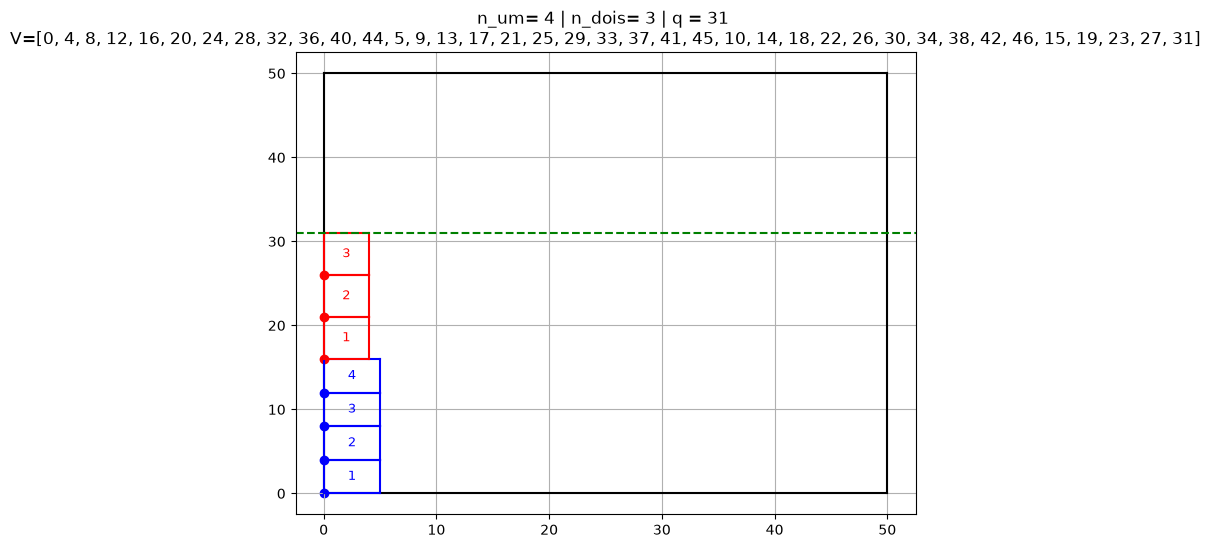

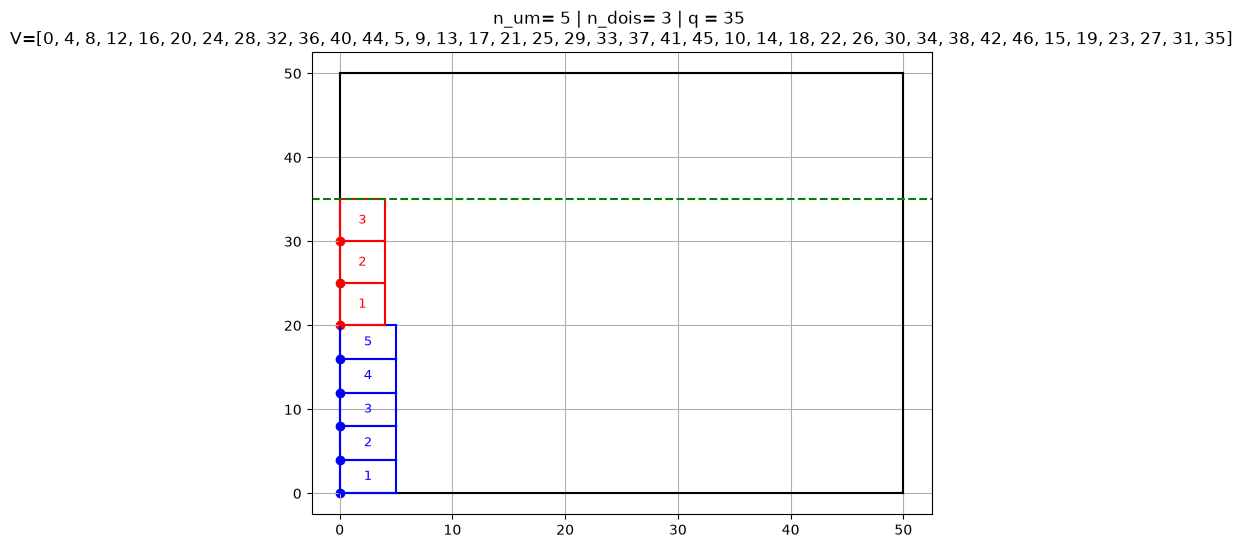

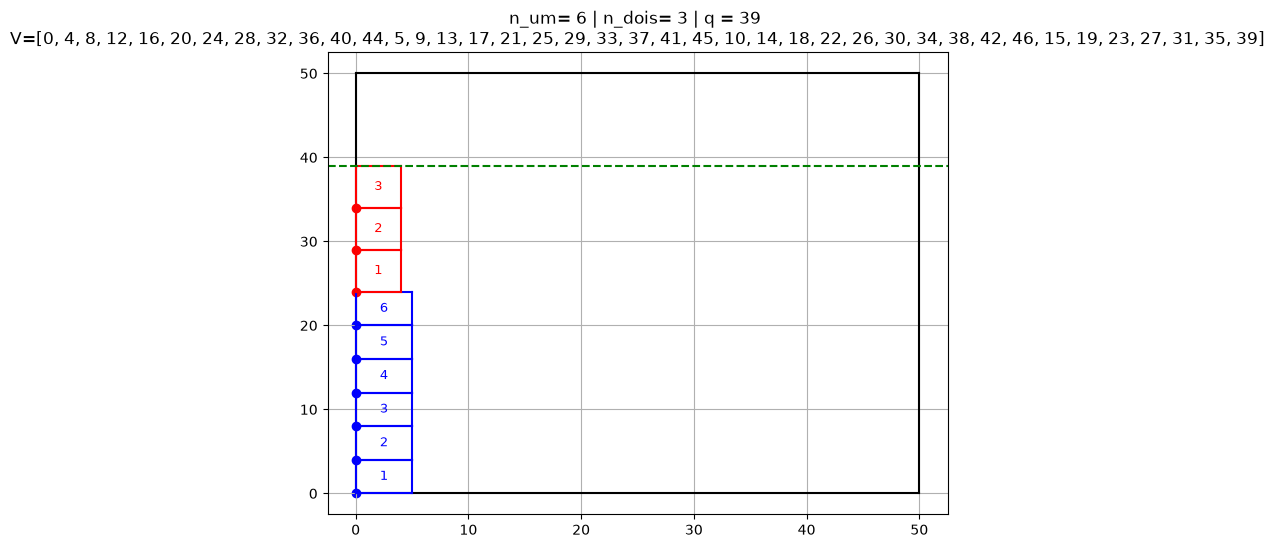

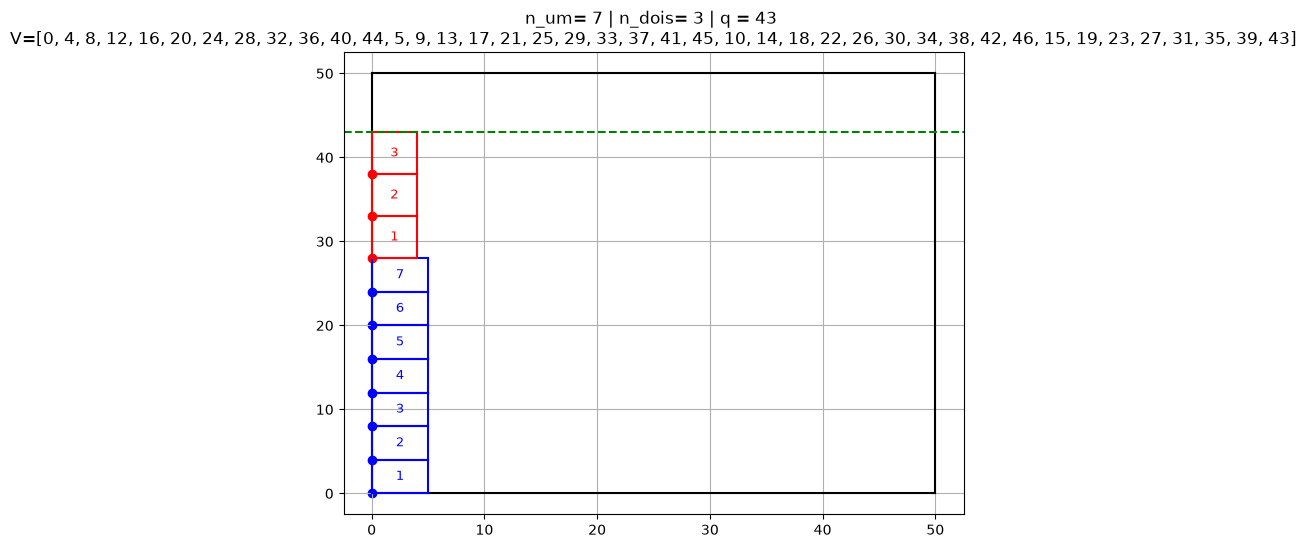

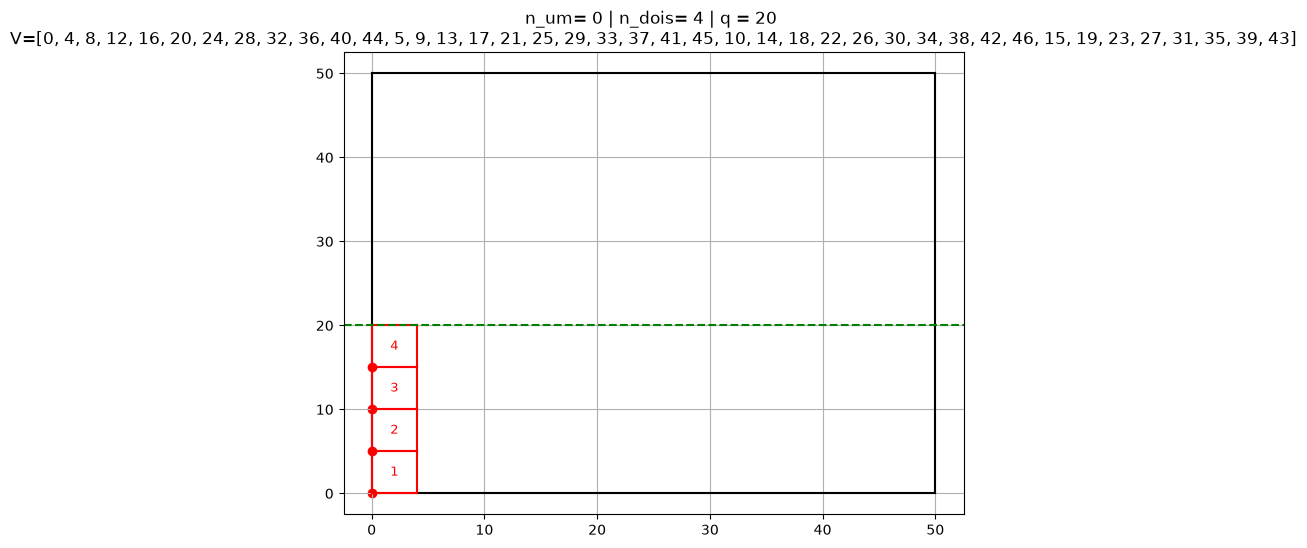

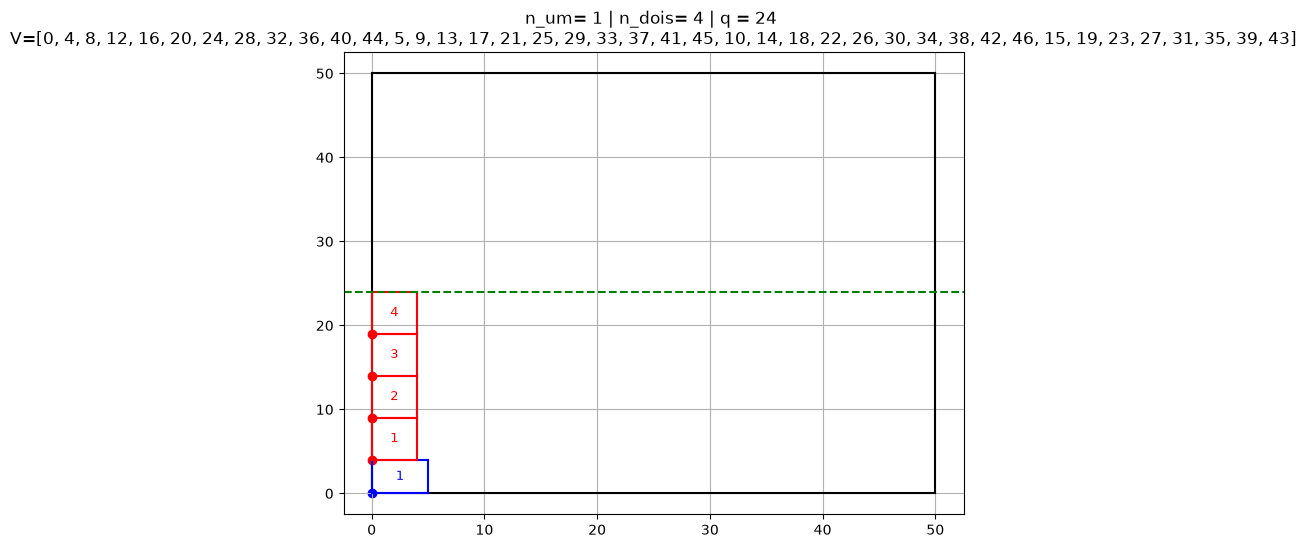

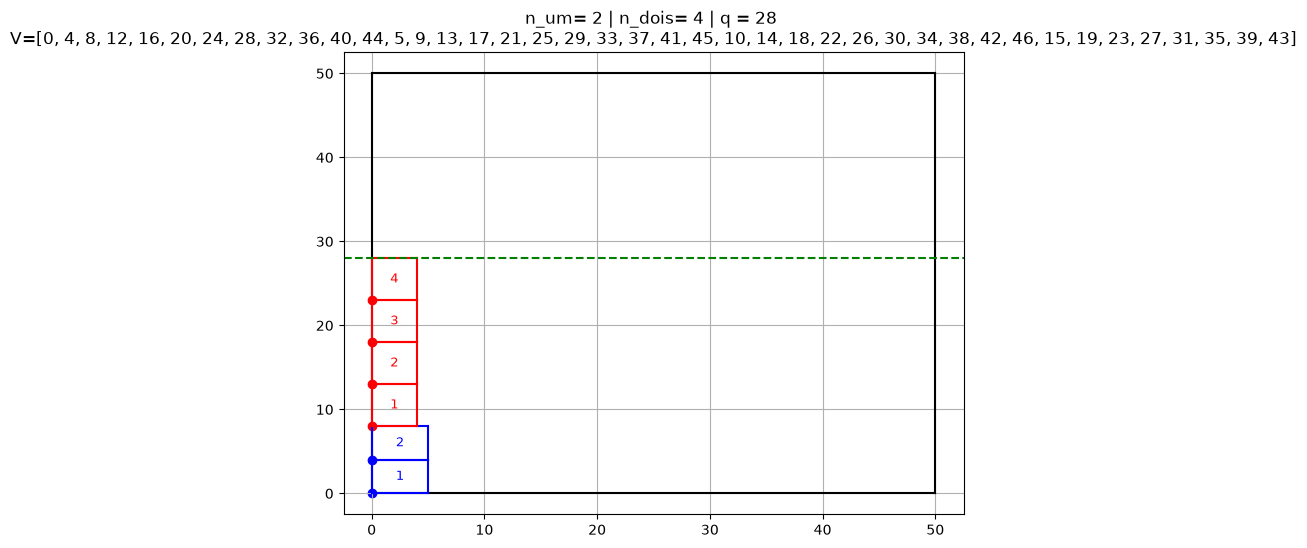

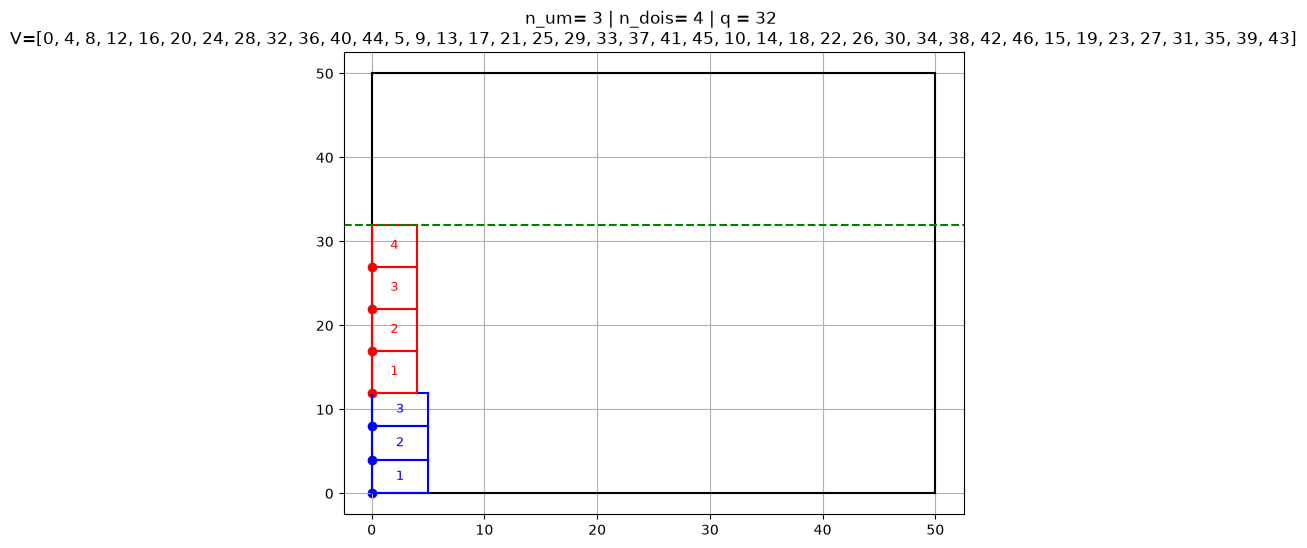

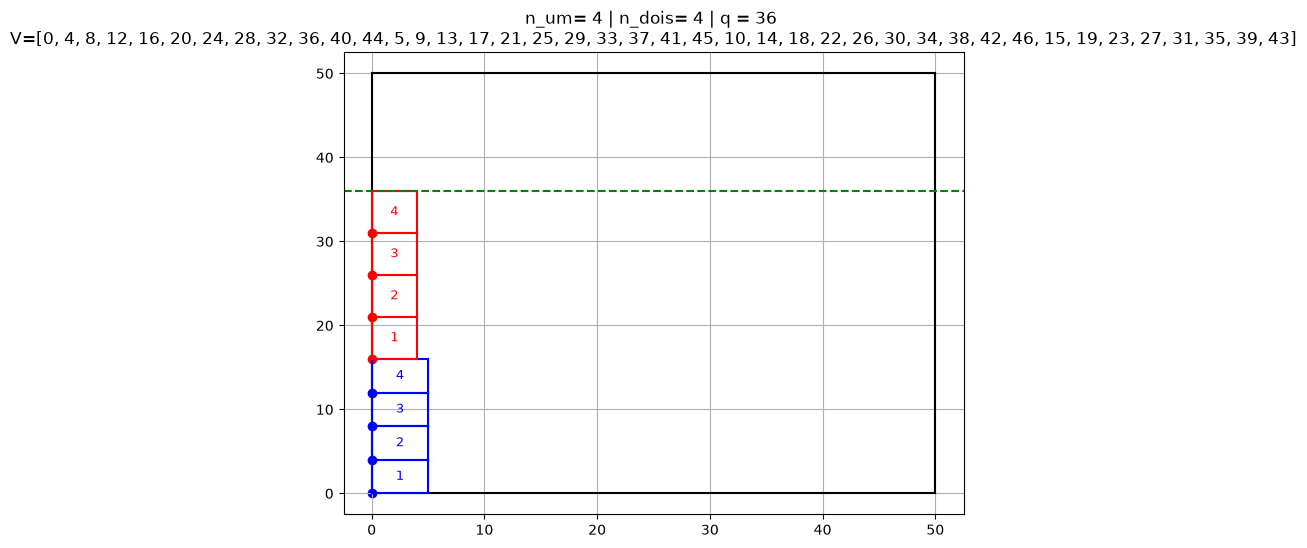

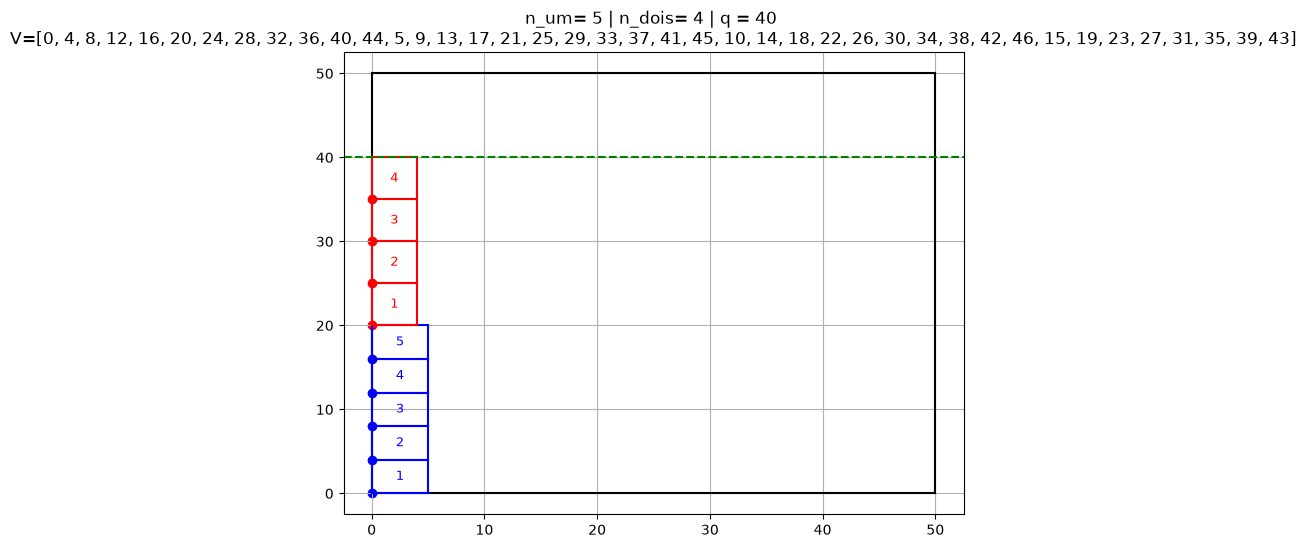

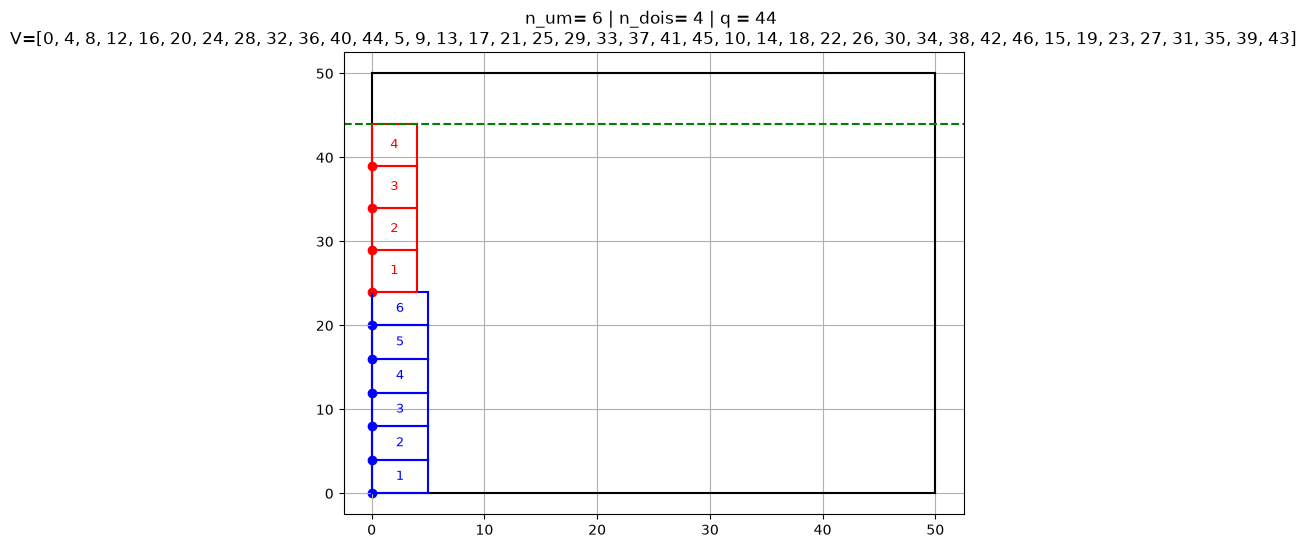

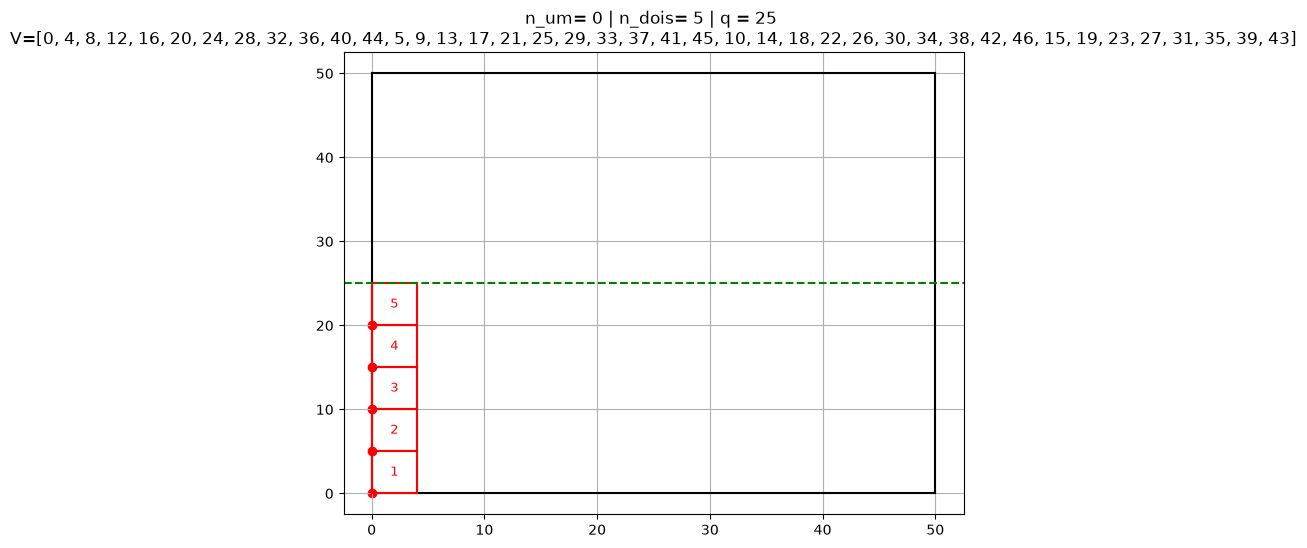

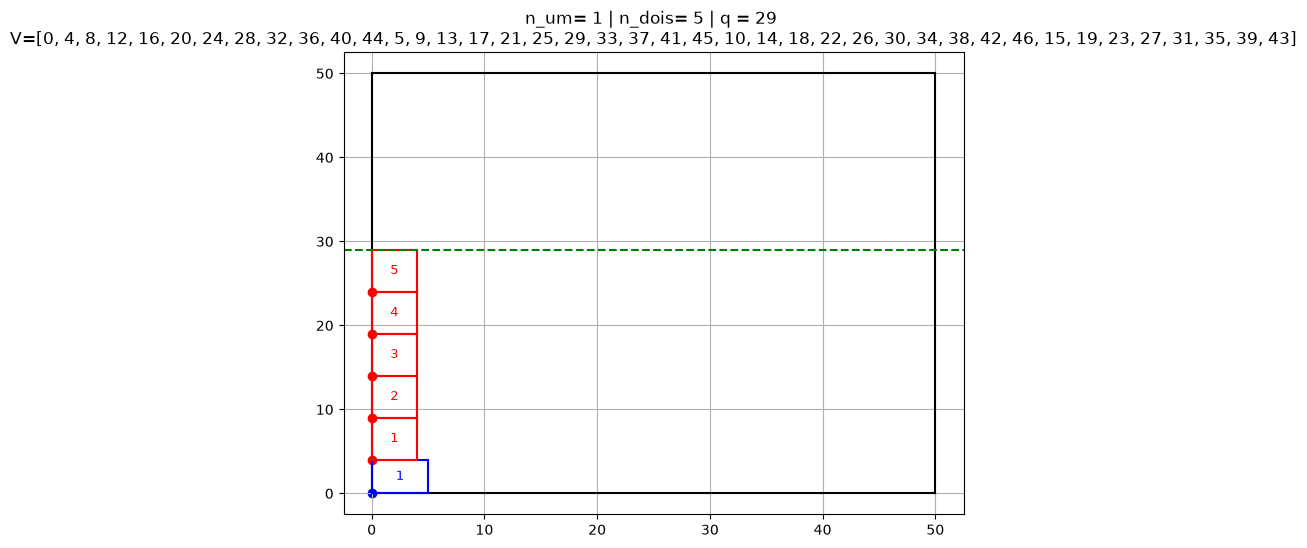

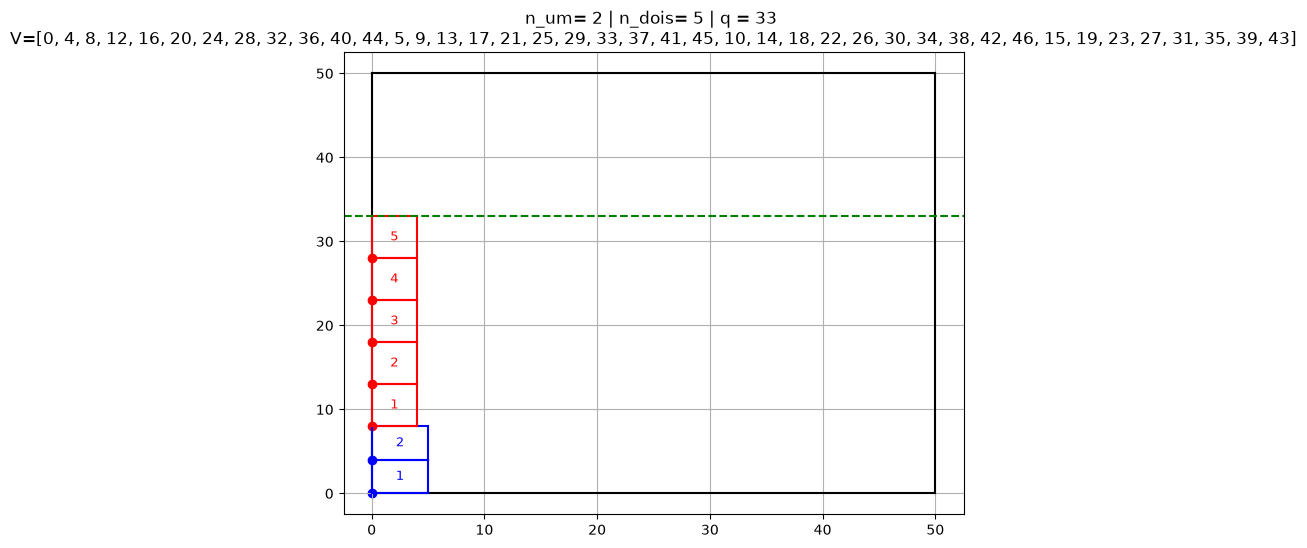

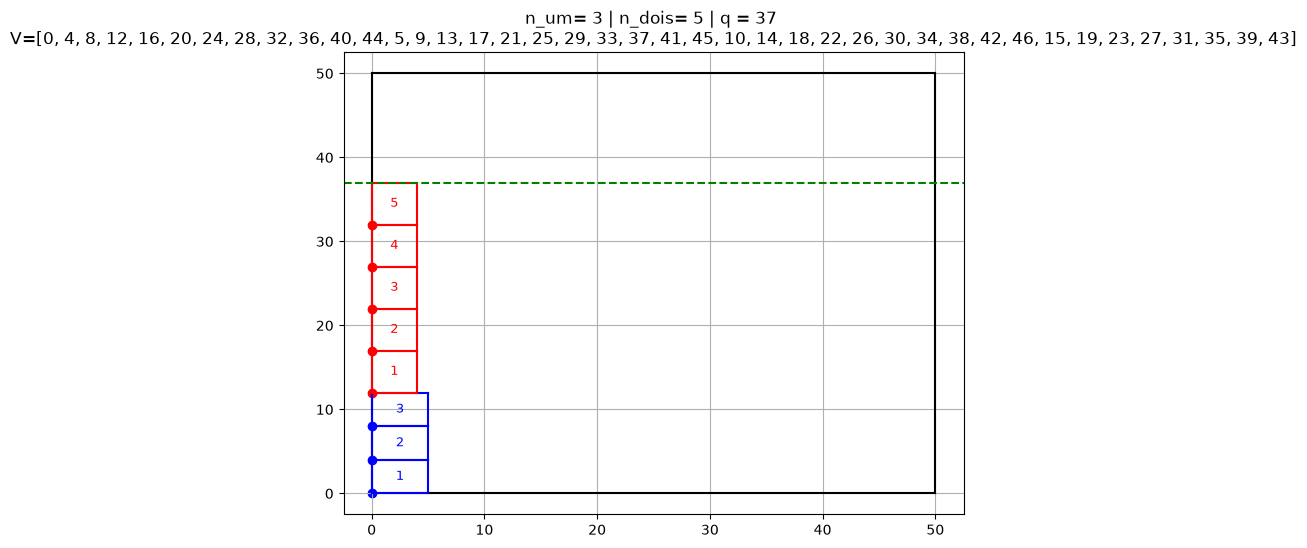

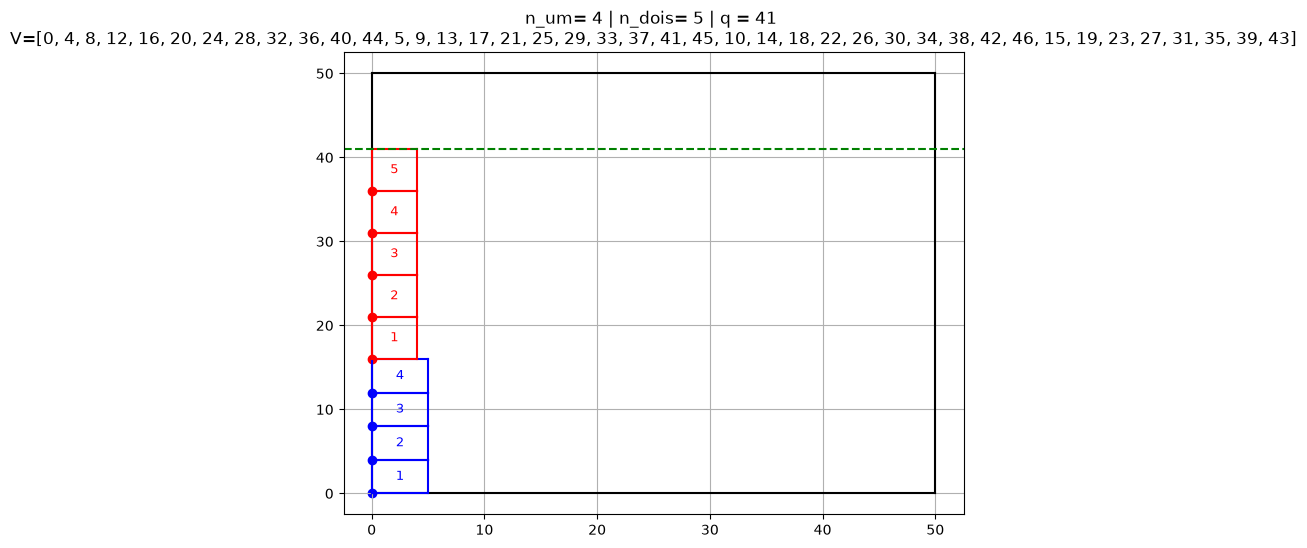

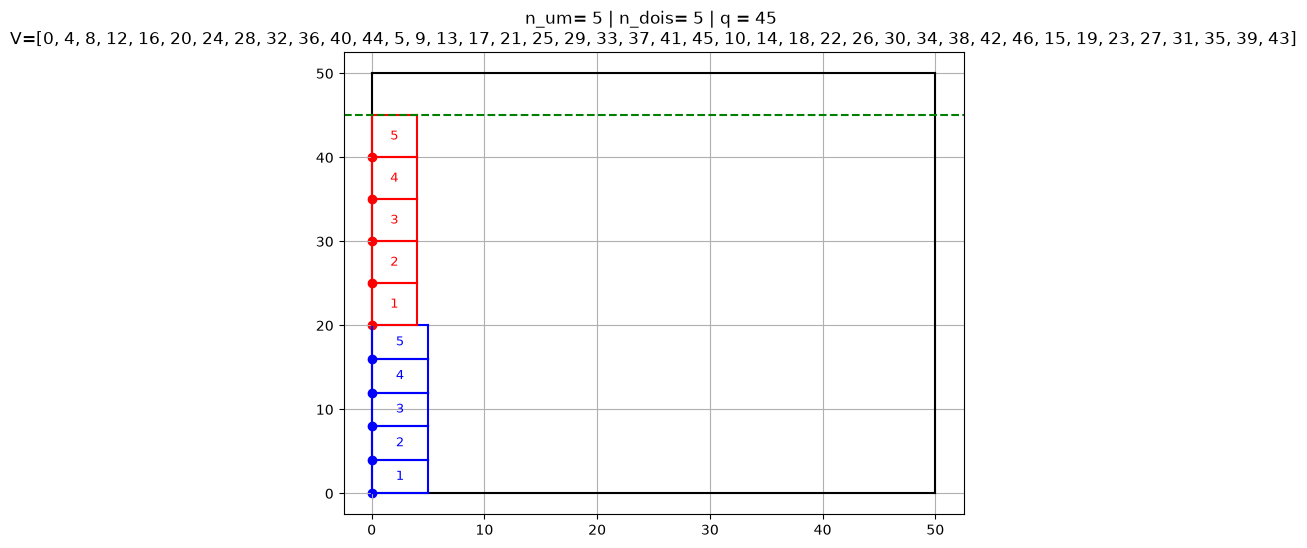

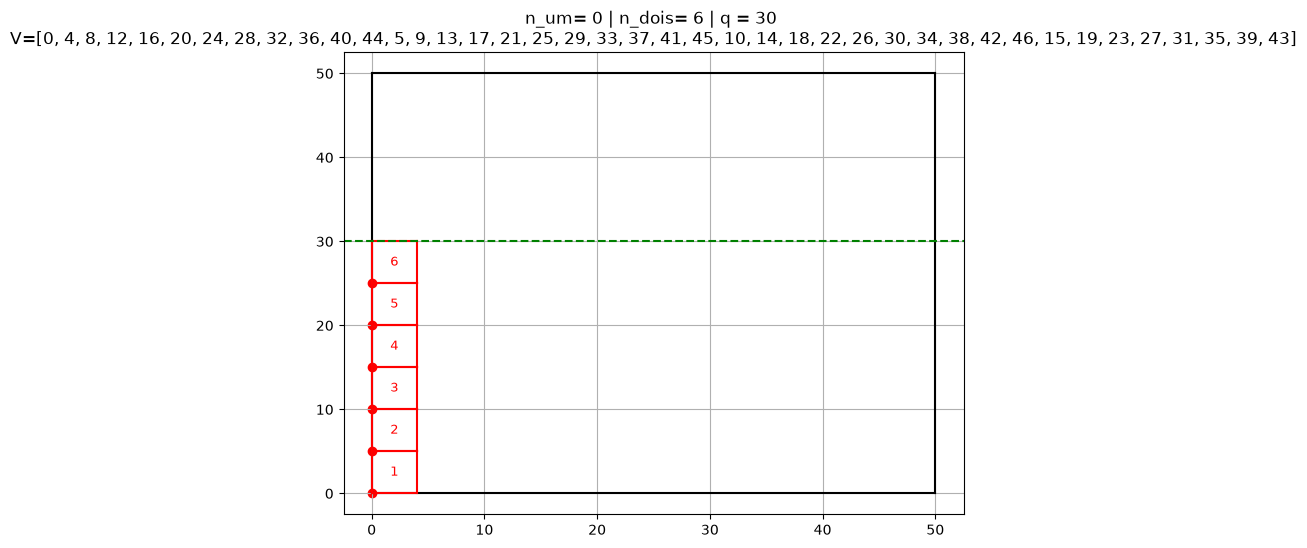

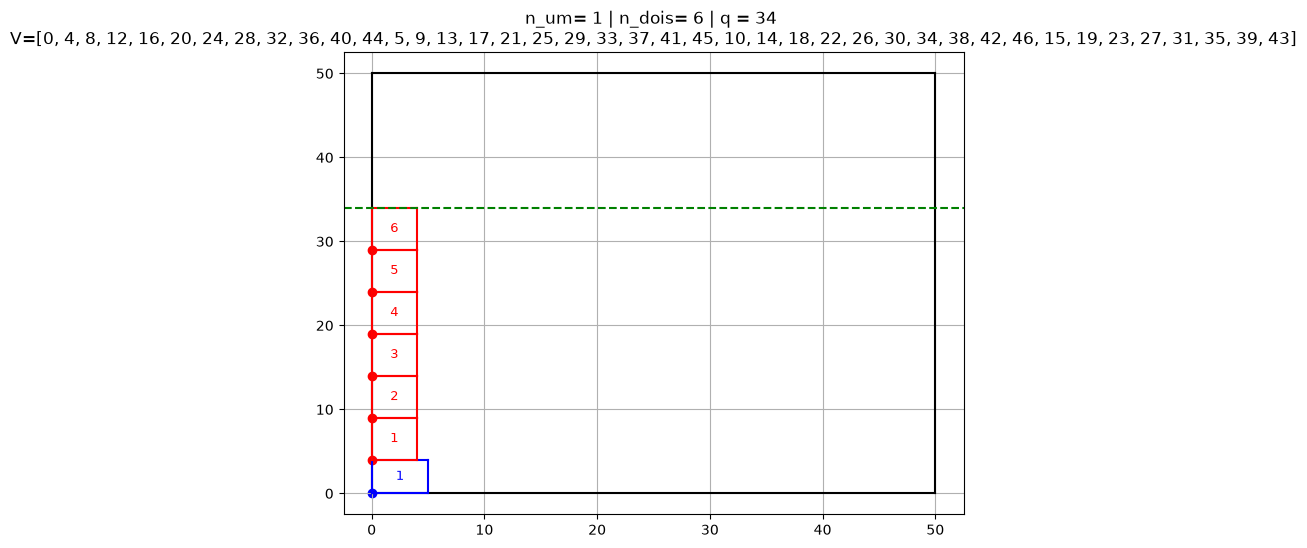

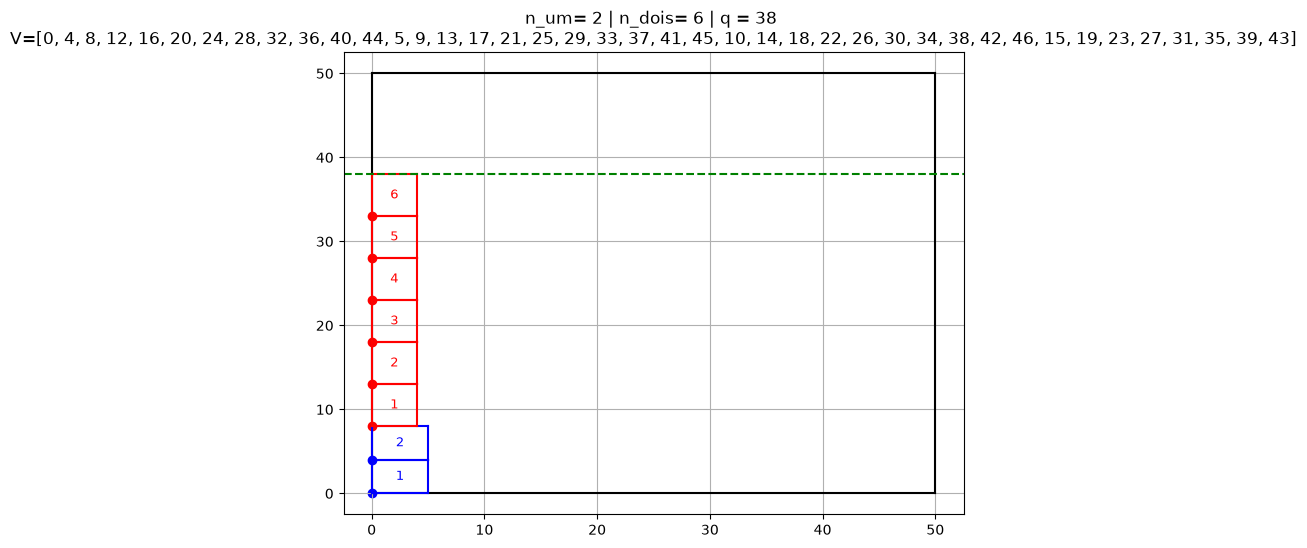

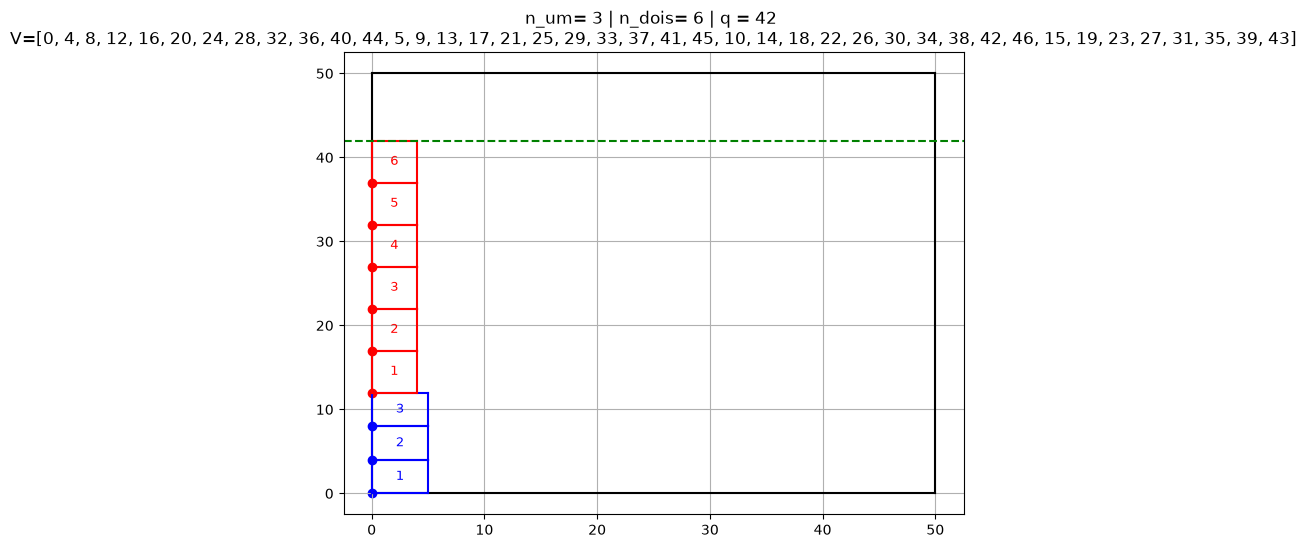

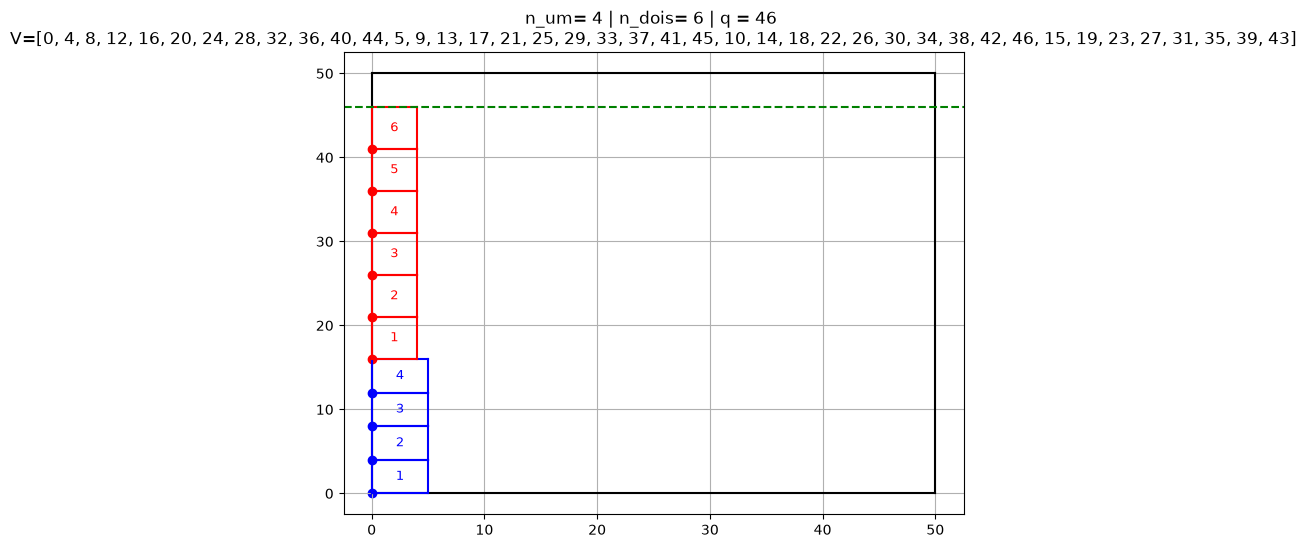

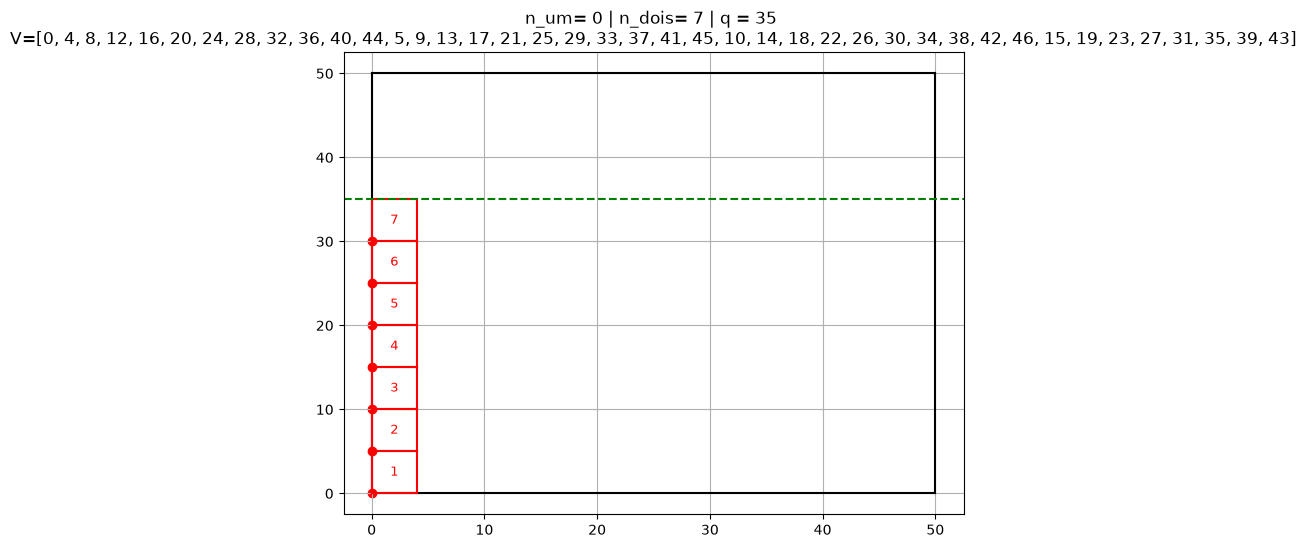

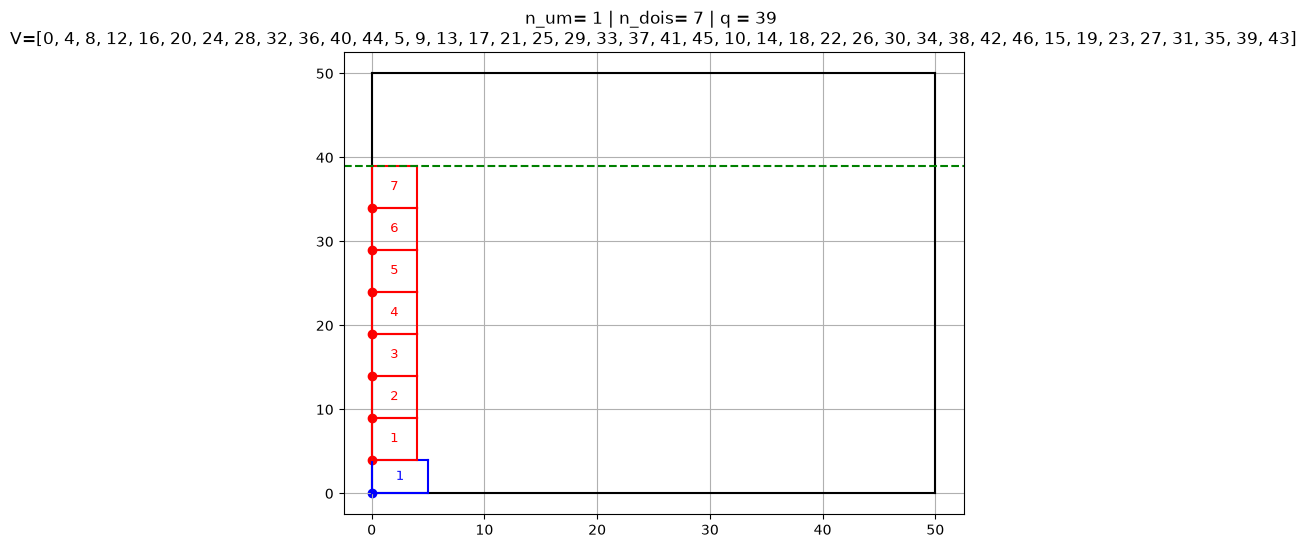

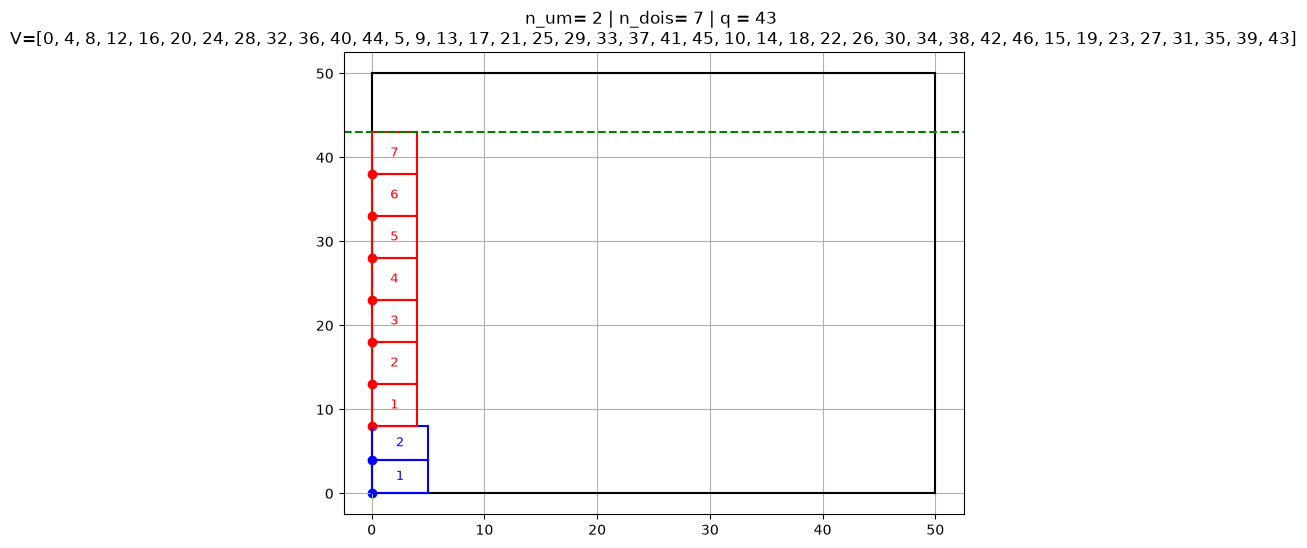

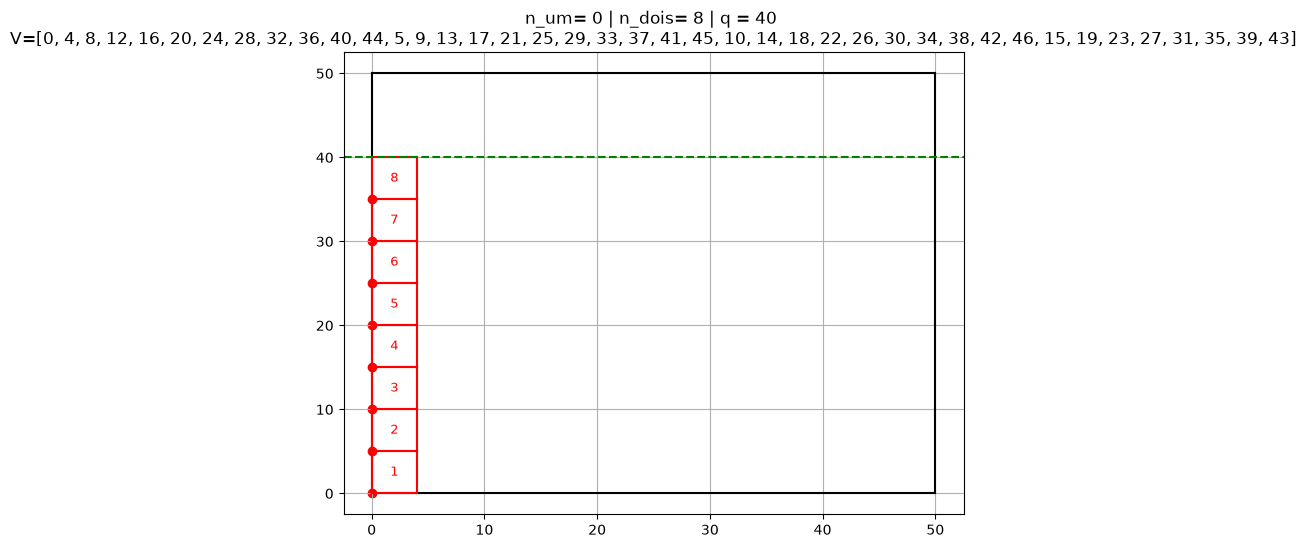

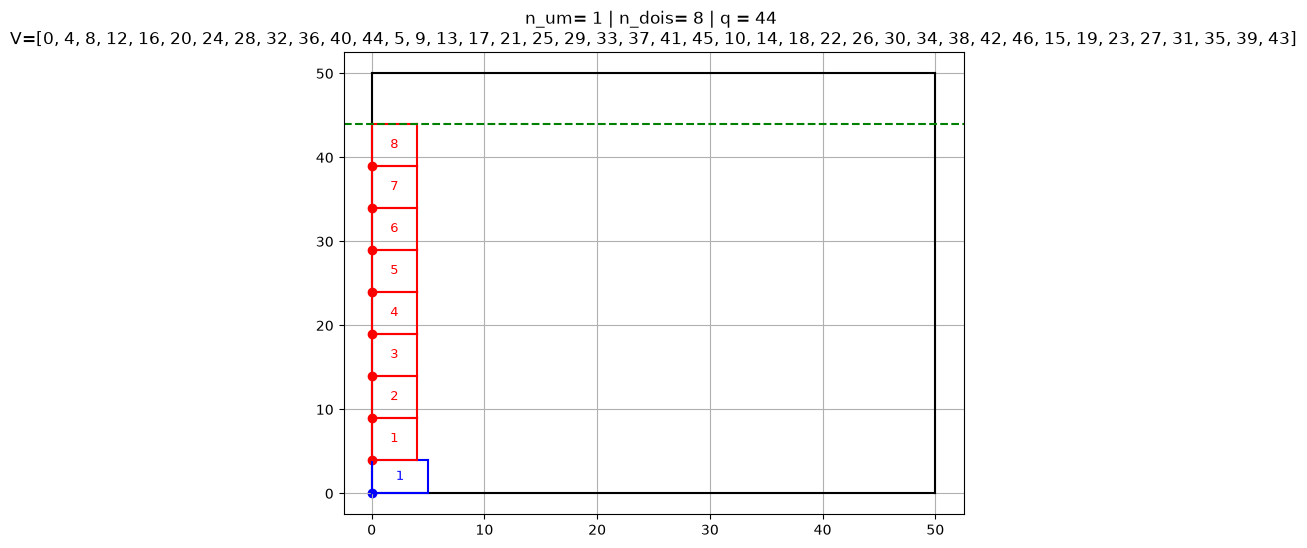

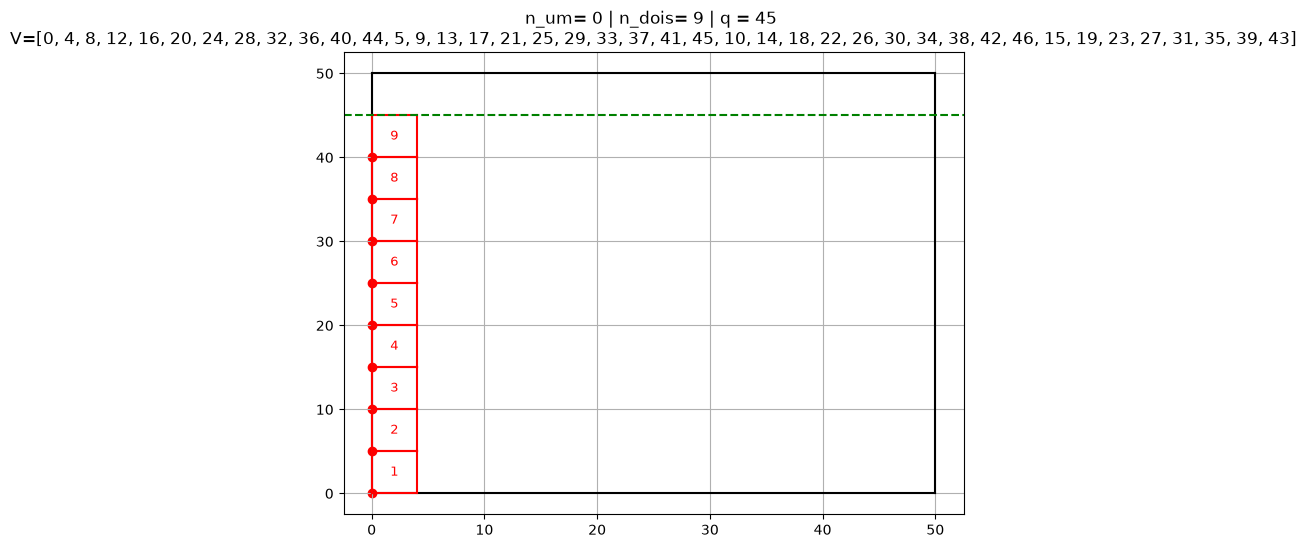

In [15]:
V = []
for n_dois, n_um in product(range(L), range(L)): # product um com todos, todos com um
    #print(n_um, n_dois)
    q = f_dois(n_um, w_um, n_dois, w_dois)
    #print(n_um, n_dois, q) # deixar o for sem repetir
    if q <= W - w_um:

        if q not in V:
            V.append(q)

        plotar_palete(L,W)

        for n in range(n_um):
            plotar_caixa(bottom_left=[0, n*w_um], l=l_um, w=w_um,
            color = "blue", label = n+1)

        for n in range(n_dois):
            plotar_caixa(bottom_left=[0, n_um * w_um + n * w_dois],
                         l=l_dois, w=w_dois, color="red",
                         label =n+1)

        plt.axhline(y=q, color="green", linestyle="--")
        plt.title(f"{n_um= } | {n_dois= } | {q = } \n{V=}")
        plt.grid()

In [16]:
H = sorted(H)
V = sorted(V)

print(H)
print(V)

[0, 4, 5, 8, 9, 10, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46]
[0, 4, 5, 8, 9, 10, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46]


In [17]:
lista_rs = list(product(H,V)) # rs, combinatários entre todos os H x V (Horizontal x Vertical) o 6,4 não é validado tem que ser eliminado
display(lista_rs)

[(0, 0),
 (0, 4),
 (0, 5),
 (0, 8),
 (0, 9),
 (0, 10),
 (0, 12),
 (0, 13),
 (0, 14),
 (0, 15),
 (0, 16),
 (0, 17),
 (0, 18),
 (0, 19),
 (0, 20),
 (0, 21),
 (0, 22),
 (0, 23),
 (0, 24),
 (0, 25),
 (0, 26),
 (0, 27),
 (0, 28),
 (0, 29),
 (0, 30),
 (0, 31),
 (0, 32),
 (0, 33),
 (0, 34),
 (0, 35),
 (0, 36),
 (0, 37),
 (0, 38),
 (0, 39),
 (0, 40),
 (0, 41),
 (0, 42),
 (0, 43),
 (0, 44),
 (0, 45),
 (0, 46),
 (4, 0),
 (4, 4),
 (4, 5),
 (4, 8),
 (4, 9),
 (4, 10),
 (4, 12),
 (4, 13),
 (4, 14),
 (4, 15),
 (4, 16),
 (4, 17),
 (4, 18),
 (4, 19),
 (4, 20),
 (4, 21),
 (4, 22),
 (4, 23),
 (4, 24),
 (4, 25),
 (4, 26),
 (4, 27),
 (4, 28),
 (4, 29),
 (4, 30),
 (4, 31),
 (4, 32),
 (4, 33),
 (4, 34),
 (4, 35),
 (4, 36),
 (4, 37),
 (4, 38),
 (4, 39),
 (4, 40),
 (4, 41),
 (4, 42),
 (4, 43),
 (4, 44),
 (4, 45),
 (4, 46),
 (5, 0),
 (5, 4),
 (5, 5),
 (5, 8),
 (5, 9),
 (5, 10),
 (5, 12),
 (5, 13),
 (5, 14),
 (5, 15),
 (5, 16),
 (5, 17),
 (5, 18),
 (5, 19),
 (5, 20),
 (5, 21),
 (5, 22),
 (5, 23),
 (5, 24),
 (5, 

In [18]:
# pontos possiveis
if indice ==0:
    plotar_palete(L,W)
    for r,s in lista_rs:
        plt.scatter(x=r, y=s, color = "purple")

    plt.title("Possibilidade de bottom-left para as caixas")
    plt.grid()
    plt.show()

In [19]:
# ls lista dos dois s
# ws lists dos dois w

ls= [l_um, l_dois]
ws= [w_um, w_dois]

In [20]:
#i =1
#print(ls[i], ws[i]) # aqui comeca em 2

In [21]:
i =1
print(ls[i-1], ws[i-1]) # agora começa em 0

5 4


In [22]:
# # Lista de tupla para montar a Função Objetiva
# plotar_palete(L,W)
# for i, (p, q) in product([1,2], lista_rs):
#     print(i,p,q)

In [23]:
# # Lista de tupla para montar a Função Objetiva 
# lista_variaveis = []
# plotar_palete(L, W)
# for (p, q), i in product(lista_rs, [1,2]):
#     #print(i,p,q)
#     # i = 1 (caixa deitada)
#     # i = 2 (caixa em pé)
#     if p +ls[i-1] <= L and q + ws[i-1] <=W: # checa se cabe no palete, se futuro é O ou 1 (cabe ou não cabe)
#         lista_variaveis.append((i,p,q)) # tulpa i,p,q

#     if indice == 0:
#         cor = "blue" if i==1 else "red"
#         plt.scatter(x=p, y=q, color=cor) # plotar o bottom-leff

#         if i==1: #caixa deitada
#             plt.text(x=p - 0.3, y=q + 0.15, s=f"{i},{p},{q}",
#             color=cor, fontsize=10)

#         else: # caixa sendo 2 em pé
#             plt.text(x=p - 0.3, y=q - 0.25, s=f"{i},{p},{q}",
#             color=cor, fontsize=10)

# o codigo acima não está filtrado os pontos no codigo abaixo os if´s estão em cascata

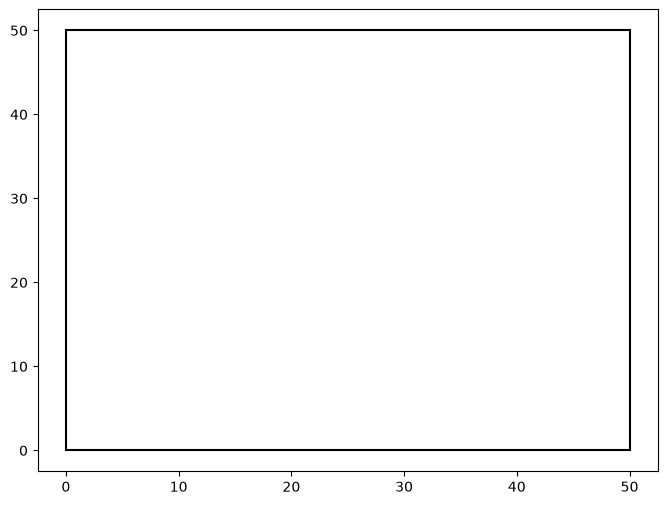

In [24]:
# Lista de tupla para montar a Função Objetiva
lista_variaveis = []
plotar_palete(L, W)
for (p, q), i in product(lista_rs, [1,2]): # poderia ser r e s
    #print(i,p,q)
    # i = 1 (caixa deitada)
    # i = 2 (caixa em pé)
    if p +ls[i-1] <= L and q + ws[i-1] <=W: # checa se cabe no palete, se futuro é O ou 1 (cabe ou não cabe)
        lista_variaveis.append((i,p,q)) # tulpa i,p,q

        if indice == 0:
            cor = "blue" if i==1 else "red"
            plt.scatter(x=p, y=q, color=cor) # plotar o bottom-leff

            if i==1: #caixa deitada
                plt.text(x=p - 0.3, y=q + 0.15, s=f"{i},{p},{q}",
                color=cor, fontsize=10)

            else: # caixa sendo 2 em pé
                plt.text(x=p - 0.3, y=q - 0.25, s=f"{i},{p},{q}",
                color=cor, fontsize=10)

In [25]:
print(len(lista_variaveis))

3280


In [26]:
prob = plp.LpProblem(name="Palete_caixa",
                     sense=plp.LpMaximize)
display(prob)

Palete_caixa:
MAXIMIZE
None
VARIABLES

In [27]:
# transforma a lista de variaveis

dict_variaveis = plp.LpVariable.dicts(name="C", indices=lista_variaveis,
                                lowBound=0, upBound=1,
                                cat=plp.LpBinary) # transforma a tupla em O ou 1 o pulp fez isso

display(dict_variaveis) #dicionário (1,0,0) C_(1,0,0) valores

{(1, 0, 0): C_(1,_0,_0),
 (2, 0, 0): C_(2,_0,_0),
 (1, 0, 4): C_(1,_0,_4),
 (2, 0, 4): C_(2,_0,_4),
 (1, 0, 5): C_(1,_0,_5),
 (2, 0, 5): C_(2,_0,_5),
 (1, 0, 8): C_(1,_0,_8),
 (2, 0, 8): C_(2,_0,_8),
 (1, 0, 9): C_(1,_0,_9),
 (2, 0, 9): C_(2,_0,_9),
 (1, 0, 10): C_(1,_0,_10),
 (2, 0, 10): C_(2,_0,_10),
 (1, 0, 12): C_(1,_0,_12),
 (2, 0, 12): C_(2,_0,_12),
 (1, 0, 13): C_(1,_0,_13),
 (2, 0, 13): C_(2,_0,_13),
 (1, 0, 14): C_(1,_0,_14),
 (2, 0, 14): C_(2,_0,_14),
 (1, 0, 15): C_(1,_0,_15),
 (2, 0, 15): C_(2,_0,_15),
 (1, 0, 16): C_(1,_0,_16),
 (2, 0, 16): C_(2,_0,_16),
 (1, 0, 17): C_(1,_0,_17),
 (2, 0, 17): C_(2,_0,_17),
 (1, 0, 18): C_(1,_0,_18),
 (2, 0, 18): C_(2,_0,_18),
 (1, 0, 19): C_(1,_0,_19),
 (2, 0, 19): C_(2,_0,_19),
 (1, 0, 20): C_(1,_0,_20),
 (2, 0, 20): C_(2,_0,_20),
 (1, 0, 21): C_(1,_0,_21),
 (2, 0, 21): C_(2,_0,_21),
 (1, 0, 22): C_(1,_0,_22),
 (2, 0, 22): C_(2,_0,_22),
 (1, 0, 23): C_(1,_0,_23),
 (2, 0, 23): C_(2,_0,_23),
 (1, 0, 24): C_(1,_0,_24),
 (2, 0, 24): C_(2,_0,

In [28]:
#dict_variaveis.values()
#sum(dict_variaveis.values()) #sum somatória, C, colocar a caixa no lugar especifico
prob += sum(dict_variaveis.values())
display(prob)

Palete_caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_10) + 1*C_(1,_0,_12) + 1*C_(1,_0,_13) + 1*C_(1,_0,_14) + 1*C_(1,_0,_15) + 1*C_(1,_0,_16) + 1*C_(1,_0,_17) + 1*C_(1,_0,_18) + 1*C_(1,_0,_19) + 1*C_(1,_0,_20) + 1*C_(1,_0,_21) + 1*C_(1,_0,_22) + 1*C_(1,_0,_23) + 1*C_(1,_0,_24) + 1*C_(1,_0,_25) + 1*C_(1,_0,_26) + 1*C_(1,_0,_27) + 1*C_(1,_0,_28) + 1*C_(1,_0,_29) + 1*C_(1,_0,_30) + 1*C_(1,_0,_31) + 1*C_(1,_0,_32) + 1*C_(1,_0,_33) + 1*C_(1,_0,_34) + 1*C_(1,_0,_35) + 1*C_(1,_0,_36) + 1*C_(1,_0,_37) + 1*C_(1,_0,_38) + 1*C_(1,_0,_39) + 1*C_(1,_0,_4) + 1*C_(1,_0,_40) + 1*C_(1,_0,_41) + 1*C_(1,_0,_42) + 1*C_(1,_0,_43) + 1*C_(1,_0,_44) + 1*C_(1,_0,_45) + 1*C_(1,_0,_46) + 1*C_(1,_0,_5) + 1*C_(1,_0,_8) + 1*C_(1,_0,_9) + 1*C_(1,_10,_0) + 1*C_(1,_10,_10) + 1*C_(1,_10,_12) + 1*C_(1,_10,_13) + 1*C_(1,_10,_14) + 1*C_(1,_10,_15) + 1*C_(1,_10,_16) + 1*C_(1,_10,_17) + 1*C_(1,_10,_18) + 1*C_(1,_10,_19) + 1*C_(1,_10,_20) + 1*C_(1,_10,_21) + 1*C_(1,_10,_22) + 1*C_(1,_10,_23) + 1*C_(1,_10,_24) + 1*C_(1,_10,_25) 

In [29]:
print(f"Qtd variaveis: {prob.numVariables()}")
print(f"Qtd restricaoes: {prob.numConstraints()}")

Qtd variaveis: 3280
Qtd restricaoes: 0


In [30]:
def ponto_dentro_caixa(ponto_rs: tuple,
                        ponto_pq: tuple,
                        l: int, w: int) ->bool:
    r, s = ponto_rs
    p, q = ponto_pq
    return p <=r < p + l and q <= s < q + w

print(ponto_dentro_caixa((6,2),
                        (6,0),
                        l=ls[0],w=ws[0]))

True


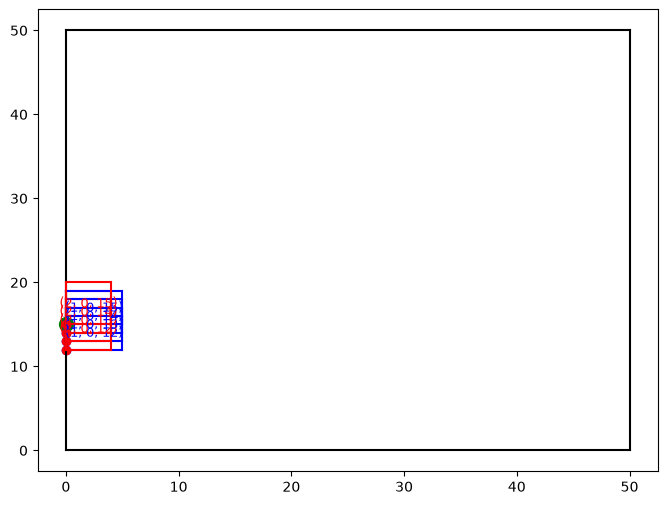

In [31]:
plotar_palete(L,W)
r,s = lista_rs[9]
plt.scatter(x=r, y=s, color="green", s=100)
caixas_sobrepostas = []
for i,p,q in lista_variaveis:
    if ponto_dentro_caixa((r,s),
                        (p,q),
                        l=ls[i-1], w=ws[i-1]):
        plotar_caixa((p,q), ls[i-1], ws[i-1],
                    color="blue" if i==1 else "red",
                    label=f"{i,p, q}") #numero

In [32]:
#sorted((2,0,2), (1,1,2)) # lista de tupla

In [33]:
#plotar_palete(L,W)
n=0
for r, s in lista_rs:
    caixas_sobrepostas = []
    for i,p , q in lista_variaveis:
        if ponto_dentro_caixa((r,s),
                            (p,q),
                            l=ls[i-1], w=ws[i-1]):
            caixas_sobrepostas.append(dict_variaveis[i, p, q]) #slide de dicionario cada tupla em C
    #print(sorted(caixas_sobrepostas))
    #print(sum((caixas_sobrepostas)))
    prob+=sum(caixas_sobrepostas) <=1, f"Restricao 1.{n}"
    n+=1

In [34]:
qtd_maxima_caixas = (L*W)//(l_um *w_um)
#display(prob)
print(qtd_maxima_caixas)

125


In [35]:
print(prob.numVariables())
print(prob.numConstraints())

3280
1681


In [36]:
prob+= sum(dict_variaveis.values()) <= qtd_maxima_caixas, "Restricao_2.0"
display(prob)

Palete_caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_10) + 1*C_(1,_0,_12) + 1*C_(1,_0,_13) + 1*C_(1,_0,_14) + 1*C_(1,_0,_15) + 1*C_(1,_0,_16) + 1*C_(1,_0,_17) + 1*C_(1,_0,_18) + 1*C_(1,_0,_19) + 1*C_(1,_0,_20) + 1*C_(1,_0,_21) + 1*C_(1,_0,_22) + 1*C_(1,_0,_23) + 1*C_(1,_0,_24) + 1*C_(1,_0,_25) + 1*C_(1,_0,_26) + 1*C_(1,_0,_27) + 1*C_(1,_0,_28) + 1*C_(1,_0,_29) + 1*C_(1,_0,_30) + 1*C_(1,_0,_31) + 1*C_(1,_0,_32) + 1*C_(1,_0,_33) + 1*C_(1,_0,_34) + 1*C_(1,_0,_35) + 1*C_(1,_0,_36) + 1*C_(1,_0,_37) + 1*C_(1,_0,_38) + 1*C_(1,_0,_39) + 1*C_(1,_0,_4) + 1*C_(1,_0,_40) + 1*C_(1,_0,_41) + 1*C_(1,_0,_42) + 1*C_(1,_0,_43) + 1*C_(1,_0,_44) + 1*C_(1,_0,_45) + 1*C_(1,_0,_46) + 1*C_(1,_0,_5) + 1*C_(1,_0,_8) + 1*C_(1,_0,_9) + 1*C_(1,_10,_0) + 1*C_(1,_10,_10) + 1*C_(1,_10,_12) + 1*C_(1,_10,_13) + 1*C_(1,_10,_14) + 1*C_(1,_10,_15) + 1*C_(1,_10,_16) + 1*C_(1,_10,_17) + 1*C_(1,_10,_18) + 1*C_(1,_10,_19) + 1*C_(1,_10,_20) + 1*C_(1,_10,_21) + 1*C_(1,_10,_22) + 1*C_(1,_10,_23) + 1*C_(1,_10,_24) + 1*C_(1,_10,_25) 

In [37]:
print(prob.numVariables())
print(prob.numConstraints())

3280
1682


In [38]:
solver = plp.getSolver("PULP_CBC_CMD", timeLimit=None)

In [39]:
prob.solve(solver)

1

In [40]:
display(plp.LpStatus)

{0: 'Not Solved',
 1: 'Optimal',
 -1: 'Infeasible',
 -2: 'Unbounded',
 -3: 'Undefined'}

In [41]:
print(prob.variables())

[C_(1,_0,_0), C_(1,_0,_10), C_(1,_0,_12), C_(1,_0,_13), C_(1,_0,_14), C_(1,_0,_15), C_(1,_0,_16), C_(1,_0,_17), C_(1,_0,_18), C_(1,_0,_19), C_(1,_0,_20), C_(1,_0,_21), C_(1,_0,_22), C_(1,_0,_23), C_(1,_0,_24), C_(1,_0,_25), C_(1,_0,_26), C_(1,_0,_27), C_(1,_0,_28), C_(1,_0,_29), C_(1,_0,_30), C_(1,_0,_31), C_(1,_0,_32), C_(1,_0,_33), C_(1,_0,_34), C_(1,_0,_35), C_(1,_0,_36), C_(1,_0,_37), C_(1,_0,_38), C_(1,_0,_39), C_(1,_0,_4), C_(1,_0,_40), C_(1,_0,_41), C_(1,_0,_42), C_(1,_0,_43), C_(1,_0,_44), C_(1,_0,_45), C_(1,_0,_46), C_(1,_0,_5), C_(1,_0,_8), C_(1,_0,_9), C_(1,_10,_0), C_(1,_10,_10), C_(1,_10,_12), C_(1,_10,_13), C_(1,_10,_14), C_(1,_10,_15), C_(1,_10,_16), C_(1,_10,_17), C_(1,_10,_18), C_(1,_10,_19), C_(1,_10,_20), C_(1,_10,_21), C_(1,_10,_22), C_(1,_10,_23), C_(1,_10,_24), C_(1,_10,_25), C_(1,_10,_26), C_(1,_10,_27), C_(1,_10,_28), C_(1,_10,_29), C_(1,_10,_30), C_(1,_10,_31), C_(1,_10,_32), C_(1,_10,_33), C_(1,_10,_34), C_(1,_10,_35), C_(1,_10,_36), C_(1,_10,_37), C_(1,_10,_3

In [42]:
print(prob.variables()[0].name, prob.variables()[0].varValue)
print(prob.variables()[2].name, prob.variables()[2].varValue)
print(prob.objective.value())


C_(1,_0,_0) 0.0
C_(1,_0,_12) 0.0
124.0


In [43]:
dict_traducao = \
    dict(zip(dict_variaveis.values(),
        dict_variaveis.keys()))
display(dict_traducao)

{C_(1,_0,_0): (1, 0, 0),
 C_(2,_0,_0): (2, 0, 0),
 C_(1,_0,_4): (1, 0, 4),
 C_(2,_0,_4): (2, 0, 4),
 C_(1,_0,_5): (1, 0, 5),
 C_(2,_0,_5): (2, 0, 5),
 C_(1,_0,_8): (1, 0, 8),
 C_(2,_0,_8): (2, 0, 8),
 C_(1,_0,_9): (1, 0, 9),
 C_(2,_0,_9): (2, 0, 9),
 C_(1,_0,_10): (1, 0, 10),
 C_(2,_0,_10): (2, 0, 10),
 C_(1,_0,_12): (1, 0, 12),
 C_(2,_0,_12): (2, 0, 12),
 C_(1,_0,_13): (1, 0, 13),
 C_(2,_0,_13): (2, 0, 13),
 C_(1,_0,_14): (1, 0, 14),
 C_(2,_0,_14): (2, 0, 14),
 C_(1,_0,_15): (1, 0, 15),
 C_(2,_0,_15): (2, 0, 15),
 C_(1,_0,_16): (1, 0, 16),
 C_(2,_0,_16): (2, 0, 16),
 C_(1,_0,_17): (1, 0, 17),
 C_(2,_0,_17): (2, 0, 17),
 C_(1,_0,_18): (1, 0, 18),
 C_(2,_0,_18): (2, 0, 18),
 C_(1,_0,_19): (1, 0, 19),
 C_(2,_0,_19): (2, 0, 19),
 C_(1,_0,_20): (1, 0, 20),
 C_(2,_0,_20): (2, 0, 20),
 C_(1,_0,_21): (1, 0, 21),
 C_(2,_0,_21): (2, 0, 21),
 C_(1,_0,_22): (1, 0, 22),
 C_(2,_0,_22): (2, 0, 22),
 C_(1,_0,_23): (1, 0, 23),
 C_(2,_0,_23): (2, 0, 23),
 C_(1,_0,_24): (1, 0, 24),
 C_(2,_0,_24): (2, 0,

In [44]:
dict_variaveis

{(1, 0, 0): C_(1,_0,_0),
 (2, 0, 0): C_(2,_0,_0),
 (1, 0, 4): C_(1,_0,_4),
 (2, 0, 4): C_(2,_0,_4),
 (1, 0, 5): C_(1,_0,_5),
 (2, 0, 5): C_(2,_0,_5),
 (1, 0, 8): C_(1,_0,_8),
 (2, 0, 8): C_(2,_0,_8),
 (1, 0, 9): C_(1,_0,_9),
 (2, 0, 9): C_(2,_0,_9),
 (1, 0, 10): C_(1,_0,_10),
 (2, 0, 10): C_(2,_0,_10),
 (1, 0, 12): C_(1,_0,_12),
 (2, 0, 12): C_(2,_0,_12),
 (1, 0, 13): C_(1,_0,_13),
 (2, 0, 13): C_(2,_0,_13),
 (1, 0, 14): C_(1,_0,_14),
 (2, 0, 14): C_(2,_0,_14),
 (1, 0, 15): C_(1,_0,_15),
 (2, 0, 15): C_(2,_0,_15),
 (1, 0, 16): C_(1,_0,_16),
 (2, 0, 16): C_(2,_0,_16),
 (1, 0, 17): C_(1,_0,_17),
 (2, 0, 17): C_(2,_0,_17),
 (1, 0, 18): C_(1,_0,_18),
 (2, 0, 18): C_(2,_0,_18),
 (1, 0, 19): C_(1,_0,_19),
 (2, 0, 19): C_(2,_0,_19),
 (1, 0, 20): C_(1,_0,_20),
 (2, 0, 20): C_(2,_0,_20),
 (1, 0, 21): C_(1,_0,_21),
 (2, 0, 21): C_(2,_0,_21),
 (1, 0, 22): C_(1,_0,_22),
 (2, 0, 22): C_(2,_0,_22),
 (1, 0, 23): C_(1,_0,_23),
 (2, 0, 23): C_(2,_0,_23),
 (1, 0, 24): C_(1,_0,_24),
 (2, 0, 24): C_(2,_0,

In [45]:
variaveis_organizadas = []
for variavel in prob.variables():
   # print(variavel.name, variavel.varValue)
   if variavel.varValue > 0:
        var_traduzida = dict_traducao[variavel]
        variaveis_organizadas.append(var_traduzida)
display(variaveis_organizadas)


[(1, 13, 0),
 (1, 13, 12),
 (1, 13, 16),
 (1, 13, 25),
 (1, 13, 29),
 (1, 13, 33),
 (1, 13, 4),
 (1, 13, 42),
 (1, 13, 46),
 (1, 13, 8),
 (1, 18, 0),
 (1, 18, 12),
 (1, 18, 16),
 (1, 18, 4),
 (1, 18, 8),
 (1, 23, 0),
 (1, 23, 12),
 (1, 23, 16),
 (1, 23, 4),
 (1, 23, 8),
 (1, 26, 25),
 (1, 26, 29),
 (1, 26, 33),
 (1, 26, 37),
 (1, 26, 46),
 (1, 28, 0),
 (1, 28, 12),
 (1, 28, 16),
 (1, 28, 4),
 (1, 28, 8),
 (1, 31, 25),
 (1, 31, 29),
 (1, 31, 33),
 (1, 31, 37),
 (1, 31, 46),
 (1, 36, 25),
 (1, 36, 29),
 (1, 36, 33),
 (1, 36, 37),
 (1, 36, 46),
 (1, 37, 0),
 (1, 37, 17),
 (1, 37, 21),
 (1, 37, 4),
 (1, 37, 8),
 (1, 4, 13),
 (1, 4, 17),
 (1, 4, 21),
 (1, 4, 25),
 (1, 4, 29),
 (1, 4, 33),
 (1, 4, 37),
 (1, 4, 41),
 (1, 4, 5),
 (1, 4, 9),
 (1, 41, 25),
 (1, 41, 29),
 (1, 41, 33),
 (1, 41, 37),
 (1, 41, 46),
 (1, 8, 0),
 (2, 0, 0),
 (2, 0, 10),
 (2, 0, 15),
 (2, 0, 20),
 (2, 0, 25),
 (2, 0, 30),
 (2, 0, 35),
 (2, 0, 40),
 (2, 0, 45),
 (2, 0, 5),
 (2, 13, 20),
 (2, 13, 37),
 (2, 17, 20),
 (2, 

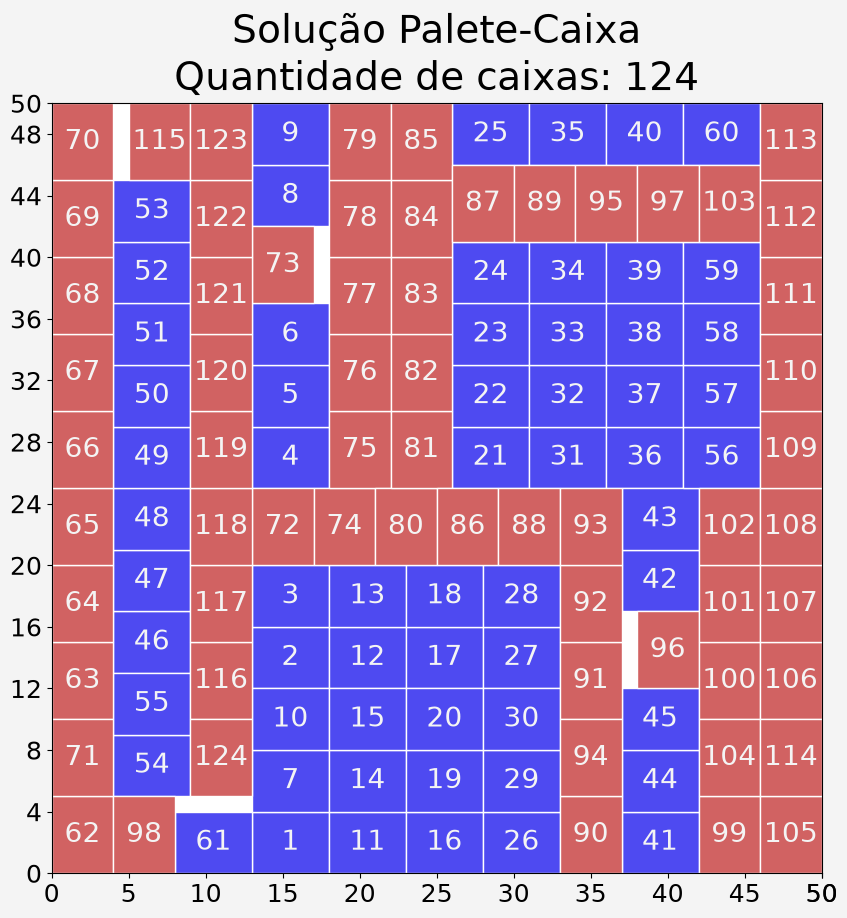

In [46]:
fig, ax = plt.subplots(figsize=(10, 10))
fig.set_facecolor('#f4f4f4')

a = plt.gca()
a.set_xticks(list(range(0, L + 1, l_um)) + [L])
a.set_yticks(list(range(0, W + 1, w_um)) + [W])
a.set_xticklabels(a.get_xticks())
a.set_yticklabels(a.get_yticks())

qtd_caixas = len(variaveis_organizadas)
for indice_caixa, variavel_organizada in enumerate(variaveis_organizadas, 1):
    i, p, q = variavel_organizada
    
    ax.add_patch(plt.Rectangle(xy=(p, q), 
                               width=ls[i - 1], 
                               height=ws[i - 1], 
                               facecolor="#4e4af1" if i == 1 else "#d16262", 
                               edgecolor="white", lw=1,
                               alpha=1,))

    plt.text(x=p + ls[i - 1] / 2, 
             y=q + ws[i - 1] / 2, 
             s=f"{indice_caixa}", 
             fontsize=20,
             color="#f4f4f4",
             ha="center", 
             va="center")

ax.set_title(f"Solução Palete-Caixa\nQuantidade de caixas: {qtd_caixas}",
                fontsize=28)

ax.set_xlim(0, L)
ax.set_ylim(0, W)
ax.set_aspect("equal")

ax.xaxis.set_tick_params(labelsize=18)
ax.yaxis.set_tick_params(labelsize=18)

In [47]:
from copy import deepcopy
solucoes = [deepcopy(variaveis_organizadas)] # senão colocar deepcopy ele poem o endereço da memoria e se houver mudança pode perdar o dado

In [48]:
#restricao 3
from random import random, seed
seed(42)

n = 0
for variavel in prob.variables(): # for percurre as 38 caixas
    if variavel.varValue >0:

        if random()> 0.2:
            continue #vai para proxima variavel

        #print(variavel)
        prob+= variavel ==0, f"Restricao_3.{n}"
        n+=1
display(prob)



Palete_caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_10) + 1*C_(1,_0,_12) + 1*C_(1,_0,_13) + 1*C_(1,_0,_14) + 1*C_(1,_0,_15) + 1*C_(1,_0,_16) + 1*C_(1,_0,_17) + 1*C_(1,_0,_18) + 1*C_(1,_0,_19) + 1*C_(1,_0,_20) + 1*C_(1,_0,_21) + 1*C_(1,_0,_22) + 1*C_(1,_0,_23) + 1*C_(1,_0,_24) + 1*C_(1,_0,_25) + 1*C_(1,_0,_26) + 1*C_(1,_0,_27) + 1*C_(1,_0,_28) + 1*C_(1,_0,_29) + 1*C_(1,_0,_30) + 1*C_(1,_0,_31) + 1*C_(1,_0,_32) + 1*C_(1,_0,_33) + 1*C_(1,_0,_34) + 1*C_(1,_0,_35) + 1*C_(1,_0,_36) + 1*C_(1,_0,_37) + 1*C_(1,_0,_38) + 1*C_(1,_0,_39) + 1*C_(1,_0,_4) + 1*C_(1,_0,_40) + 1*C_(1,_0,_41) + 1*C_(1,_0,_42) + 1*C_(1,_0,_43) + 1*C_(1,_0,_44) + 1*C_(1,_0,_45) + 1*C_(1,_0,_46) + 1*C_(1,_0,_5) + 1*C_(1,_0,_8) + 1*C_(1,_0,_9) + 1*C_(1,_10,_0) + 1*C_(1,_10,_10) + 1*C_(1,_10,_12) + 1*C_(1,_10,_13) + 1*C_(1,_10,_14) + 1*C_(1,_10,_15) + 1*C_(1,_10,_16) + 1*C_(1,_10,_17) + 1*C_(1,_10,_18) + 1*C_(1,_10,_19) + 1*C_(1,_10,_20) + 1*C_(1,_10,_21) + 1*C_(1,_10,_22) + 1*C_(1,_10,_23) + 1*C_(1,_10,_24) + 1*C_(1,_10,_25) 

In [49]:
print(prob.numVariables())
print(prob.numConstraints())

3280
1705


In [50]:
prob.solve(solver)

1

In [51]:
variaveis_organizadas = []
for variavel in prob.variables():
   # print(variavel.name, variavel.varValue)
   if variavel.varValue > 0:
        var_traduzida = dict_traducao[variavel]
        variaveis_organizadas.append(var_traduzida)
display(variaveis_organizadas)

[(1, 0, 10),
 (1, 0, 14),
 (1, 0, 18),
 (1, 0, 22),
 (1, 0, 26),
 (1, 0, 30),
 (1, 0, 34),
 (1, 0, 38),
 (1, 0, 42),
 (1, 0, 46),
 (1, 10, 29),
 (1, 10, 33),
 (1, 10, 37),
 (1, 10, 41),
 (1, 13, 5),
 (1, 14, 13),
 (1, 14, 17),
 (1, 14, 21),
 (1, 14, 25),
 (1, 14, 9),
 (1, 15, 29),
 (1, 15, 33),
 (1, 15, 37),
 (1, 15, 41),
 (1, 18, 5),
 (1, 20, 29),
 (1, 20, 33),
 (1, 20, 37),
 (1, 20, 41),
 (1, 23, 13),
 (1, 23, 17),
 (1, 23, 21),
 (1, 23, 25),
 (1, 23, 5),
 (1, 23, 9),
 (1, 25, 29),
 (1, 25, 33),
 (1, 25, 37),
 (1, 25, 41),
 (1, 28, 0),
 (1, 28, 5),
 (1, 30, 29),
 (1, 30, 33),
 (1, 30, 37),
 (1, 30, 41),
 (1, 33, 0),
 (1, 35, 29),
 (1, 35, 33),
 (1, 35, 37),
 (1, 35, 41),
 (1, 36, 13),
 (1, 36, 17),
 (1, 36, 21),
 (1, 36, 25),
 (1, 36, 9),
 (1, 40, 29),
 (1, 40, 33),
 (1, 40, 37),
 (1, 40, 41),
 (1, 41, 13),
 (1, 41, 17),
 (1, 41, 21),
 (1, 41, 25),
 (1, 41, 5),
 (1, 41, 9),
 (1, 45, 0),
 (1, 45, 29),
 (1, 45, 33),
 (1, 45, 37),
 (1, 45, 41),
 (1, 5, 30),
 (1, 5, 34),
 (1, 5, 38),
 (1

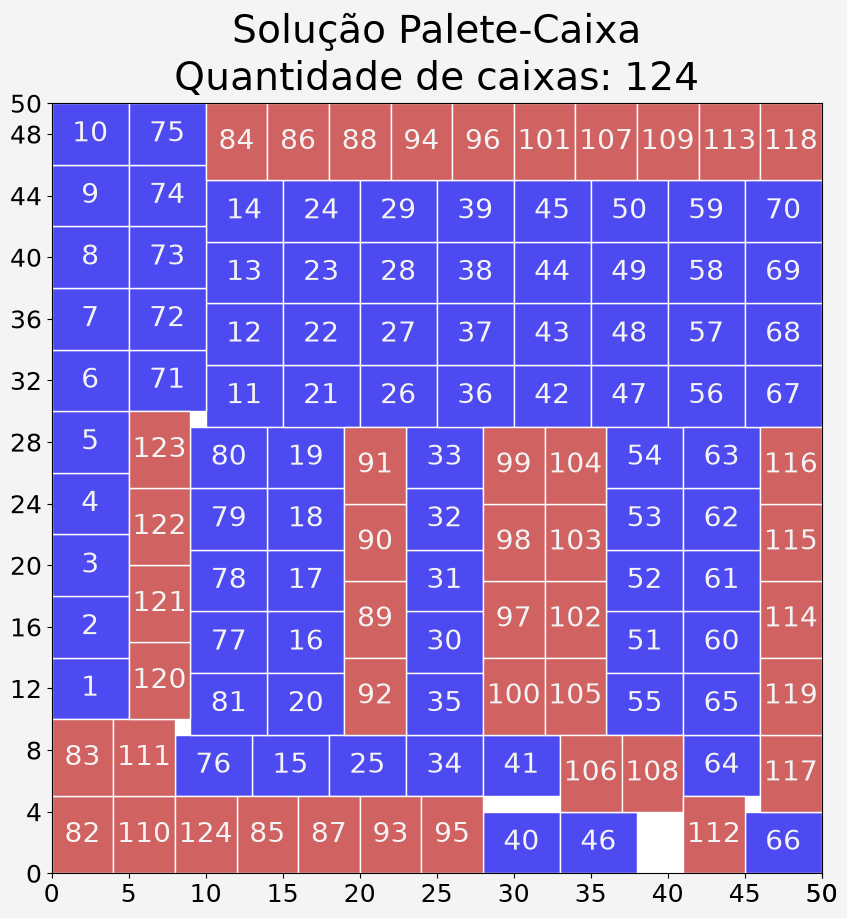

In [52]:
fig, ax = plt.subplots(figsize=(10, 10))
fig.set_facecolor('#f4f4f4')

a = plt.gca()
a.set_xticks(list(range(0, L + 1, l_um)) + [L])
a.set_yticks(list(range(0, W + 1, w_um)) + [W])
a.set_xticklabels(a.get_xticks())
a.set_yticklabels(a.get_yticks())

qtd_caixas = len(variaveis_organizadas)
for indice_caixa, variavel_organizada in enumerate(variaveis_organizadas, 1):
    i, p, q = variavel_organizada
    
    ax.add_patch(plt.Rectangle(xy=(p, q), 
                               width=ls[i - 1], 
                               height=ws[i - 1], 
                               facecolor="#4e4af1" if i == 1 else "#d16262", 
                               edgecolor="white", lw=1,
                               alpha=1,))

    plt.text(x=p + ls[i - 1] / 2, 
             y=q + ws[i - 1] / 2, 
             s=f"{indice_caixa}", 
             fontsize=20,
             color="#f4f4f4",
             ha="center", 
             va="center")

ax.set_title(f"Solução Palete-Caixa\nQuantidade de caixas: {qtd_caixas}",
                fontsize=28)

ax.set_xlim(0, L)
ax.set_ylim(0, W)
ax.set_aspect("equal")

ax.xaxis.set_tick_params(labelsize=18)
ax.yaxis.set_tick_params(labelsize=18)

In [53]:
solucoes.append(deepcopy(variaveis_organizadas))

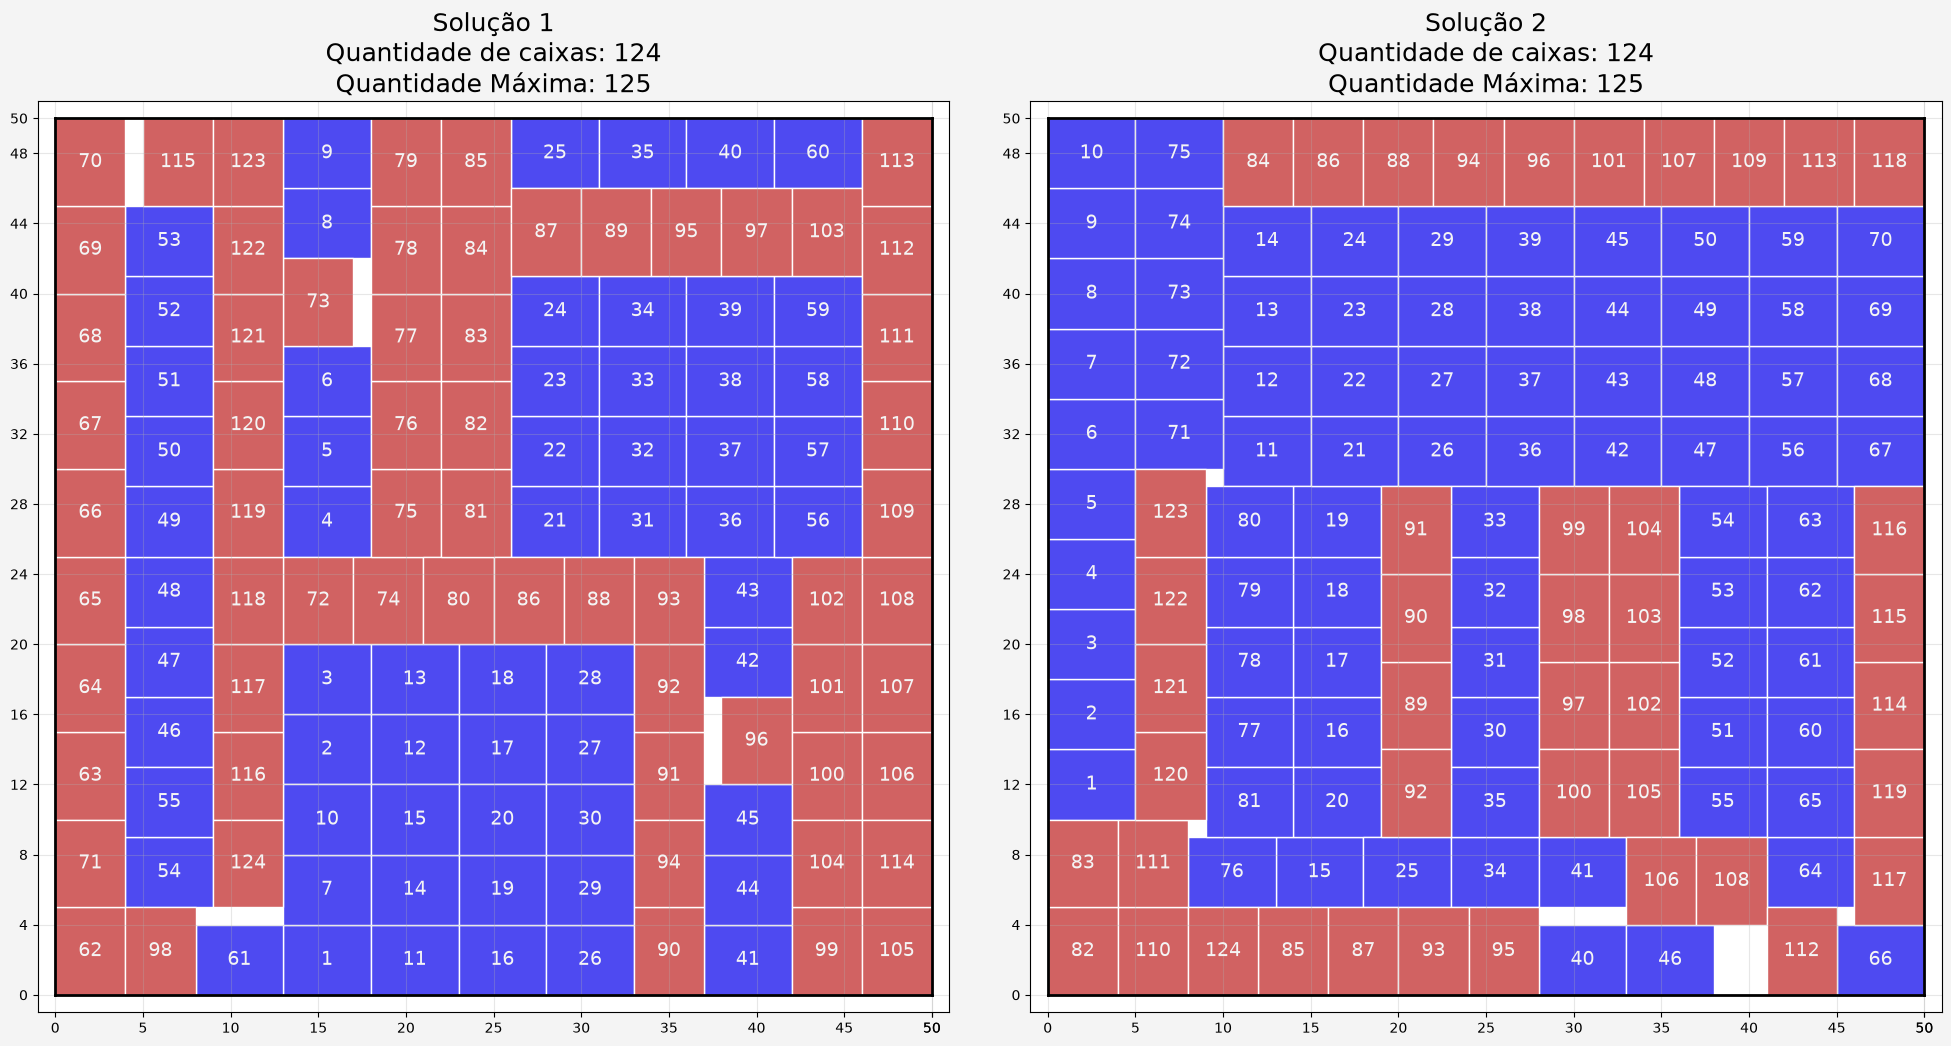

In [54]:
from matplotlib.figure import Figure
from matplotlib.axes import Axes
import numpy as np

fig: Figure
axes: np.ndarray[Axes]

fig, axes = plt.subplots(ncols=2, figsize=(20, 10))
fig.set_facecolor('#f4f4f4')

for idx, (ax, solucao) in enumerate(zip(axes, solucoes[:2]), start=1):
    ax.set_xticks(list(range(0, L + 1, l_um)) + [L])
    ax.set_yticks(list(range(0, W + 1, w_um)) + [W])
    ax.set_xlim(-1, L + 1)
    ax.set_ylim(-1, W + 1)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)

    # borda da palete
    for x0, y0, x1, y1 in [(0, 0, L, 0), (0, 0, 0, W), (0, W, L, W), (L, 0, L, W)]:
        ax.plot([x0, x1], [y0, y1], 'k-', lw=2)

    for n_caixa, (i, p, q) in enumerate(solucao, start=1):
        ax.add_patch(plt.Rectangle(
            xy=(p, q),
            width=ls[i - 1],
            height=ws[i - 1],
            facecolor="#4e4af1" if i == 1 else "#d16262",
            edgecolor="white",
            lw=1
        ))
        ax.text(
            p + ls[i - 1] / 2,
            q + ws[i - 1] / 2,
            str(n_caixa),
            ha="center",
            va="center",
            fontsize=14,
            color="#f4f4f4"
        )

    ax.set_title(f"Solução {idx}\nQuantidade de caixas: {len(solucao)}\nQuantidade Máxima: {qtd_maxima_caixas}", fontsize=18)

plt.tight_layout()
plt.show()